## Sel 1 — Mount Google Drive
**Tahap:** persiapan. Menyambungkan Colab ke Drive agar data zip hasil Macenko bisa dibaca dan semua hasil tersimpan permanen.
- Izinkan akses Drive saat jendela izin muncul; wajib dijalankan di setiap runtime baru.
- **Cek hasil:** muncul `Mounted at /content/drive`.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Sel 2 — Konfigurasi
**Tahap:** persiapan. Satu-satunya tempat pengaturan; semua sel berikutnya membaca objek `A` yang dibuat di sini.
- **Tidak ada CAP**: seluruh patch lolos filter dipakai (Subbab 3.7).
- **KONFIRMASI_HOLDOUT** — biarkan `False` sampai CV selesai.
- **DATA_ROOT** — folder induk yang berisi folder hasil Macenko. Kosongkan agar dicari otomatis.
- **ZIP_SUBDIR** — kosongkan agar dicari otomatis (`Patches_Macenko`, lalu `Patches_Macenko_paper`).
- **TISSUE_SUMMARY / PATCH_SUMMARY** — path `summary_tissue_detection.csv` dan `patch_summary.csv` (untuk waktu praproses di tabel S4). Kosongkan jika ada di `DATA_ROOT/Tissue_Detection/` dan `DATA_ROOT/Patches/`.
- **EXTRACT_BATCH** — turunkan ke 64 atau 32 hanya jika muncul `CUDA out of memory`.
- **SKIP_VERIFY** — `True` melewati verifikasi isi fitur lama (lebih cepat, kurang aman).
- **Folder hasil:** `WORK = MyDrive/EGFR_DenseNet201_ABMIL_py` (terpisah dari folder temanmu).
- **Cek hasil:** ringkasan pengaturan, nama GPU, ruang Drive.

In [ ]:
KONFIRMASI_HOLDOUT = True   #@param {type:"boolean"}
DATA_ROOT = "/content/drive/MyDrive/TCGA-LUAD-WSI"  #@param {type:"string"}
ZIP_SUBDIR = ""             #@param {type:"string"}
TISSUE_SUMMARY = ""         #@param {type:"string"}
PATCH_SUMMARY = ""          #@param {type:"string"}
EXTRACT_BATCH = 128         #@param [32, 64, 128] {type:"raw"}
SKIP_VERIFY = False         #@param {type:"boolean"}
SCAN_THREADS = 1            # Scan ZIP serial agar akses Google Drive lebih stabil

import os, shutil, torch
from types import SimpleNamespace
WORK = "/content/drive/MyDrive/EGFR_DenseNet201_ABMIL_py"     # folder hasil di Drive (milikmu)

_names = [ZIP_SUBDIR] if ZIP_SUBDIR else ["Patches_Macenko", "Patches_Macenko_paper"]
_sub = next((n for n in _names if DATA_ROOT and os.path.isdir(os.path.join(DATA_ROOT, n))), None)
if DATA_ROOT and _sub is None:
    raise RuntimeError(f"Folder hasil Macenko {_names} tidak ada di {DATA_ROOT}. Periksa DATA_ROOT / ZIP_SUBDIR, atau kosongkan DATA_ROOT agar dicari otomatis.")

# Objek pengaturan yang dibaca seluruh sel tahap (menggantikan argumen command-line versi lama)
A = SimpleNamespace(
    confirm_holdout=KONFIRMASI_HOLDOUT, reeval_test=False,
    data_root=DATA_ROOT or None, work_dir=WORK, zip_subdir=ZIP_SUBDIR or None,
    tissue_summary=TISSUE_SUMMARY or None, patch_summary=PATCH_SUMMARY or None,
    fp32=False, extract_batch=EXTRACT_BATCH, workers=3, io_threads=12, scan_threads=SCAN_THREADS,
    skip_verify=SKIP_VERIFY, max_epoch=50, patience=10, wd=1e-5, focal_alpha="none",
    tag="v3", skip_count_check=False,
)

print("Patch          : SEMUA patch lolos filter (tanpa cap)")
print("DATA_ROOT      :", DATA_ROOT or "(otomatis)", "| folder Macenko:", _sub or "(otomatis)")
print("Folder hasil   :", WORK)
print("EXTRACT_BATCH  :", EXTRACT_BATCH, "| SCAN_THREADS:", SCAN_THREADS)
print("Verifikasi fitur lama:", "DILEWATI" if SKIP_VERIFY else "aktif")
print("Hold-out       :", "TERBUKA (run final)" if KONFIRMASI_HOLDOUT else "terkunci")
print("Cek pengaturan :", KONFIRMASI_HOLDOUT, A.confirm_holdout, A.reeval_test, "(harus: True True False)")
if torch.cuda.is_available():
    print("GPU            :", torch.cuda.get_device_name(0), "| VRAM %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 2**30))
else:
    print("PERINGATAN     : GPU belum aktif. Runtime > Change runtime type > A100 GPU + High-RAM, lalu jalankan ulang dari Sel 1.")
try:
    print("Ruang Drive    : %.1f GB kosong (butuh ≈ 7 GB)" % (shutil.disk_usage("/content/drive/MyDrive").free / 2**30))
except Exception as e:
    print("Ruang Drive tidak terbaca:", e)

Patch          : SEMUA patch lolos filter (tanpa cap)
DATA_ROOT      : /content/drive/MyDrive/TCGA-LUAD-WSI | folder Macenko: Patches_Macenko
Folder hasil   : /content/drive/MyDrive/EGFR_DenseNet201_ABMIL_py
EXTRACT_BATCH  : 128 | SCAN_THREADS: 1
Verifikasi fitur lama: aktif
Hold-out       : TERBUKA (run final)
Cek pengaturan : True True False (harus: True True False)
GPU            : Tesla T4 | VRAM 14.6 GB
Ruang Drive    : 223.8 GB kosong (butuh ≈ 7 GB)


## Sel 3 — Cek cepat data (sebelum Scan)
**Tahap:** pemeriksaan. Ringan, **tanpa GPU dan tanpa menulis apa pun** ke Drive.
- Kolom `macenko_summary.csv` lengkap, semua `status` = `OK`, nilai `split` hanya `train`/`test`.
- ZIP: **train 40 Mutant / 120 Wildtype, test 10 / 30** (total 200).
- Jumlah patch per WSI, total patch, perkiraan ukuran fitur (GB), RAM, dan ruang Drive.
- Ada tidaknya log waktu praproses untuk tabel S4.
- **Cek hasil:** semua baris `OK`. Jika ada `WARN` / `GAGAL`, selesaikan dulu sebelum Scan.

In [ ]:
import glob, os, shutil, zipfile, pandas as pd
NAMES = [ZIP_SUBDIR] if ZIP_SUBDIR else ["Patches_Macenko", "Patches_Macenko_paper"]
base = DATA_ROOT
if not base:
    cand = [p for n in NAMES for p in glob.glob(f"/content/drive/MyDrive/{n}") + glob.glob(f"/content/drive/MyDrive/*/{n}")]
    base = os.path.dirname(cand[0]) if cand else ""
sub = next((n for n in NAMES if os.path.isdir(os.path.join(base, n))), NAMES[0])
zdir = os.path.join(base, sub)
ok = os.path.isdir(zdir)
print("Folder data :", zdir, "| ada:", ok)
if ok and ("sample" in sub.lower() or "orig" in sub.lower()):
    print("GAGAL: folder ini tampak SAMPEL patch asli, bukan hasil Macenko penuh."); ok = False

if ok:
    sp = os.path.join(zdir, "macenko_summary.csv")
    if not os.path.exists(sp):
        print("GAGAL: macenko_summary.csv tidak ada"); ok = False
    else:
        S = pd.read_csv(sp)
        need = {"slide", "patches_in", "dropped", "label", "split", "status", "time_sec"}
        miss = need - set(S.columns)
        print("Kolom summary:", S.columns.tolist())
        print("Kolom yang hilang:", sorted(miss) if miss else "tidak ada")
        if not miss:
            print("Status:", S.status.value_counts().to_dict(), "| WARN kalau ada selain OK" if (S.status != "OK").any() else "(semua OK)")
            sv = set(S.split.astype(str).str.lower())
            print("Nilai split:", sorted(sv), "| WARN: hanya boleh train/test" if sv - {"train", "test"} else "(hanya train/test)")
            print("Summary per split x label:"); print(S.groupby(["split", "label"]).size().to_string())
            n = S.patches_in - S.dropped
            print("Jumlah patch (patches_in - dropped): rata-rata %.0f, min %d, maks %d" % (n.mean(), n.min(), n.max()))
            gb = n.sum() * 1920 * 2 / 2**30; free = shutil.disk_usage('/content/drive/MyDrive').free / 2**30
            print(f"Total patch: {int(n.sum()):,} | fitur fp16 ≈ {gb:.1f} GB | bag terbesar {int(n.max()):,} patch")
            print(f"Ruang Drive kosong: {free:.0f} GB ->", 'CUKUP' if free > gb * 1.1 else 'TIDAK CUKUP (tambah kapasitas Drive / Colab Pro, Subbab 3.12.1)')
            try:
                import psutil; print(f"RAM kosong sesi ini: {psutil.virtual_memory().available / 2**30:.0f} GB")
            except ImportError: pass


            if n.max() <= 100:
                print("WARN: semua WSI <= 100 patch -> kemungkinan ini folder SAMPEL, bukan hasil Macenko penuh.")
        ok = ok and not miss

if ok:
    zips = sorted(glob.glob(os.path.join(zdir, "**", "*.zip"), recursive=True))
    rel = [os.path.relpath(z, zdir).replace("\\", "/") for z in zips]
    tab = pd.Series([("/".join(r.split("/")[:2]) if r.count("/") >= 2 else "(di luar train/test)") for r in rel]).value_counts().sort_index()
    print("\nJumlah ZIP per folder:"); print(tab.to_string(), f"\nTotal ZIP: {len(zips)}")
    harapan = {"train/Mutant": 40, "train/Wildtype": 120, "test/Mutant": 10, "test/Wildtype": 30}
    for k, v in harapan.items():
        print(f"  {k:<16s} terbaca {int(tab.get(k, 0)):>3d} | harapan {v:>3d} | {'OK' if int(tab.get(k, 0)) == v else 'WARN'}")
    if "(di luar train/test)" in tab.index: print("WARN: ada ZIP di luar train/ dan test/ -> Scan akan berhenti; pindahkan/hapus dulu.")
    print("\nUji buka 1 ZIP per kelompok:")
    for k in harapan:
        z = next((z for z, r in zip(zips, rel) if r.startswith(k + "/")), None)
        if z is None: print(f"  {k}: tidak ada ZIP"); continue
        try:
            with zipfile.ZipFile(z) as zf:
                imgs = [n for n in zf.namelist() if n.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff"))]
            print(f"  {k}: {os.path.basename(z)} -> {len(imgs):,} gambar")
        except Exception as e:
            print(f"  {k}: GAGAL membuka {os.path.basename(z)}: {e!r}")
    print("\nLog waktu praproses untuk tabel S4 (macenko_summary.csv sudah otomatis):")
    for rel_p, custom in {"Tissue_Detection/summary_tissue_detection.csv": TISSUE_SUMMARY, "Patches/patch_summary.csv": PATCH_SUMMARY}.items():
        p = custom or os.path.join(base, rel_p)
        print(f"  {'OK       ' if os.path.exists(p) else 'TIDAK ADA'} {p}")
    print("  Jika ada TIDAK ADA: isi TISSUE_SUMMARY / PATCH_SUMMARY di sel 2 (tabel S4 akan ditandai tidak lengkap).")
else:
    print("\nPemeriksaan dihentikan: perbaiki DATA_ROOT / berkas di atas lebih dulu.")

Folder data : /content/drive/MyDrive/TCGA-LUAD-WSI/Patches_Macenko | ada: True
Kolom summary: ['slide', 'patches_in', 'norm_patch', 'norm_slide_fallback', 'dropped', 'sample_orig', 'size_mb', 'status', 'label', 'split', 'time_sec']
Kolom yang hilang: tidak ada
Status: {'OK': 200} (semua OK)
Nilai split: ['test', 'train'] (hanya train/test)
Summary per split x label:
split  label   
test   Mutant       10
       Wildtype     30
train  Mutant       40
       Wildtype    120
Jumlah patch (patches_in - dropped): rata-rata 57896, min 2115, maks 165616
Total patch: 11,579,207 | fitur fp16 ≈ 41.4 GB | bag terbesar 165,616 patch
Ruang Drive kosong: 184 GB -> CUKUP
RAM kosong sesi ini: 11 GB

Jumlah ZIP per folder:
test/Mutant        10
test/Wildtype      30
train/Mutant       40
train/Wildtype    120 
Total ZIP: 200
  train/Mutant     terbaca  40 | harapan  40 | OK
  train/Wildtype   terbaca 120 | harapan 120 | OK
  test/Mutant      terbaca  10 | harapan  10 | OK
  test/Wildtype    terbaca  30

## Sel 4 — Fondasi: impor, konstanta, pembaca ZIP, katalog & split
**Tahap:** fondasi (definisi fungsi + penyiapan folder hasil). Sel ini terdiri dari tiga bagian kode yang saling bergantung, dijalankan sekaligus:
1. **Impor & konstanta** — pustaka, seed 42, grid tuning (Tabel 3.4), versi format cache.
2. **Pembaca ZIP** — membaca patch langsung dari ZIP secara paralel (tanpa `ZipFile`).
3. **Katalog, label, dan split** — membaca `macenko_summary.csv`, mencocokkan dengan daftar ZIP, membuat hold-out (`test/`) dan 5-fold stratified (seed 42) pada `train/`, lalu **membuat folder hasil `01`–`04`** di Drive.
- **Masukan:** `A` dari Sel 2, data Macenko di Drive.
- **Keluaran:** fungsi dasar; folder `03_hasil_cross_validation/`, `04_hasil_holdout_dan_efisiensi/` (untuk tahap CV dan hold-out), serta `00_BACA_SAYA.txt` di folder kerja.
- **Cek hasil:** baris `DATA_ROOT=... | WORK=...`. Tidak ada error.

In [ ]:
# ======================================================================
# FONDASI A — Impor, konstanta, fungsi bantu
# ======================================================================
import os, re, io, sys, json, gzip, time, math, zlib, struct, zipfile, hashlib, argparse, itertools, random, warnings, shutil
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, roc_curve)
from scipy.stats import wilcoxon

try:
    import cv2
    cv2.setNumThreads(1)
    def decode_png(raw):
        im = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR)
        return None if im is None else im[:, :, ::-1]                       # BGR -> RGB
except ImportError:
    from PIL import Image
    def decode_png(raw):
        return np.asarray(Image.open(io.BytesIO(raw)).convert("RGB"))

try:
    import torch, torch.nn as nn, torch.nn.functional as F, torch.utils.data as tud, torchvision
    HAVE_TORCH = True
except ImportError:
    HAVE_TORCH = False

# ============================== KONSTANTA ==============================
SEED = 42
ZIP_SUBDIR_DEFAULT = "Patches_Macenko"
ZIP_SUBDIR_ALT = "Patches_Macenko_paper"                                            # nama folder keluaran notebook praproses
VALID_SPLITS = {"train", "test"}
IMG_EXT = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}
EXCL_RE = re.compile(r"thumb|mask|overlay|reference|referensi|visual", re.I)       # berkas non-patch di dalam zip
CASE_RE = re.compile(r"TCGA-[A-Z0-9]{2}-[A-Z0-9]{4}", re.I)
EXPECTED_ALL, EXPECTED_TEST = (200, 50), (40, 10)                                   # (case, Mutant) menurut proposal
BACKBONE_TAG = "densenet201_imagenet1k_v1"
PREP_TAG = "imagenet-meanstd_noresize_v2"
FORMAT_VER = 2                                                                      # versi format cache seleksi/fitur
HIDDEN_GRID, ATTN_GRID, DROP_GRID, LR_GRID = [128, 256], [64, 128], [0.10, 0.25, 0.50], [1e-4, 5e-5]   # Tabel 3.4


def log(*a):
    print(time.strftime("%H:%M:%S"), *a, flush=True)

def fail(msg):
    raise RuntimeError("\nERROR: " + msg)

def atomic_json(obj, path, **kw):
    tmp = path + ".tmp"
    with open(tmp, "w") as f: json.dump(obj, f, **kw)
    os.replace(tmp, path)

def require_torch(need_cuda=True):
    if not HAVE_TORCH: fail("PyTorch tidak ditemukan. Jalankan di Colab.")
    if need_cuda and not torch.cuda.is_available():
        fail("Tahap ini butuh GPU. Runtime > Change runtime type > T4 GPU, lalu jalankan ulang (hasil sebelumnya tidak diulang).")


# ======================================================================
# FONDASI B — Pembaca ZIP paralel
# ======================================================================
# ============================== PEMBACA ZIP (paralel, tanpa ZipFile) ==============================
def pread_full(fd, n, off):
    out, got = [], 0
    while got < n:
        b = os.pread(fd, n - got, off + got)
        if not b: break
        out.append(b); got += len(b)
    return b"".join(out)

def read_member(fd, fname, off, csz, ctype):
    """Baca 1 anggota zip lewat pread (aman dipakai paralel antar-thread). off = header_offset ZipInfo."""
    guess = 30 + len(fname.encode("utf-8")) + 256
    buf = pread_full(fd, guess + csz, off)
    if len(buf) < 30 or buf[:4] != b"PK\x03\x04": raise OSError(f"header lokal zip tidak valid: {fname}")
    fnlen, exlen = struct.unpack("<HH", buf[26:30]); start = 30 + fnlen + exlen
    if len(buf) < start + csz: buf = pread_full(fd, start + csz, off)
    raw = buf[start:start + csz]
    if len(raw) != csz: raise OSError(f"data terpotong: {fname}")
    if ctype == zipfile.ZIP_STORED: return raw
    if ctype == zipfile.ZIP_DEFLATED: return zlib.decompress(raw, -15)
    raise NotImplementedError(f"metode kompresi zip {ctype} belum didukung")

def fetch_patch(fd, fname, off, csz, ctype):
    img = decode_png(read_member(fd, fname, off, csz, ctype))
    if img is None or img.shape != (224, 224, 3):
        raise ValueError(f"patch tidak valid / bukan 224x224x3 (proposal: tanpa resize): {fname}")
    return img


# ======================================================================
# FONDASI C — Katalog data, label, split pasien, jalur folder
# ======================================================================
# ============================== DATA, LABEL, SPLIT ==============================
def zip_subdir_in(root):
    """Nama subfolder hasil Macenko di <root> (None bila tidak ada)."""
    names = [A.zip_subdir] if A.zip_subdir else [ZIP_SUBDIR_DEFAULT, ZIP_SUBDIR_ALT]
    return next((n for n in names if os.path.isdir(os.path.join(root, n))), None)


def find_data_root():
    if A.data_root: return A.data_root
    base = "/content/drive/MyDrive"
    if not os.path.isdir(base):
        fail("Google Drive belum ter-mount. Jalankan di sel notebook:\n  from google.colab import drive; drive.mount('/content/drive')")
    cands = [base] + [os.path.join(base, x) for x in sorted(os.listdir(base))]
    found = [c for c in cands if zip_subdir_in(c)]
    if not found: fail(f"Folder '{ZIP_SUBDIR_DEFAULT}' / '{ZIP_SUBDIR_ALT}' tidak ditemukan di MyDrive (kedalaman 1). Pakai --data-root <folder induk> atau --zip-subdir.")
    if len(found) > 1: log("Beberapa kandidat DATA_ROOT, dipakai yang pertama:", found)
    return found[0]

def init_paths():
    global DATA_ROOT, ZIP_DIR, WORK, DIR_SPLIT, DIR_PATCHLIST, DIR_FEAT, DIR_FEATFILES, DIR_CV, DIR_HOLD, CAP_TAG, PREC
    DATA_ROOT = find_data_root(); sub = zip_subdir_in(DATA_ROOT)
    if sub is None: fail(f"Subfolder hasil Macenko tidak ada di {DATA_ROOT} (dicari: {A.zip_subdir or [ZIP_SUBDIR_DEFAULT, ZIP_SUBDIR_ALT]}).")
    if "sample" in sub.lower() or "orig" in sub.lower():
        fail(f"Folder '{sub}' tampak seperti sampel patch ASLI (bukan hasil Macenko penuh). Pakai folder zip hasil Macenko.")
    ZIP_DIR = os.path.join(DATA_ROOT, sub)
    WORK = A.work_dir
    if os.path.abspath(WORK).startswith(os.path.abspath(DATA_ROOT) + os.sep):
        fail("--work-dir tidak boleh berada di dalam folder data temanmu.")
    CAP_TAG = "all"; PREC = "fp32" if A.fp32 else "amp16"
    DIR_SPLIT     = WORK                                       # splits.json, inventaris_patch.csv (nama lama, tidak diganti)
    DIR_PATCHLIST = f"{WORK}/selection_{CAP_TAG}"              # cache daftar patch tiap WSI (nama lama)
    DIR_FEAT      = WORK                                       # log timings_extraction_*.csv (nama lama)
    DIR_FEATFILES = f"{WORK}/features_{CAP_TAG}_{PREC}"        # 1 berkas .pt per WSI (nama lama)
    DIR_CV        = f"{WORK}/03_hasil_cross_validation"        # hasil 5-fold (S1, tuning, S2) + tabel + Wilcoxon
    DIR_HOLD      = f"{WORK}/04_hasil_holdout_dan_efisiensi"   # hasil akhir S3, model final, ROC, tabel S4
    for d in (WORK, DIR_PATCHLIST, DIR_FEATFILES, DIR_CV, DIR_HOLD): os.makedirs(d, exist_ok=True)
    readme = f"{WORK}/00_BACA_SAYA.txt"
    if not os.path.exists(readme):
        with open(readme, "w", encoding="utf-8") as f:
            f.write("ISI FOLDER HASIL PENELITIAN (DenseNet201 frozen + ABMIL, prediksi mutasi EGFR)\n\n"
                    "(folder kerja langsung)          : splits.json, inventaris_patch.csv, selection_all/ (cache daftar patch), features_all_amp16/ (fitur .pt per WSI), timings_extraction_all_amp16.csv\n"
                                        "03_hasil_cross_validation/      : cv_results_*.json, tabel_S1/tuning/S2_*.csv, wilcoxon_S1/S2_*.csv\n"
                    "04_hasil_holdout_dan_efisiensi/ : final_result_*.json, final_model_*.pt, holdout_predictions_*.csv, attention_check_*.csv, hasil_test_*.png, efisiensi_komputasi_*.csv\n")
    log(f"DATA_ROOT={DATA_ROOT} | WORK={WORK} | patch=SEMUA (tanpa cap) | presisi ekstraksi={PREC}")

def cid_of(text):
    m = CASE_RE.search(str(text)); return m.group(0).upper() if m else None

def lab_of(s):
    s = str(s).strip().lower()
    return 1 if s.startswith("mut") else (0 if s.startswith("wild") else None)

def load_catalog():
    """Baca macenko_summary.csv + daftar zip, lalu silang-periksa (folder vs summary). Mengembalikan (cat, zip_of)."""
    sp = f"{ZIP_DIR}/macenko_summary.csv"
    if not os.path.exists(sp): fail(f"{sp} tidak ada.")
    S = pd.read_csv(sp)
    miss = {"slide", "patches_in", "dropped", "label", "split", "status", "time_sec"} - set(S.columns)
    if miss: fail(f"Kolom summary hilang: {sorted(miss)}")
    S["case_id"] = S.slide.map(cid_of)
    if S.case_id.isna().any() or not S.case_id.is_unique: fail("case_id di summary tidak terbaca/ganda (proposal: 1 WSI per case).")
    if not (S.status == "OK").all(): fail(f"Ada WSI berstatus bukan OK di summary: {S[S.status != 'OK'].slide.tolist()[:3]}")
    S["y"] = S.label.map(lab_of)
    if S.y.isna().any(): fail("Ada label di summary yang tidak dikenali (harus Mutant / Wildtype).")
    S["y"] = S.y.astype(int); S["split"] = S.split.astype(str).str.lower()
    bad_split = sorted(set(S.split) - VALID_SPLITS)
    if bad_split: fail(f"Kolom split di summary hanya boleh 'train' / 'test'; ditemukan nilai lain: {bad_split}")

    zip_of = {}
    for zp in sorted(Path(ZIP_DIR).rglob("*.zip")):
        rel = zp.relative_to(ZIP_DIR).as_posix(); cid = cid_of(rel) or zp.stem
        if cid in zip_of: fail(f"Case {cid} punya lebih dari satu zip:\n  {zip_of[cid]}\n  {rel}")
        zip_of[cid] = rel
    if set(zip_of) != set(S.case_id):
        fail(f"Daftar zip tidak sama dengan summary. Hanya di zip: {sorted(set(zip_of) - set(S.case_id))[:3]} | "
             f"hanya di summary: {sorted(set(S.case_id) - set(zip_of))[:3]}")
    for r in S.itertuples():                                         # silang-periksa folder vs summary
        parts = zip_of[r.case_id].split("/")
        if len(parts) < 3: fail(f"Struktur folder tak terduga: {zip_of[r.case_id]} (diharapkan <split>/<label>/<slide>.zip)")
        if parts[0].lower() != r.split: fail(f"Split folder ({parts[0]}) != summary ({r.split}) untuk {r.case_id}")
        if lab_of(parts[1]) != r.y: fail(f"Label folder ({parts[1]}) != summary ({r.label}) untuk {r.case_id}")
    n, nm = len(S), int(S.y.sum())
    log(f"Katalog: {n} WSI, Mutant {nm}, Wild Type {n - nm} | split: {S.split.value_counts().to_dict()}")
    log("Jumlah zip per split x kelas (harus train 40/120, test 10/30):\n" + pd.crosstab(S.split, S.y.map({1: "Mutant", 0: "Wildtype"}), margins=True).to_string())
    vdir = f"{ZIP_DIR}/validation"
    if os.path.isdir(vdir): log(f"Folder validation/ ({len(os.listdir(vdir))} berkas) hanya QC, TIDAK dipakai model (split tetap train/test).")
    if not A.skip_count_check:
        if (n, nm) != EXPECTED_ALL: fail(f"Terbaca {n} case ({nm} Mutant); proposal: {EXPECTED_ALL[0]} case ({EXPECTED_ALL[1]} Mutant). Pakai --skip-count-check jika sengaja.")
        t = S[S.split == "test"]
        if (len(t), int(t.y.sum())) != EXPECTED_TEST: fail(f"Hold-out terbaca {len(t)} case ({int(t.y.sum())} Mutant); harapan {EXPECTED_TEST}.")
    return S.sort_values("case_id").reset_index(drop=True), zip_of

def build_splits(cat):
    test = sorted(cat.case_id[cat.split == "test"]); dev = sorted(cat.case_id[cat.split == "train"])
    y = dict(zip(cat.case_id, cat.y)); dev_y = np.array([y[c] for c in dev]); dev_a = np.array(dev)
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    folds = [{"train": dev_a[tr].tolist(), "val": dev_a[va].tolist()} for tr, va in skf.split(dev_a, dev_y)]
    new = {"source": "folder train/test praproses bersama", "test": test, "dev": dev, "folds": folds}
    path = f"{DIR_SPLIT}/splits.json"
    if os.path.exists(path):
        old = json.load(open(path))
        if old["test"] != test or old["dev"] != dev or old["folds"] != folds:
            fail(f"{path} tidak cocok dengan data/split saat ini (mungkin dibuat oleh notebook lain). Hapus berkas itu (dan cv_results_*.json) lalu ulangi.")
    else:
        atomic_json(new, path, indent=1); log("Split disimpan ke", path)
    # validasi ketat
    sd, st = set(dev), set(test)
    assert sd.isdisjoint(st) and sd | st == set(cat.case_id) and len(sd) == len(dev) and len(st) == len(test), "split tidak konsisten"
    seen = []
    for i, f in enumerate(folds, 1):
        tr, va = set(f["train"]), set(f["val"])
        assert tr.isdisjoint(va) and tr | va == sd and not (tr | va) & st, f"fold {i} tidak valid"
        assert {y[c] for c in tr} == {0, 1} and {y[c] for c in va} == {0, 1}, f"fold {i}: train/val harus memuat kedua kelas"
        seen += va
    assert sorted(seen) == sorted(dev), "tiap case development harus menjadi validasi tepat sekali"
    cnt = lambda ids: f"{len(ids)} case (Mutant {sum(y[c] for c in ids)})"
    log("Hold-out:", cnt(test), "| Development:", cnt(dev))
    for i, f in enumerate(folds, 1): log(f"  Fold {i}: train {cnt(f['train'])} | val {cnt(f['val'])}")
    return new


init_paths()   # buat folder hasil 01–04 di Drive

14:25:44 DATA_ROOT=/content/drive/MyDrive/TCGA-LUAD-WSI | WORK=/content/drive/MyDrive/EGFR_DenseNet201_ABMIL_py | patch=SEMUA (tanpa cap) | presisi ekstraksi=amp16


## Sel 5 — Tahap 1: Scan ZIP & seleksi patch (CPU)
**Tahap 1.** Membaca `macenko_summary.csv` dan daftar ZIP, mencocokkan keduanya, membuat split pasien, lalu mendaftar **seluruh** patch tiap WSI (tanpa cap). **Belum ada ekstraksi fitur.**
- Hold-out = folder `test/`; 5-fold stratified (seed 42) pada `train/`.
- Berhenti dengan `ERROR:` jika: kolom summary hilang, status bukan OK, nilai split bukan `train`/`test`, jumlah case/Mutant tidak 200/50 (hold-out 40/10), atau jumlah patch di ZIP ≠ summary.
- Melaporkan persentil patch/WSI, total patch, ukuran fitur (GB), kecukupan ruang Drive, dan perkiraan kebutuhan memori GPU/RAM untuk CV.
- **Hasil (di folder kerja, nama lama):** `splits.json`, `inventaris_patch.csv`, `selection_all/<case>.json.gz`.
- **Cek hasil:** katalog **200 WSI (Mutant 50, Wild Type 150)**; tabel split **train 40/120, test 10/30**; pesan "Jumlah patch cocok…"; baris `Perkiraan kebutuhan saat CV`.

In [ ]:
# ======================================================================
# TAHAP 1 — SCAN ZIP → DAFTAR PATCH (CPU)
# ======================================================================
# ============================== TAHAP 1: SCAN (CPU) ==============================
def _valid_cache(d, cid, rel, zsize):
    try:
        n = d["n_used"]
        return (d.get("fmt") == FORMAT_VER and d["case_id"] == cid and d["zip"] == rel and d["zip_size"] == zsize
                and d["cap"] == "all" and d["seed"] == SEED
                and len(d["names"]) == len(d["offs"]) == len(d["csz"]) == len(d["ctype"]) == n
                and d["names_hash"] == hashlib.md5("\n".join(d["names"]).encode()).hexdigest())
    except (KeyError, TypeError):
        return False

def scan_wsi(cid, rel):
    out, zpath = f"{DIR_PATCHLIST}/{cid}.json.gz", f"{ZIP_DIR}/{rel}"
    zsize = os.path.getsize(zpath)
    if os.path.exists(out):
        try:
            with gzip.open(out, "rt") as f: d = json.load(f)
            if _valid_cache(d, cid, rel, zsize): return cid, d["n_total"], d["n_used"], d["n_excl"], d["names_hash"]
        except (OSError, EOFError, ValueError):
            pass
    with zipfile.ZipFile(zpath) as zf:
        allf = [i for i in zf.infolist() if not i.is_dir() and os.path.splitext(i.filename)[1].lower() in IMG_EXT]
    infos = [i for i in allf if not EXCL_RE.search(i.filename)]
    n_excl, n_total = len(allf) - len(infos), len(infos)
    if n_total == 0: raise ValueError(f"Tidak ada gambar patch di {rel}")
    infos.sort(key=lambda i: i.header_offset)                                       # urutan fisik -> baca lebih sekuensial
    idx = np.arange(n_total)                                                        # SEMUA patch dipakai (tanpa cap)
    sel = [infos[i] for i in idx]
    names = [i.filename for i in sel]
    nhash = hashlib.md5("\n".join(names).encode()).hexdigest()
    fd = os.open(zpath, os.O_RDONLY)                                                 # uji pembaca pada 12 patch (224x224)
    try:
        for j in np.unique(np.linspace(0, len(sel) - 1, min(12, len(sel))).astype(int)):
            z = sel[int(j)]; fetch_patch(fd, z.filename, z.header_offset, z.compress_size, z.compress_type)
    finally:
        os.close(fd)
    tmp = out + ".tmp"
    with gzip.open(tmp, "wt") as f:
        json.dump(dict(fmt=FORMAT_VER, case_id=cid, zip=rel, zip_size=zsize, cap="all", seed=SEED, n_total=n_total, n_used=len(names),
                       n_excl=n_excl, names_hash=nhash, names=names, offs=[int(z.header_offset) for z in sel],
                       csz=[int(z.compress_size) for z in sel], ctype=[int(z.compress_type) for z in sel]), f)
    os.replace(tmp, out)
    return cid, n_total, len(names), n_excl, nhash

def scan_safe(item):
    cid, rel = item
    for t in range(3):
        try: return scan_wsi(cid, rel)
        except (OSError, zipfile.BadZipFile) as e:
            log(f"  {cid}: gagal baca ({type(e).__name__}: {e}); ulang {t + 1}/3"); time.sleep(5 * (t + 1))
    fail(f"Gagal membaca {rel}. Jika 'Transport endpoint is not connected': Runtime > Restart session, mount ulang Drive, "
         "jalankan ulang tahap scan (hasil WSI sebelumnya tersimpan).")

def stage_scan():
    cat, zip_of = load_catalog(); build_splits(cat)
    log(f"Scan {len(zip_of)} zip ({A.scan_threads} thread) ...")
    t0 = time.time(); items = sorted(zip_of.items()); res = []
    with ThreadPoolExecutor(A.scan_threads) as ex:
        for i, r in enumerate(ex.map(scan_safe, items), 1):
            res.append(r)
            if i % 20 == 0 or i == len(items): log(f"  scan {i}/{len(items)}")
    inv = pd.DataFrame(res, columns=["case_id", "n_total", "n_used", "n_excl", "names_hash"]).sort_values("case_id").reset_index(drop=True)
    chk = inv.merge(cat[["case_id", "patches_in", "dropped"]], on="case_id")
    bad = chk[chk.n_total != chk.patches_in - chk.dropped]
    if len(bad): fail(f"{len(bad)} WSI jumlah patch di zip != summary (zip tidak lengkap?). Contoh: {bad.head(3).to_dict('records')}")
    inv.to_csv(f"{DIR_SPLIT}/inventaris_patch.csv", index=False)
    log(f"Scan selesai ({time.time() - t0:.0f} dtk). Jumlah patch cocok dengan macenko_summary.csv untuk semua WSI.")
    log(f"Total patch Macenko: {inv.n_total.sum():,} (rata-rata {inv.n_total.mean():,.0f}/WSI, min {inv.n_total.min():,}, maks {inv.n_total.max():,})")
    need_gb = inv.n_used.sum() * 1920 * 2 / 2**30; kmax = int(inv.n_used.max())
    log(f"Seluruh patch dipakai (tanpa cap): {inv.n_used.sum():,} patch | fitur fp16 ≈ {need_gb:.1f} GB di Drive | bag terbesar {kmax:,} patch")
    if inv.n_excl.sum(): log(f"Catatan: {inv.n_excl.sum()} gambar non-patch di dalam zip dikeluarkan oleh EXCL_RE")
    q = np.percentile(inv.n_total, [5, 25, 50, 75, 95]).astype(int).tolist()
    log(f"Persentil patch/WSI (5/25/50/75/95): {q}")
    try:
        free_gb = shutil.disk_usage(WORK).free / 2**30
        log(f"Ruang Drive kosong {free_gb:.0f} GB untuk fitur ≈ {need_gb:.1f} GB -> " + ("cukup" if free_gb > need_gb * 1.1 else "TIDAK CUKUP: tambah kapasitas Drive / Colab Pro (Subbab 3.12.1)"))
    except OSError: pass
    head_gb = kmax * 24 * 1024 / 2**30                                              # perkiraan memori aktivasi bag terbesar saat training
    log(f"Perkiraan kebutuhan saat CV: bag di GPU -> VRAM >= {(need_gb + head_gb) / 0.85:.0f} GB | bag di RAM CPU -> RAM kosong >= {need_gb / 0.8:.0f} GB")
    try:
        import psutil; log(f"RAM kosong sesi ini: {psutil.virtual_memory().available / 2**30:.0f} GB")
    except ImportError: pass
    if inv.n_total.max() <= 100:
        log("PERINGATAN: semua WSI <= 100 patch. Mungkin folder yang dibaca adalah SAMPEL patch asli, bukan hasil Macenko penuh. Periksa --zip-subdir.")


stage_scan()

01:27:09 Katalog: 200 WSI, Mutant 50, Wild Type 150 | split: {'train': 160, 'test': 40}
01:27:09 Jumlah zip per split x kelas (harus train 40/120, test 10/30):
y      Mutant  Wildtype  All
split                       
test       10        30   40
train      40       120  160
All        50       150  200
01:27:09 Folder validation/ (197 berkas) hanya QC, TIDAK dipakai model (split tetap train/test).
01:27:10 Hold-out: 40 case (Mutant 10) | Development: 160 case (Mutant 40)
01:27:10   Fold 1: train 128 case (Mutant 32) | val 32 case (Mutant 8)
01:27:10   Fold 2: train 128 case (Mutant 32) | val 32 case (Mutant 8)
01:27:10   Fold 3: train 128 case (Mutant 32) | val 32 case (Mutant 8)
01:27:10   Fold 4: train 128 case (Mutant 32) | val 32 case (Mutant 8)
01:27:10   Fold 5: train 128 case (Mutant 32) | val 32 case (Mutant 8)
01:27:10 Scan 200 zip (1 thread) ...
01:27:26   scan 20/200
01:27:40   scan 40/200
01:27:54   scan 60/200
01:28:08   scan 80/200
01:28:22   scan 100/200
01:28:38   scan

## Sel 6 — Fondasi: konteks data & pembaca fitur
**Tahap:** fondasi (definisi fungsi). Menyiapkan `load_context()` (gabungan katalog + inventaris + split) dan `read_feature()` (membaca **dan memvalidasi** satu berkas fitur `.pt`: label, jumlah patch, hash nama patch, tidak ada NaN).
- Dipakai oleh Tahap 2, 3, dan 4. **Tidak membaca/menulis apa pun** saat dijalankan.
- Jalankan ulang sel ini setiap runtime baru.

In [ ]:
# ======================================================================
# FONDASI D — Konteks data & pembaca fitur
# ======================================================================
# ============================== KONTEKS (dipakai tahap extract/cv/holdout) ==============================
def load_context():
    cat, zip_of = load_catalog(); splits = build_splits(cat)
    ip = f"{DIR_SPLIT}/inventaris_patch.csv"
    if not os.path.exists(ip): fail("inventaris_patch.csv belum ada. Jalankan dulu:  --stage scan")
    inv = pd.read_csv(ip)
    if set(inv.case_id) != set(cat.case_id): fail("Inventaris tidak cocok dengan katalog. Jalankan ulang --stage scan.")
    if not (inv.n_used == inv.n_total).all(): fail("Inventaris tidak memuat seluruh patch (dibuat oleh versi lama dengan cap?). Hapus inventaris_patch.csv dan selection_*/ lalu jalankan ulang --stage scan.")
    man = cat.merge(inv, on="case_id").sort_values("case_id").reset_index(drop=True)
    return dict(cat=cat, zip_of=zip_of, splits=splits, man=man, LABEL=dict(zip(man.case_id, man.y)),
                NH=dict(zip(man.case_id, man.names_hash.str[:10])), N_USED=dict(zip(man.case_id, man.n_used.astype(int))),
                SPLIT_SIG=hashlib.md5(json.dumps(splits, sort_keys=True).encode()).hexdigest()[:8])

def feat_path(C, cid): return f"{DIR_FEATFILES}/{cid}_{C['NH'][cid]}.pt"


def read_feature(C, cid):
    """Baca + validasi 1 berkas fitur. Melempar exception bila hilang/rusak/tidak cocok dengan inventaris.
    Dipakai di tahap ekstraksi (sebelum case dianggap selesai) DAN saat memuat bag untuk CV."""
    d = torch.load(feat_path(C, cid), map_location="cpu", weights_only=True); f, m = d["feats"], d["meta"]
    ok = (d["case_id"] == cid and d["label"] == int(C["LABEL"][cid]) and d["zip"] == C["zip_of"][cid]
          and m.get("fmt") == FORMAT_VER and m["backbone"] == BACKBONE_TAG and m["prep"] == PREP_TAG and m["prec"] == PREC
          and m["names_hash"] == C["NH"][cid] and m["cap"] == "all" and f.ndim == 2 and f.shape[1] == 1920
          and len(d["names"]) == len(f) == int(C["N_USED"][cid])
          and hashlib.md5("\n".join(d["names"]).encode()).hexdigest()[:10] == C["NH"][cid]
          and bool(torch.isfinite(f.float()).all()))
    if not ok: raise ValueError("isi/metadata tidak cocok dengan inventaris")
    return d

## Sel 7 — Tahap 2: Ekstraksi fitur DenseNet201 (T4 GPU)
**Tahap 2.** Mengubah setiap patch menjadi vektor **1.920 dimensi** dengan DenseNet201 pretrained ImageNet (frozen). Satu berkas fitur per WSI.
- Bobot ImageNet, `eval()`, tanpa gradien, patch 224×224 tanpa resize, normalisasi mean/std ImageNet; autocast fp16.
- Berkas fitur yang sudah ada **diverifikasi isinya**; yang rusak dikarantina (`.pt.bad`) dan diekstraksi ulang. Resume otomatis jika sesi putus.
- Tanpa cap, ekstraksi lama: pantau baris "sisa ≈ … menit". Perhatikan 3–5 WSI pertama (`patch/s`, `tunggu data`).
- `CUDA out of memory` → turunkan `EXTRACT_BATCH` di Sel 2 (64 lalu 32), jalankan ulang Sel 2 dan sel ini.
- **Hasil (di folder kerja, nama lama):** `features_all_amp16/<case>_<hash>.pt` dan `timings_extraction_all_amp16.csv`.
- **Cek hasil:** `Ekstraksi fitur selesai.` dan "Parameter DenseNet201 yang bisa dilatih: 0".

In [ ]:
# ======================================================================
# TAHAP 2 — EKSTRAKSI FITUR DENSENET201 (GPU)
# ======================================================================
# ============================== TAHAP 2: EKSTRAKSI FITUR (GPU) ==============================
if HAVE_TORCH:
    class BatchDS(tud.Dataset):
        """Satu item = satu batch patch dari SATU WSI (dibaca paralel dengan thread + pread). Dipakai dengan batch_size=None."""
        def __init__(self, plan, zips, sels, io_threads):
            self.plan, self.zips, self.sels, self.io_threads = plan, zips, sels, io_threads
            self._pool, self._fds = None, {}
        def __len__(self): return len(self.plan)
        def _fd(self, k):
            if k not in self._fds:
                for old in list(self._fds): os.close(self._fds.pop(old))               # simpan 1 zip terbuka per worker
                self._fds[k] = os.open(self.zips[k], os.O_RDONLY)
            return self._fds[k]
        def _drop(self, k):
            fd = self._fds.pop(k, None)
            if fd is not None:
                try: os.close(fd)
                except OSError: pass
        def __getitem__(self, i):
            k, s, e, _ = self.plan[i]; names, offs, csz, ct = self.sels[k]
            if self._pool is None: self._pool = ThreadPoolExecutor(self.io_threads)
            err = None
            for attempt in range(4):
                try:
                    fd = self._fd(k); out = np.empty((e - s, 224, 224, 3), np.uint8)
                    def work(j): out[j - s] = fetch_patch(fd, names[j], int(offs[j]), int(csz[j]), int(ct[j]))
                    list(self._pool.map(work, range(s, e)))                                # list() -> teruskan exception
                    return torch.from_numpy(out)
                except (OSError, zlib.error) as ex:
                    err = ex; self._drop(k); time.sleep(3 * (attempt + 1))
            raise RuntimeError(f"Gagal membaca {self.zips[k]}: {err}. Jika 'Transport endpoint is not connected': Runtime > Restart session, "
                               "mount ulang Drive, jalankan ulang tahap extract (resume otomatis).")

def stage_extract():
    require_torch(); C = load_context(); LABEL, NH = C["LABEL"], C["NH"]
    man, zip_of = C["man"], C["zip_of"]
    tim_path = f"{DIR_FEAT}/timings_extraction_{CAP_TAG}_{PREC}.csv"
    rows = pd.read_csv(tim_path).to_dict("records") if os.path.exists(tim_path) else []
    have = [c for c in man.case_id if os.path.exists(feat_path(C, c))]
    if have and not A.skip_verify:
        log(f"Verifikasi isi {len(have)} berkas fitur yang sudah ada (tambahkan --skip-verify untuk melewati) ...")
        def _chk(c):
            try: read_feature(C, c); return c, None
            except Exception as e: return c, repr(e)[:90]
        with ThreadPoolExecutor(4) as ex: res = list(ex.map(_chk, have))
        bad = [(c, e) for c, e in res if e]
        for c, e in bad:
            os.replace(feat_path(C, c), feat_path(C, c) + ".bad")
            log(f"  fitur {c} tidak valid -> dikarantina (.bad), akan diekstraksi ulang: {e}")
        log(f"Verifikasi selesai: {len(have) - len(bad)} valid, {len(bad)} diekstraksi ulang")
    todo = [c for c in man.case_id if not os.path.exists(feat_path(C, c))]
    log(f"{len(man) - len(todo)} WSI sudah punya fitur, {len(todo)} akan diproses")
    if not todo: return
    dev = torch.device("cuda"); gpu = torch.cuda.get_device_name(0)
    sels = {}
    for c in todo:
        p = f"{DIR_PATCHLIST}/{c}.json.gz"
        if not os.path.exists(p): fail(f"Seleksi {c} belum ada. Jalankan --stage scan.")
        with gzip.open(p, "rt") as f: d = json.load(f)
        if d.get("fmt") != FORMAT_VER or d["names_hash"][:10] != NH[c]: fail(f"Cache seleksi {c} tidak cocok inventaris. Jalankan ulang --stage scan.")
        sels[c] = d
    zips = [f"{ZIP_DIR}/{sels[c]['zip']}" for c in todo]
    sel_arr = [(sels[c]["names"], np.asarray(sels[c]["offs"], np.int64), np.asarray(sels[c]["csz"], np.int64),
                np.asarray(sels[c]["ctype"], np.int64)) for c in todo]
    plan = []
    for k, c in enumerate(todo):
        n = len(sels[c]["names"])
        for s in range(0, n, A.extract_batch): plan.append((k, s, min(s + A.extract_batch, n), s + A.extract_batch >= n))

    torch.manual_seed(SEED); torch.backends.cudnn.benchmark = False
    net = torchvision.models.densenet201(weights=torchvision.models.DenseNet201_Weights.IMAGENET1K_V1)
    net.classifier = nn.Identity()                                       # norm5 -> ReLU -> global avg pool -> 1920
    net = net.to(dev).eval().to(memory_format=torch.channels_last)
    for p in net.parameters(): p.requires_grad = False
    log("Parameter DenseNet201 yang bisa dilatih:", sum(p.numel() for p in net.parameters() if p.requires_grad), "(harus 0)")
    mean_t = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1) * 255.0
    std_t = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1) * 255.0
    amp = not A.fp32
    def embed(xb):                                                       # uint8 (B,H,W,3) di GPU -> fitur (B,1920)
        x = ((xb.permute(0, 3, 1, 2).float() - mean_t) / std_t).contiguous(memory_format=torch.channels_last)
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp): return net(x)

    ds = BatchDS(plan, zips, sel_arr, A.io_threads)
    loader = tud.DataLoader(ds, batch_size=None, shuffle=False, num_workers=max(1, A.workers), prefetch_factor=3, pin_memory=True)
    log(f"{sum(e - s for _, s, e, _ in plan):,} patch, {len(plan)} batch, {A.workers} worker x {A.io_threads} thread baca")
    with torch.no_grad():
        embed(torch.zeros(A.extract_batch, 224, 224, 3, dtype=torch.uint8, device=dev)); torch.cuda.synchronize()   # warm-up (tidak dihitung)
    ev0, ev1 = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
    buf, t_gpu, t_wait, n_done = [], 0.0, 0.0, 0
    tot_p, done_p, t_start = sum(e - s_ for _, s_, e, _ in plan), 0, time.perf_counter()      # untuk perkiraan sisa waktu
    torch.cuda.reset_peak_memory_stats(); wsi_t0 = time.perf_counter(); it = iter(loader)
    for k, s, e, is_last in plan:
        t0 = time.perf_counter(); xb = next(it); t_wait += time.perf_counter() - t0
        xb = xb.to(dev, non_blocking=True)
        with torch.no_grad():
            ev0.record(); out = embed(xb); ev1.record(); ev1.synchronize()
        t_gpu += ev0.elapsed_time(ev1) / 1000.0
        buf.append(out.half().cpu())
        if not is_last: continue
        cid = todo[k]; feats = torch.cat(buf); buf = []; n_used = len(sel_arr[k][0])
        if tuple(feats.shape) != (n_used, 1920) or not bool(torch.isfinite(feats.float()).all()): fail(f"fitur {cid} tidak valid: {tuple(feats.shape)}")
        vram, t_wall = torch.cuda.max_memory_allocated() / 2**20, time.perf_counter() - wsi_t0
        t1 = time.perf_counter(); tmp = feat_path(C, cid) + ".tmp"
        torch.save({"case_id": cid, "label": int(LABEL[cid]), "zip": zip_of[cid], "n_total": int(sels[cid]["n_total"]),
                    "names": sels[cid]["names"], "feats": feats,
                    "meta": dict(fmt=FORMAT_VER, backbone=BACKBONE_TAG, prep=PREP_TAG, prec=PREC, names_hash=NH[cid], cap="all", seed=SEED)}, tmp)
        os.replace(tmp, feat_path(C, cid)); t_save = time.perf_counter() - t1; n_done += 1
        rows.append(dict(case_id=cid, n_total=int(sels[cid]["n_total"]), n_used=n_used, t_gpu_s=t_gpu, t_wait_s=t_wait, t_wall_s=t_wall,
                         t_save_s=t_save, peak_vram_mb=vram, gpu=gpu, prec=PREC))
        pd.DataFrame(rows).to_csv(tim_path, index=False)
        log(f"[{n_done}/{len(todo)}] {cid}: {n_used:,} patch | GPU {t_gpu:.1f}s | tunggu data {t_wait:.1f}s | {n_used / max(t_wall, 1e-9):.0f} patch/s | simpan {t_save:.1f}s")
        done_p += n_used; rate = done_p / (time.perf_counter() - t_start)
        log(f"      kecepatan rata-rata {rate:.0f} patch/s | selesai {done_p:,}/{tot_p:,} patch | sisa ≈ {(tot_p - done_p) / rate / 60:.0f} menit")
        t_gpu = t_wait = 0.0; torch.cuda.reset_peak_memory_stats(); wsi_t0 = time.perf_counter()
    del net, loader; torch.cuda.empty_cache()
    log("Ekstraksi fitur selesai.")


stage_extract()

14:24:43 Katalog: 200 WSI, Mutant 50, Wild Type 150 | split: {'train': 160, 'test': 40}
14:24:43 Jumlah zip per split x kelas (harus train 40/120, test 10/30):
y      Mutant  Wildtype  All
split                       
test       10        30   40
train      40       120  160
All        50       150  200
14:24:43 Folder validation/ (197 berkas) hanya QC, TIDAK dipakai model (split tetap train/test).
14:24:43 Hold-out: 40 case (Mutant 10) | Development: 160 case (Mutant 40)
14:24:43   Fold 1: train 128 case (Mutant 32) | val 32 case (Mutant 8)
14:24:43   Fold 2: train 128 case (Mutant 32) | val 32 case (Mutant 8)
14:24:43   Fold 3: train 128 case (Mutant 32) | val 32 case (Mutant 8)
14:24:43   Fold 4: train 128 case (Mutant 32) | val 32 case (Mutant 8)
14:24:43   Fold 5: train 128 case (Mutant 32) | val 32 case (Mutant 8)
14:24:44 Verifikasi isi 200 berkas fitur yang sudah ada (tambahkan --skip-verify untuk melewati) ...
14:34:54 Verifikasi selesai: 200 valid, 0 diekstraksi ulang


### Sel 8 — Ringkasan ekstraksi
**Tahap:** laporan (Tahap 2). Progres dan kecepatan ekstraksi; boleh dijalankan kapan saja.
- Jumlah fitur tersimpan (target 200), jumlah berkas `.bad`, waktu GPU murni / tunggu data / simpan, peak VRAM.
- **Membaca dari:** `features_all_amp16/` dan `timings_extraction_all_amp16.csv` di folder kerja.
- **Cek hasil:** `Fitur tersimpan: 200/200 WSI`.

In [ ]:
import glob, os, pandas as pd
tp = sorted(glob.glob(f"{DIR_FEAT}/timings_extraction_all_*.csv"))
n_feat = len(glob.glob(f"{DIR_FEATFILES}/*.pt"))
n_bad = len(glob.glob(f"{DIR_FEATFILES}/*.pt.bad"))
print(f"Fitur tersimpan: {n_feat}/200 WSI | berkas .bad (dikarantina): {n_bad}")
if not tp:
    print("Belum ada log ekstraksi.")
else:
    te = pd.read_csv(tp[-1]).drop_duplicates("case_id", keep="last")
    print(f"Log: {os.path.basename(tp[-1])} | {len(te)} WSI tercatat | {int(te.n_used.sum()):,} patch")
    print(f"GPU murni        : {te.t_gpu_s.mean():.1f} s/WSI | {te.n_used.sum() / te.t_gpu_s.sum():.0f} patch/s")
    print(f"Menunggu data    : {te.t_wait_s.mean():.1f} s/WSI")
    print(f"Simpan checkpoint: {te.t_save_s.mean():.1f} s/WSI")
    print(f"Peak VRAM        : {te.peak_vram_mb.max():.0f} MB | GPU: {te.gpu.unique().tolist()} | presisi: {te.prec.unique().tolist()}")

Fitur tersimpan: 200/200 WSI | berkas .bad (dikarantina): 0
Log: timings_extraction_all_amp16.csv | 200 WSI tercatat | 11,579,207 patch
GPU murni        : 176.6 s/WSI | 328 patch/s
Menunggu data    : 83.6 s/WSI
Simpan checkpoint: 9.6 s/WSI
Peak VRAM        : 778 MB | GPU: ['Tesla T4'] | presisi: ['amp16']


## Sel 9 — Model ABMIL & mesin eksperimen (`Exp`)
**Tahap:** fondasi model (definisi; belum melatih apa pun). Dua bagian:
1. **`MILNet` (ABMIL)** — proyeksi 1920→hidden + ReLU + dropout (Pers. 2.11), jaringan attention `V`/`w` dengan softmax (Pers. 2.12), weighted sum (2.13), classifier 1 logit (2.14). Juga varian `mean` dan `max` pooling untuk ablasi S2.
2. **`Exp`** — mesin eksperimen: memuat seluruh bag fitur (GPU bila muat, jika tidak RAM CPU), loss (BCE / Class-Weighted BCE / Focal), training dengan early stopping (patience 10, maks 50 epoch), CV 5-fold dengan cache hasil, dan urutan **S1 → tuning (24 kombinasi) → S2**.
- **Dipakai oleh** Tahap 3 (Sel 10) dan Tahap 4 (Sel 12).
- Jalankan ulang sel ini setiap runtime baru.

In [ ]:
# ======================================================================
# MODEL — ABMIL (MILNet)
# ======================================================================
# ============================== MODEL ABMIL ==============================
if HAVE_TORCH:
    class MILNet(nn.Module):
        def __init__(self, in_dim=1920, hidden=256, attn=128, dropout=0.25, pooling="attention"):
            super().__init__()
            self.pooling = pooling
            self.proj = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(dropout))      # Pers. 2.11
            self.V, self.w = nn.Linear(hidden, attn), nn.Linear(attn, 1)
            self.cls = nn.Linear(hidden, 1)
        def forward(self, h):                                   # h: (K, 1920)
            h = self.proj(h.float()); a = None
            if self.pooling == "attention":
                a = torch.softmax(self.w(torch.tanh(self.V(h))).squeeze(-1), dim=0)                  # Pers. 2.12
                z = (a.unsqueeze(-1) * h).sum(0)                                                      # Pers. 2.13
            elif self.pooling == "mean": z = h.mean(0)
            elif self.pooling == "max":  z = h.max(0).values
            else: raise ValueError(self.pooling)
            return self.cls(z).squeeze(-1), a                   # logit skalar (Pers. 2.14)


# ======================================================================
# MESIN EKSPERIMEN — loss, training, CV, urutan S1 → tuning → S2
# ======================================================================
class Exp:
    """Satu eksperimen: bag fitur di GPU + fungsi training/CV. Dibuat setelah fitur lengkap."""
    IN_DIM = 1920                                               # dimensi fitur per patch (analisis C2 memakai backbone lain)
    def __init__(self, C):
        require_torch(); self.C = C; self.dev = torch.device("cuda"); self.gpu = torch.cuda.get_device_name(0)
        self.LABEL, self.splits, self.man = C["LABEL"], C["splits"], C["man"]
        torch.manual_seed(SEED); torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False
        self.load_bags()
        sig = dict(bags="|".join(f"{c}:{self.LABEL[c]}:{len(self.BAGS[c])}:{C['NH'][c]}" for c in sorted(self.BAGS)), split=C["SPLIT_SIG"],
                   epochs=A.max_epoch, patience=A.patience, wd=A.wd, seed=SEED, cap="all", prec=PREC, backbone=BACKBONE_TAG, prep=PREP_TAG,
                   tag=A.tag, fmt=FORMAT_VER, focal_alpha=A.focal_alpha)
        self.SIG = hashlib.sha256(json.dumps(sig, sort_keys=True).encode()).hexdigest()[:12]
        self.CV_PATH = f"{DIR_CV}/cv_results_{self.SIG}.json"
        self.CV = json.load(open(self.CV_PATH)) if os.path.exists(self.CV_PATH) else {}
        log(f"Tanda tangan data {self.SIG} | hasil CV tersimpan: {len(self.CV)} konfigurasi")
        self.base = dict(hidden=256, attn=128, dropout=0.25, lr=1e-4, wd=A.wd, pooling="attention", loss="bce", gamma=2.0, alpha=A.focal_alpha)
        self.train_model(self.base, self.splits["folds"][0]["train"], None, fixed_epochs=1); self.sync()      # warm-up CUDA

    def sync(self): torch.cuda.synchronize()

    def bag(self, cid):
        """Bag fitur (K, 1920) di GPU. Mode cpu: dipindah per bag."""
        b = self.BAGS[cid]
        return b if self.storage == "gpu" else b.to(self.dev, non_blocking=True)

    def load_bags(self):
        """Muat SEMUA bag fitur (tanpa cap). Penyimpanan otomatis: GPU bila muat, jika tidak RAM CPU (dipindah ke GPU per bag)."""
        Ks = self.man.n_used.astype(int); need = int(Ks.sum()) * 1920 * 2 / 2**30; head = int(Ks.max()) * 24 * 1024 / 2**30
        tot = torch.cuda.get_device_properties(0).total_memory / 2**30
        try:
            import psutil; avail = psutil.virtual_memory().available / 2**30
        except ImportError: avail = 0.0
        if need + head <= 0.85 * tot: self.storage = "gpu"
        elif avail and need <= 0.80 * avail: self.storage = "cpu"
        else:
            fail(f"Seluruh fitur ({need:.1f} GB) tidak muat di VRAM ({tot:.1f} GB) maupun RAM kosong ({avail:.1f} GB). Seluruh patch wajib dipakai (tanpa cap), jadi gunakan runtime dengan memori lebih besar: "
                 "High-RAM (Colab Pro, RAM ~50 GB) atau GPU VRAM lebih besar (L4 24 GB / A100 40 GB), lalu ulangi sel ini. Fitur yang sudah diekstraksi tetap dipakai.")
        log(f"Seluruh patch dipakai: fitur {need:.1f} GB | VRAM {tot:.1f} GB | RAM kosong {avail:.1f} GB -> bag disimpan di {self.storage.upper()}")
        test_ids = set(self.splits["test"])
        C = self.C
        self.BAGS, self.PATHS, bad = {}, {}, []
        for cid in self.man.case_id:
            try: d = read_feature(C, cid)
            except Exception as e:
                bad.append((cid, repr(e)[:90])); continue
            self.BAGS[cid] = d["feats"].to(self.dev) if self.storage == "gpu" else d["feats"]
            if cid in test_ids: self.PATHS[cid] = d["names"]                        # nama patch hanya perlu untuk cek attention hold-out
        if bad:
            for cid, _ in bad:
                if os.path.exists(feat_path(C, cid)): os.replace(feat_path(C, cid), feat_path(C, cid) + ".bad")
            fail(f"{len(bad)} berkas fitur hilang/rusak (yang rusak dikarantina .bad). Contoh: {bad[:3]}\nJalankan ulang --stage extract (hanya case itu), lalu ulangi.")
        self.YT = {c: torch.tensor(float(self.LABEL[c]), device=self.dev) for c in self.BAGS}
        Ks = [len(v) for v in self.BAGS.values()]
        log(f"{len(self.BAGS)} bag dimuat | K per bag: min {min(Ks)}, maks {max(Ks)}")

    def make_loss(self, cfg, train_ids):
        n = len(train_ids); n1 = sum(self.LABEL[c] for c in train_ids); n0 = n - n1
        cw = torch.tensor([n / (2 * n0), n / (2 * n1)], device=self.dev)               # Pers. 2.16, hanya data training
        bce = F.binary_cross_entropy_with_logits; kind = cfg["loss"]
        if kind == "bce":  return lambda lg, y: bce(lg, y)
        if kind == "wbce": return lambda lg, y: cw[y.long()] * bce(lg, y)
        if kind == "focal":
            g, bal = cfg["gamma"], cfg.get("alpha", "none") == "balanced"
            def fl(lg, y):                                                              # Pers. 2.17
                b = bce(lg, y); pt = torch.exp(-b)
                return (cw[y.long()] if bal else 1.0) * ((1 - pt) ** g) * b
            return fl
        raise ValueError(kind)

    def predict(self, model, ids, return_attn=False):
        model.eval(); lgs, attns = [], {}
        with torch.no_grad():
            for cid in ids:
                lg, a = model(self.bag(cid)); lgs.append(lg)
                if return_attn and a is not None: attns[cid] = a.cpu().numpy()
            p = torch.sigmoid(torch.stack(lgs)).cpu().numpy()
        y = np.array([self.LABEL[c] for c in ids])
        return (y, p, attns) if return_attn else (y, p)

    def train_model(self, cfg, train_ids, val_ids=None, fixed_epochs=None, seed=SEED):
        random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)   # seed hanya diubah oleh analisis C7
        model = MILNet(self.IN_DIM, cfg["hidden"], cfg["attn"], cfg["dropout"], cfg["pooling"]).to(self.dev)
        opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
        loss_fn = self.make_loss(cfg, train_ids); rng = np.random.RandomState(seed)
        best, best_ep, bad, state = -1.0, 0, 0, None
        for ep in range(1, (fixed_epochs or A.max_epoch) + 1):
            model.train()
            for cid in rng.permutation(train_ids):                                      # 1 bag = 1 langkah update
                lg, _ = model(self.bag(cid)); loss = loss_fn(lg, self.YT[cid])
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            if val_ids is not None:
                yv, pv = self.predict(model, val_ids); auc = roc_auc_score(yv, pv)
                if auc > best: best, best_ep, bad, state = auc, ep, 0, {k: v.detach().clone() for k, v in model.state_dict().items()}
                else:
                    bad += 1
                    if bad >= A.patience: break
        if val_ids is not None: model.load_state_dict(state)
        return model, best, best_ep

    @staticmethod
    def key(cfg):
        s = cfg["loss"] + (f"-g{cfg['gamma']:g}-a{cfg.get('alpha', 'none')}" if cfg["loss"] == "focal" else "")
        return f"{s}|{cfg['pooling']}|h{cfg['hidden']}|a{cfg['attn']}|d{cfg['dropout']}|lr{cfg['lr']:g}|wd{cfg['wd']:g}"

    def run_cv(self, cfg, train_missing=True):
        k = self.key(cfg)
        if k in self.CV: return self.CV[k]
        if not train_missing: fail(f"Hasil CV untuk '{k}' belum ada. Jalankan dulu:  --stage cv")
        torch.cuda.reset_peak_memory_stats(); aucs, eps, times = [], [], []
        for f in self.splits["folds"]:
            self.sync(); t0 = time.perf_counter()
            _, auc, ep = self.train_model(cfg, f["train"], f["val"])
            self.sync(); times.append(time.perf_counter() - t0); aucs.append(float(auc)); eps.append(int(ep))
        res = dict(cfg=cfg, fold_auc=aucs, best_epoch=eps, fold_time_s=times, mean_auc=float(np.mean(aucs)),
                   std_auc=float(np.std(aucs, ddof=1)), peak_vram_mb=torch.cuda.max_memory_allocated() / 2**20)
        self.CV[k] = res; atomic_json(self.CV, self.CV_PATH, indent=1)
        log(f"{k:<70s} AUC {res['mean_auc']:.4f} ± {res['std_auc']:.4f} folds={np.round(aucs, 3).tolist()} ep={eps} t={sum(times):.0f}s")
        return res

    # ---- urutan eksperimen sesuai proposal: S1 -> tuning -> S2 ----
    def s1_specs(self):
        return {"BCE": dict(loss="bce"), "Class-Weighted BCE": dict(loss="wbce"),
                "Focal g=1": dict(loss="focal", gamma=1.0, alpha=A.focal_alpha), "Focal g=2": dict(loss="focal", gamma=2.0, alpha=A.focal_alpha),
                "Focal g=5": dict(loss="focal", gamma=5.0, alpha=A.focal_alpha)}

    def run_all(self, train_missing=True):
        s1 = {n: (({**self.base, **o}), self.run_cv({**self.base, **o}, train_missing)) for n, o in self.s1_specs().items()}
        best_loss_name = max(s1, key=lambda n: s1[n][1]["mean_auc"])
        best_loss = {k: s1[best_loss_name][0][k] for k in ("loss", "gamma", "alpha")}
        tune = {}
        for h, a, d, lr in itertools.product(HIDDEN_GRID, ATTN_GRID, DROP_GRID, LR_GRID):
            cfg = {**self.base, **best_loss, "hidden": h, "attn": a, "dropout": d, "lr": lr}
            tune[self.key(cfg)] = self.run_cv(cfg, train_missing)
        best_key = max(tune, key=lambda k: tune[k]["mean_auc"]); best_cfg = tune[best_key]["cfg"]
        s2 = {"attention": tune[best_key]}
        for pool in ("mean", "max"): s2[pool] = self.run_cv({**best_cfg, "pooling": pool}, train_missing)
        return s1, best_loss_name, tune, best_key, best_cfg, s2

## Sel 10 — Tahap 3: Cross-validation S1 → tuning → S2 (T4 GPU)
**Tahap 3.** Inti eksperimen Bab III. Lima fold stratified pada 160 case `train/`, urutan persis seperti proposal:
1. **S1** — BCE, Class-Weighted BCE, Focal (γ = 1, 2, 5) pada konfigurasi baseline.
2. **Tuning** — 24 kombinasi (hidden, attention dim, dropout, learning rate) dengan loss terbaik S1.
3. **S2** — ABMIL vs mean-pooling vs max-pooling pada konfigurasi terbaik.
- Hasil disimpan **per konfigurasi**; jika sesi putus, jalankan ulang sel ini (yang selesai dilewati).
- **Hold-out tidak disentuh.**
- Mode penyimpanan bag tercetak (`bag disimpan di GPU/CPU`). Jika tidak muat di keduanya, program berhenti dengan penjelasan.
- Perhatikan `best_epoch` per fold: banyak yang mepet 50 = belum konvergen. AUC CV cenderung optimistis; dipakai hanya untuk memilih konfigurasi.
- **Folder hasil:** `03_hasil_cross_validation/` → `cv_results_<kode>.json`, `tabel_S1_*.csv`, `tabel_tuning_*.csv`, `tabel_S2_*.csv`, `wilcoxon_S1_*.csv`, `wilcoxon_S2_*.csv`.
- **Cek hasil:** tabel S1, 10 teratas tuning, S2, Wilcoxon; baris `CV selesai. Hold-out TIDAK disentuh.`

In [ ]:
# ======================================================================
# TAHAP 3 — CROSS-VALIDATION: S1 → TUNING → S2 (GPU)
# ======================================================================
def wilcoxon_pairs(named):
    rows = []
    for a, b in itertools.combinations(named, 2):
        d = np.array(named[a]) - np.array(named[b])
        try: p = float(wilcoxon(named[a], named[b]).pvalue)
        except ValueError: p = float("nan")
        rows.append(dict(A=a, B=b, mean_diff_AUC=d.mean(), A_menang_di_fold=int((d > 0).sum()), B_menang_di_fold=int((d < 0).sum()), p_wilcoxon=p))
    return pd.DataFrame(rows)


# ============================== TAHAP 3: CV (S1 -> tuning -> S2) ==============================
def stage_cv():
    require_torch(); X = Exp(load_context())
    s1, best_loss_name, tune, best_key, best_cfg, s2 = X.run_all(True)
    t1 = pd.DataFrame([{"loss": n, "mean_AUC": r["mean_auc"], "std_AUC": r["std_auc"], **{f"fold{i + 1}": v for i, v in enumerate(r["fold_auc"])}}
                       for n, (_, r) in s1.items()]).sort_values("mean_AUC", ascending=False)
    tt = pd.DataFrame([{"config": k, "mean_AUC": r["mean_auc"], "std_AUC": r["std_auc"], "best_epochs": r["best_epoch"]} for k, r in tune.items()]
                      ).sort_values("mean_AUC", ascending=False)
    t2 = pd.DataFrame([{"agregasi": n, "mean_AUC": r["mean_auc"], "std_AUC": r["std_auc"], **{f"fold{i + 1}": v for i, v in enumerate(r["fold_auc"])}}
                       for n, r in s2.items()]).sort_values("mean_AUC", ascending=False)
    w1 = wilcoxon_pairs({n: r["fold_auc"] for n, (_, r) in s1.items()})
    w2 = wilcoxon_pairs({n: r["fold_auc"] for n, r in s2.items()})
    for name, df in (("tabel_S1", t1), ("tabel_tuning", tt), ("tabel_S2", t2), ("wilcoxon_S1", w1), ("wilcoxon_S2", w2)):
        df.round(4).to_csv(f"{DIR_CV}/{name}_{X.SIG}.csv", index=False)
    print("\n=== S1: perbandingan loss ===\n" + t1.round(4).to_string(index=False))
    print("\nWilcoxon berpasangan S1 (deskriptif; p minimum dua-sisi dengan 5 fold = 0.0625):\n" + w1.round(4).to_string(index=False))
    print(f"\n>>> Loss terbaik: {best_loss_name}")
    print("\n=== Tuning: 10 teratas ===\n" + tt.head(10).round(4).to_string(index=False))
    print(f"\n>>> Konfigurasi terbaik: {best_cfg}\n    best_epoch per fold: {tune[best_key]['best_epoch']} (batas {A.max_epoch}; banyak yang mepet batas = belum konvergen)")
    print("\n=== S2: agregasi ===\n" + t2.round(4).to_string(index=False))
    print("\nWilcoxon S2:\n" + w2.round(4).to_string(index=False))
    print("\nCatatan: AUC CV = AUC validasi pada epoch terbaik (early stopping memakai fold yang sama) -> cenderung optimistis. "
          "Gunakan hanya untuk memilih konfigurasi; performa akhir = hold-out.")
    log("CV selesai. Hold-out TIDAK disentuh. Langkah berikut (hanya pada run final):  --stage holdout --confirm-holdout")


stage_cv()
import gc; gc.collect(); torch.cuda.empty_cache()   # lepaskan memori GPU setelah CV

14:50:24 Katalog: 200 WSI, Mutant 50, Wild Type 150 | split: {'train': 160, 'test': 40}
14:50:24 Jumlah zip per split x kelas (harus train 40/120, test 10/30):
y      Mutant  Wildtype  All
split                       
test       10        30   40
train      40       120  160
All        50       150  200
14:50:24 Folder validation/ (197 berkas) hanya QC, TIDAK dipakai model (split tetap train/test).
14:50:24 Hold-out: 40 case (Mutant 10) | Development: 160 case (Mutant 40)
14:50:24   Fold 1: train 128 case (Mutant 32) | val 32 case (Mutant 8)
14:50:24   Fold 2: train 128 case (Mutant 32) | val 32 case (Mutant 8)
14:50:24   Fold 3: train 128 case (Mutant 32) | val 32 case (Mutant 8)
14:50:24   Fold 4: train 128 case (Mutant 32) | val 32 case (Mutant 8)
14:50:24   Fold 5: train 128 case (Mutant 32) | val 32 case (Mutant 8)
14:50:24 Seluruh patch dipakai: fitur 41.4 GB | VRAM 79.3 GB | RAM kosong 163.5 GB -> bag disimpan di GPU
15:19:55 200 bag dimuat | K per bag: min 2115, maks 165616
15:

### Sel 11 — Tabel hasil CV
**Tahap:** laporan (Tahap 3). Menampilkan tabel CSV terbaru, siap disalin ke Bab IV: S1, 10 konfigurasi tuning teratas, S2, dan dua tabel Wilcoxon.
- Wilcoxon bersifat **deskriptif**: dengan 5 fold, p dua-sisi terkecil = 0,0625.
- **Membaca dari:** `03_hasil_cross_validation/`.
- **Cek hasil:** lima tabel muncul (bukan "belum ada").

In [ ]:
import glob, os, pandas as pd
from IPython.display import display
def newest(pat, folder):
    fs = glob.glob(f"{folder}/{pat}")
    return max(fs, key=os.path.getmtime) if fs else None
for judul, pat, n in [("S1 — perbandingan loss", "tabel_S1_*.csv", None),
                      ("Tuning — 10 konfigurasi teratas", "tabel_tuning_*.csv", 10),
                      ("S2 — agregasi (ABMIL vs mean vs max)", "tabel_S2_*.csv", None),
                      ("Wilcoxon S1 (deskriptif)", "wilcoxon_S1_*.csv", None),
                      ("Wilcoxon S2 (deskriptif)", "wilcoxon_S2_*.csv", None)]:
    f = newest(pat, DIR_CV)
    print(f"\n=== {judul} ===" + (f"   [{os.path.basename(f)}]" if f else ""))
    if f is None: print("(belum ada)"); continue
    df = pd.read_csv(f); display(df.head(n) if n else df)


=== S1 — perbandingan loss ===   [tabel_S1_7e86caa80d12.csv]


,loss,mean_AUC,std_AUC,fold1,fold2,fold3,fold4,fold5
0,Class-Weighted BCE,0.8271,0.0891,0.7083,0.7552,0.8802,0.9062,0.8854
1,Focal g=1,0.8250,0.0661,0.7188,0.8698,0.8594,0.8021,0.8750
2,Focal g=2,0.8125,0.0703,0.7448,0.7448,0.8229,0.8385,0.9115
3,Focal g=5,0.7740,0.0578,0.7812,0.6875,0.7656,0.7865,0.8490
4,BCE,0.7604,0.0863,0.6979,0.7917,0.7917,0.8698,0.6510



=== Tuning — 10 konfigurasi teratas ===   [tabel_tuning_7e86caa80d12.csv]


,config,mean_AUC,std_AUC,best_epochs
0,wbce|attention|h256|a128|d0.25|lr0.0001|wd1e-05,0.8271,0.0891,"[21, 26, 19, 39, 20]"
1,wbce|attention|h256|a128|d0.5|lr0.0001|wd1e-05,0.8135,0.0841,"[23, 31, 19, 38, 20]"
2,wbce|attention|h256|a128|d0.1|lr0.0001|wd1e-05,0.8073,0.0764,"[17, 17, 19, 21, 19]"
3,wbce|attention|h128|a128|d0.25|lr0.0001|wd1e-05,0.8052,0.1058,"[26, 21, 20, 41, 27]"
4,wbce|attention|h128|a128|d0.5|lr0.0001|wd1e-05,0.8010,0.0900,"[26, 17, 21, 47, 26]"
5,wbce|attention|h256|a128|d0.5|lr5e-05|wd1e-05,0.7875,0.0851,"[1, 17, 25, 43, 34]"
6,wbce|attention|h128|a128|d0.1|lr0.0001|wd1e-05,0.7844,0.0916,"[21, 13, 20, 33, 26]"
7,wbce|attention|h256|a64|d0.25|lr0.0001|wd1e-05,0.7625,0.0656,"[22, 13, 1, 7, 27]"
8,wbce|attention|h256|a64|d0.1|lr5e-05|wd1e-05,0.7625,0.0519,"[31, 17, 1, 17, 26]"
9,wbce|attention|h256|a64|d0.5|lr0.0001|wd1e-05,0.7615,0.0802,"[30, 16, 1, 7, 28]"



=== S2 — agregasi (ABMIL vs mean vs max) ===   [tabel_S2_7e86caa80d12.csv]


,agregasi,mean_AUC,std_AUC,fold1,fold2,fold3,fold4,fold5
0,attention,0.8271,0.0891,0.7083,0.7552,0.8802,0.9062,0.8854
1,max,0.7854,0.0871,0.6823,0.8333,0.7708,0.7344,0.9062
2,mean,0.7031,0.0425,0.6406,0.7344,0.7344,0.6771,0.7292



=== Wilcoxon S1 (deskriptif) ===   [wilcoxon_S1_7e86caa80d12.csv]


,A,B,mean_diff_AUC,A_menang_di_fold,B_menang_di_fold,p_wilcoxon
0,BCE,Class-Weighted BCE,-0.0667,1,4,0.2500
1,BCE,Focal g=1,-0.0646,1,4,0.3125
2,BCE,Focal g=2,-0.0521,2,3,0.4375
3,BCE,Focal g=5,-0.0135,3,2,1.0000
4,Class-Weighted BCE,Focal g=1,0.0021,3,2,0.8125
5,Class-Weighted BCE,Focal g=2,0.0146,3,2,0.6250
6,Class-Weighted BCE,Focal g=5,0.0531,4,1,0.3125
7,Focal g=1,Focal g=2,0.0125,2,3,1.0000
8,Focal g=1,Focal g=5,0.0510,4,1,0.3125
9,Focal g=2,Focal g=5,0.0385,4,1,0.1250



=== Wilcoxon S2 (deskriptif) ===   [wilcoxon_S2_7e86caa80d12.csv]


,A,B,mean_diff_AUC,A_menang_di_fold,B_menang_di_fold,p_wilcoxon
0,attention,mean,0.1240,5,0,0.0625
1,attention,max,0.0417,3,2,0.4375
2,mean,max,-0.0823,0,5,0.0625


## Sel 12 — Tahap 4: Hold-out (S3) + efisiensi komputasi (S4) — **SEKALI saja**
**Tahap 4.** Evaluasi akhir. Model dilatih ulang pada seluruh 160 case `train/` dengan konfigurasi terbaik (epoch = median `best_epoch` antar-fold), lalu diuji **satu kali** pada 40 case `test/` dengan threshold 0,5.
- **Jalankan hanya setelah** S1, tuning, dan S2 selesai.
- Untuk membuka: ubah `KONFIRMASI_HOLDOUT = True` di Sel 2, jalankan Sel 2 (lalu Sel 4 agar `A` terbaca ulang tidak perlu — cukup Sel 2), lalu sel ini. Jika hasil sudah tersimpan, hanya dimuat, tidak dievaluasi ulang.
- Metrik: AUC, accuracy, precision, recall, F1, CI 95% bootstrap (1.000 resampel valid), confusion matrix, ROC, pemeriksaan bobot attention; **Specificity** sebagai metrik tambahan.
- **Tabel S4:** waktu praproses tiga tahap (tissue detection + patch + Macenko), ekstraksi fitur, training, pengujian, dan peak VRAM.
- **Folder hasil:** `04_hasil_holdout_dan_efisiensi/` → `final_result_*.json`, `final_model_*.pt`, `holdout_predictions_*.csv`, `attention_check_*.csv`, `hasil_test_*.png`, `efisiensi_komputasi_*.csv`.
- **Cek hasil:** blok `HASIL HOLD-OUT TEST (n = 40)`, jumlah resampel bootstrap yang dibuang, dan tabel S4.

In [ ]:
# ======================================================================
# TAHAP 4 — HOLD-OUT (S3) + EFISIENSI KOMPUTASI (S4)
# ======================================================================
# ============================== TAHAP 4: HOLD-OUT (S3) + EFISIENSI (S4) ==============================
def stage_holdout():
    if not A.confirm_holdout and not list(Path(DIR_HOLD).glob("final_result_*.json")):
        fail("Hold-out terkunci. Tambahkan --confirm-holdout HANYA pada run final (setelah S1, tuning, S2 selesai dengan pengaturan final).")
    require_torch(); C = load_context(); X = Exp(C)
    FINAL = f"{DIR_HOLD}/final_result_{X.SIG}.json"
    exists = os.path.exists(FINAL)
    if not exists and not A.confirm_holdout:
        fail("Hold-out terkunci. Tambahkan --confirm-holdout HANYA pada run final (setelah S1, tuning, S2 selesai dengan pengaturan final).")
    s1, best_loss_name, tune, best_key, best_cfg, s2 = X.run_all(False)                 # hanya membaca cache; tidak melatih
    if exists and not A.reeval_test:
        final = json.load(open(FINAL))
        if final.get("cv_key") != best_key:
            fail("final_result tersimpan berasal dari konfigurasi terbaik yang BERBEDA dari hasil tuning saat ini. Hold-out sudah pernah dilihat; "
                 "jangan dievaluasi ulang untuk memilih model. Selidiki apa yang berubah, dan naikkan --tag bila memang menjalankan eksperimen baru.")
        log("Hold-out sudah pernah dievaluasi -> hasil dimuat, TIDAK dievaluasi ulang.")
    else:
        import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
        splits, LABEL = X.splits, X.LABEL
        fixed_ep = int(round(np.median(X.CV[best_key]["best_epoch"])))
        log(f"Konfigurasi final: {best_cfg}\nEpoch final: {fixed_ep} (median best_epoch lintas fold = {X.CV[best_key]['best_epoch']})")
        torch.cuda.reset_peak_memory_stats(); X.sync(); t0 = time.perf_counter()
        model, _, _ = X.train_model(best_cfg, splits["dev"], None, fixed_epochs=fixed_ep)
        X.sync(); t_train = time.perf_counter() - t0; vram_train = torch.cuda.max_memory_allocated() / 2**20
        torch.save(model.state_dict(), f"{DIR_HOLD}/final_model_{X.SIG}.pt")
        X.predict(model, splits["dev"][:2]); X.sync()                                    # warm-up pada data dev
        torch.cuda.reset_peak_memory_stats(); X.sync(); t0 = time.perf_counter()
        y_te, p_te, attn_te = X.predict(model, splits["test"], return_attn=True)
        X.sync(); t_test = time.perf_counter() - t0; vram_test = torch.cuda.max_memory_allocated() / 2**20
        pred = (p_te >= 0.5).astype(int)                                                 # threshold 0,5 tetap
        tn, fp, fn, tp = confusion_matrix(y_te, pred, labels=[0, 1]).ravel()
        metrics = dict(AUC=roc_auc_score(y_te, p_te), Accuracy=accuracy_score(y_te, pred), Precision=precision_score(y_te, pred, zero_division=0),
                       Recall=recall_score(y_te, pred, zero_division=0), F1=f1_score(y_te, pred, zero_division=0),
                       Specificity=float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0)          # tambahan (tidak di Subbab 3.11)
        rng, boots, n_skip = np.random.RandomState(SEED), [], 0
        while len(boots) < 1000:                                                         # tepat 1.000 resampel valid
            ix = rng.randint(0, len(y_te), len(y_te))
            if len(set(y_te[ix])) < 2: n_skip += 1; continue
            boots.append(roc_auc_score(y_te[ix], p_te[ix]))
        lo, hi = np.percentile(boots, [2.5, 97.5])
        pd.DataFrame({"case_id": splits["test"], "label": y_te, "prob_mutant": p_te, "pred@0.5": pred}).to_csv(f"{DIR_HOLD}/holdout_predictions_{X.SIG}.csv", index=False)
        arows = []
        for cid, a in attn_te.items():
            K = len(a); ent = float(-(a * np.log(a + 1e-12)).sum() / np.log(K)) if K > 1 else 1.0
            arows.append(dict(case_id=cid, K=K, nonneg=bool((a >= 0).all()), sum_to_1=bool(np.isclose(a.sum(), 1, atol=1e-4)), max_weight=float(a.max()),
                              max_x_K=float(a.max() * K), norm_entropy=ent, top5_patch=";".join(X.PATHS[cid][i] for i in np.argsort(-a)[:5])))
        att = pd.DataFrame(arows); att.to_csv(f"{DIR_HOLD}/attention_check_{X.SIG}.csv", index=False)
        fig, ax = plt.subplots(1, 2, figsize=(10, 4)); fpr, tpr, _ = roc_curve(y_te, p_te)
        ax[0].plot(fpr, tpr, label=f"AUC={metrics['AUC']:.3f} (CI95 {lo:.3f}-{hi:.3f})"); ax[0].plot([0, 1], [0, 1], "k--", lw=.8)
        ax[0].set(xlabel="FPR", ylabel="TPR", title="ROC hold-out test"); ax[0].legend(loc="lower right")
        cm = [[tn, fp], [fn, tp]]; ax[1].imshow(cm, cmap="Blues")
        for (i, j), v in np.ndenumerate(cm): ax[1].text(j, i, int(v), ha="center", va="center", fontsize=14)
        ax[1].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["WT", "Mutant"], yticklabels=["WT", "Mutant"], xlabel="Prediksi", ylabel="Aktual", title="Confusion matrix (thr 0,5)")
        plt.tight_layout(); plt.savefig(f"{DIR_HOLD}/hasil_test_{X.SIG}.png", dpi=150); plt.close()
        final = dict(config=best_cfg, cv_key=best_key, loss_name=best_loss_name, epochs_final=fixed_ep, cap="tidak ada (seluruh patch)", metrics={k: float(v) for k, v in metrics.items()},
                     auc_ci95=[float(lo), float(hi)], n_boot=len(boots), n_boot_dibuang=int(n_skip), confusion=dict(TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp)),
                     t_train_final=float(t_train), vram_train_final=float(vram_train), t_test=float(t_test), vram_test=float(vram_test), gpu=X.gpu,
                     params=dict(max_epoch=A.max_epoch, patience=A.patience, weight_decay=A.wd, optimizer="Adam", bag_per_update=1,
                                 dropout="setelah ReLU pada proyeksi", focal_alpha=A.focal_alpha, ekstraksi_presisi=PREC, cap="tidak ada (seluruh patch)", penyimpanan_bag=X.storage,
                                 epoch_final="median best_epoch 5 fold", threshold=0.5),
                     attention=dict(semua_nonneg=bool(att.nonneg.all()), semua_sum1=bool(att.sum_to_1.all()),
                                    median_max_x_K=float(att.max_x_K.median()), median_norm_entropy=float(att.norm_entropy.median())))
        atomic_json(final, FINAL, indent=2)
    print(f"\n=== HASIL HOLD-OUT TEST (n = {len(X.splits['test'])}) ===")
    for k, v in final["metrics"].items(): print(f"{k:<10s}: {v:.4f}")
    print(f"AUC 95% CI (bootstrap, {final['n_boot']} resampel): [{final['auc_ci95'][0]:.4f}, {final['auc_ci95'][1]:.4f}]")
    print(f"Resampel bootstrap tanpa dua kelas yang dibuang/diulang: {final.get('n_boot_dibuang', '-')}  |  Specificity = metrik tambahan (tidak ada di Subbab 3.11)")
    c = final["confusion"]; print(f"Confusion matrix (Mutant = positif): TN={c['TN']} FP={c['FP']} FN={c['FN']} TP={c['TP']}")
    a_ = final["attention"]
    print(f"Bobot attention: semua non-negatif = {a_['semua_nonneg']} | semua berjumlah 1 = {a_['semua_sum1']} | "
          f"median max_weight x K = {a_['median_max_x_K']:.3f} | median entropi ternormalisasi = {a_['median_norm_entropy']:.3f}")
    print("(max_x_K ~ 1 dan entropi ~ 1 berarti attention hampir seragam, perilakunya mendekati mean-pooling)")
    efficiency_table(X, final, tune, s1, s2, best_key)


def _read_stage_log(paths, ok_status):
    """Baca log waktu satu tahap praproses -> (path, Series time_sec berindeks case_id) atau (None, None)."""
    for p in paths:
        if not p or not os.path.exists(p): continue
        d = pd.read_csv(p)
        if not {"slide", "time_sec"} <= set(d.columns): continue
        if "status" in d.columns: d = d[d.status.isin(ok_status)]
        d = d.assign(case_id=d.slide.map(cid_of)).dropna(subset=["case_id"]).drop_duplicates("case_id", keep="last")
        return p, d.set_index("case_id").time_sec.astype(float)
    return None, None


def preprocessing_rows(man):
    """Baris S4 untuk praproses: tissue detection + ekstraksi patch/quality filtering + Macenko (Tabel 3.5)."""
    root = os.path.dirname(ZIP_DIR); need = set(man.case_id)
    stages = [("tissue detection", [A.tissue_summary, f"{root}/Tissue_Detection/summary_tissue_detection.csv"], ("BERHASIL",)),
              ("ekstraksi patch + quality filtering", [A.patch_summary, f"{root}/Patches/patch_summary.csv"], ("OK",)),
              ("stain normalization Macenko", None, None)]
    series, missing = {}, []
    for name, paths, st in stages:
        s = man.set_index("case_id").time_sec.astype(float) if paths is None else _read_stage_log(paths, st)[1]
        if s is None or not need <= set(s.index): missing.append(name)
        else: series[name] = s.loc[sorted(need)]
    f = lambda s: f"{s.mean():.0f} s/WSI (total {s.sum() / 3600:.1f} jam)"
    rows = [[f"Praproses: {n}", f(s), "-"] for n, s in series.items()]
    if not missing: rows.append(["Praproses TOTAL (tissue detection + patch + Macenko)", f(sum(series.values())), "-"])
    else: rows.append(["Praproses TOTAL", "TIDAK LENGKAP - log tahap ini belum ada / tak mencakup semua WSI: " + "; ".join(missing), "-"])
    return rows


def efficiency_table(X, final, tune, s1, s2, best_key):
    tp = f"{DIR_FEAT}/timings_extraction_{CAP_TAG}_{PREC}.csv"
    if not os.path.exists(tp): print("\nS4 dilewati: log waktu ekstraksi tidak ada."); return
    te = pd.read_csv(tp).drop_duplicates("case_id", keep="last"); man = X.man
    if set(te.case_id) != set(man.case_id) or te.prec.nunique() != 1:
        print("\nS4 dilewati: log waktu ekstraksi tidak mencakup semua WSI / mencampur presisi. Tabel efisiensi tidak boleh dibuat dari log tak lengkap."); return
    chk = te.merge(man[["case_id", "n_used"]], on="case_id", suffixes=("_log", "_man"))
    if not (chk.n_used_log == chk.n_used_man).all(): print("\nS4 dilewati: jumlah patch di log tidak sesuai inventaris."); return
    if te.gpu.nunique() > 1:
        print("PERINGATAN: ekstraksi di lebih dari satu jenis GPU -> laporkan per GPU:\n",
              te.groupby("gpu").agg(wsi=("case_id", "count"), patch=("n_used", "sum"), gpu_s=("t_gpu_s", "sum")).assign(patch_per_s=lambda d: d.patch / d.gpu_s).round(1).to_string())
    active = list(dict.fromkeys([X.key(cfg) for cfg, _ in s1.values()] + list(tune) + [X.key(r["cfg"]) for n, r in s2.items() if n != "attention"]))
    all_t = [t for k in active for t in X.CV[k]["fold_time_s"]]; cvr = X.CV[best_key]
    g_pp = te.t_gpu_s.sum() / te.n_used.sum(); n_all = int(man.n_total.sum()); pre = float(man.time_sec.sum())
    s4 = pd.DataFrame([
        *preprocessing_rows(man),
        ["Ekstraksi fitur DenseNet201: komputasi GPU", f"{te.t_gpu_s.mean():.1f} s/WSI (total {te.t_gpu_s.sum():.0f} s; {int(te.n_used.sum()):,} patch; {1 / g_pp:.0f} patch/s GPU)", f"{te.peak_vram_mb.max():.0f} MB"],
        ["  menunggu data (baca zip Drive + decode)", f"{te.t_wait_s.mean():.1f} s/WSI (total {te.t_wait_s.sum():.0f} s)", "-"],
        ["  simpan checkpoint ke Drive", f"{te.t_save_s.mean():.1f} s/WSI (total {te.t_save_s.sum():.0f} s)", "-"],
        ["Training ABMIL 5-fold (config final)", f"{np.mean(cvr['fold_time_s']):.1f} s/fold (total {np.sum(cvr['fold_time_s']):.0f} s)", f"{cvr['peak_vram_mb']:.0f} MB"],
        ["Training ABMIL seluruh S1+tuning+S2", f"{np.mean(all_t):.1f} s/fold (total {np.sum(all_t):.0f} s, {len(all_t)} fold)", f"{max(X.CV[k]['peak_vram_mb'] for k in active):.0f} MB"],
        ["Training final (160 case)", f"{final['t_train_final']:.1f} s", f"{final['vram_train_final']:.0f} MB"],
        ["Pengujian hold-out (40 case)", f"{final['t_test']:.2f} s", f"{final['vram_test']:.0f} MB"],
    ], columns=["Tahap", "Waktu", "Peak VRAM"])
    print("\n=== S4: efisiensi komputasi ===\n" + s4.to_string(index=False))
    print(f"\nGPU ekstraksi: {te.gpu.unique().tolist()} | presisi: {te.prec.unique().tolist()} | GPU sesi ini: {X.gpu}")
    print(f"Catatan: seluruh patch dipakai (tanpa cap); bag fitur disimpan di {X.storage.upper()} saat training (peak VRAM " + ("sudah" if X.storage == "gpu" else "tidak") + " termasuk seluruh bag; mode cpu: waktu training termasuk pemindahan bag ke GPU); waktu praproses diukur per slide (time.time()) pada proses paralel di server praproses (bukan Colab) -> laporkan spesifikasi mesin dan jumlah worker.")
    s4.to_csv(f"{DIR_HOLD}/efisiensi_komputasi_{X.SIG}.csv", index=False)


if KONFIRMASI_HOLDOUT:
    stage_holdout()
    import gc; gc.collect(); torch.cuda.empty_cache()
else:
    print("Hold-out terkunci. Set KONFIRMASI_HOLDOUT = True di Sel 2 (hanya pada run final), jalankan Sel 2, lalu sel ini.")

01:37:27 Katalog: 200 WSI, Mutant 50, Wild Type 150 | split: {'train': 160, 'test': 40}
01:37:27 Jumlah zip per split x kelas (harus train 40/120, test 10/30):
y      Mutant  Wildtype  All
split                       
test       10        30   40
train      40       120  160
All        50       150  200
01:37:27 Folder validation/ (197 berkas) hanya QC, TIDAK dipakai model (split tetap train/test).
01:37:27 Hold-out: 40 case (Mutant 10) | Development: 160 case (Mutant 40)
01:37:27   Fold 1: train 128 case (Mutant 32) | val 32 case (Mutant 8)
01:37:27   Fold 2: train 128 case (Mutant 32) | val 32 case (Mutant 8)
01:37:27   Fold 3: train 128 case (Mutant 32) | val 32 case (Mutant 8)
01:37:27   Fold 4: train 128 case (Mutant 32) | val 32 case (Mutant 8)
01:37:27   Fold 5: train 128 case (Mutant 32) | val 32 case (Mutant 8)
01:37:27 Seluruh patch dipakai: fitur 41.4 GB | VRAM 79.3 GB | RAM kosong 163.1 GB -> bag disimpan di GPU
02:06:24 200 bag dimuat | K per bag: min 2115, maks 165616
02:

## Sel 12b — CI 95% hold-out untuk laporan (bootstrap 1.000 resampel + Clopper–Pearson)

- Hanya membaca `holdout_predictions_*.csv` dari Sel 12; **tidak melatih dan tidak mengevaluasi ulang** hold-out. Cukup menjalankan Sel 1 dan Sel 2 (Drive dan `WORK`) sebelum sel ini.
- Bootstrap persentil AUC memakai 1.000 resampel valid (seed 42), skema yang sama dengan Sel 12 dan di seluruh laporan: 0,496–0,911. Sel ini hanya memverifikasi bahwa CI di `final_result_*.json` (Sel 12) dapat direproduksi dari CSV prediksi dan menambah Clopper–Pearson.
- Clopper–Pearson (eksak) untuk accuracy, sensitivitas, spesifisitas, dan precision pada ambang 0,5.
- **Cek hasil:** AUC 0,7133 [0,496; 0,911]; sensitivitas 6/10 → [0,262; 0,878]; spesifisitas 24/30 → [0,614; 0,923].

In [ ]:
# Sel 12b — CI 95% hold-out untuk laporan: bootstrap AUC 1.000 resampel + Clopper–Pearson (hanya membaca CSV; tidak melatih, tidak menyentuh hold-out lagi)
import glob, numpy as np, pandas as pd
from scipy.stats import beta
from sklearn.metrics import roc_auc_score

DIR_HOLD_12B = f"{WORK}/04_hasil_holdout_dan_efisiensi"
f_pred = sorted(glob.glob(f"{DIR_HOLD_12B}/holdout_predictions_*.csv"))
assert len(f_pred) == 1, f"Harus tepat 1 berkas holdout_predictions, ditemukan: {f_pred}"
P = pd.read_csv(f_pred[0]); y, p, yh = P["label"].values, P["prob_mutant"].values, P["pred@0.5"].values
print(f"Berkas: {f_pred[0].split('/')[-1]} | n = {len(y)} (Mutant = {int(y.sum())})")

# (1) Bootstrap persentil AUC: 1.000 resampel valid, seed 42, resampel satu kelas dibuang dan diulang (cara sama dengan Sel 12)
rng, boots, n_skip = np.random.RandomState(42), [], 0
while len(boots) < 1000:
    ix = rng.randint(0, len(y), len(y))
    if len(set(y[ix])) < 2: n_skip += 1; continue
    boots.append(roc_auc_score(y[ix], p[ix]))
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"\nAUC = {roc_auc_score(y, p):.4f} | CI95 bootstrap (1.000 resampel, dibuang {n_skip}) = [{lo:.3f}, {hi:.3f}]")

# (2) Clopper–Pearson (eksak) untuk metrik berbasis proporsi pada ambang 0,5
def clopper_pearson(k, n, alpha=0.05):
    return (0.0 if k == 0 else float(beta.ppf(alpha / 2, k, n - k + 1)),
            1.0 if k == n else float(beta.ppf(1 - alpha / 2, k + 1, n - k)))
tp = int(((y == 1) & (yh == 1)).sum()); fn = int(((y == 1) & (yh == 0)).sum())
tn = int(((y == 0) & (yh == 0)).sum()); fp = int(((y == 0) & (yh == 1)).sum())
print(f"\nConfusion: TN={tn} FP={fp} FN={fn} TP={tp}")
for nama, (k, n) in {"Accuracy": (tp + tn, len(y)), "Sensitivitas (recall)": (tp, tp + fn),
                     "Spesifisitas": (tn, tn + fp), "Precision": (tp, tp + fp)}.items():
    a, b = clopper_pearson(k, n); print(f"{nama:22s} {k}/{n} = {k/n:.4f} | CI95 Clopper–Pearson [{a:.3f}, {b:.3f}]")

Berkas: holdout_predictions_7e86caa80d12.csv | n = 40 (Mutant = 10)

AUC = 0.7133 | CI95 bootstrap (1.000 resampel, dibuang 0) = [0.496, 0.911]

Confusion: TN=24 FP=6 FN=4 TP=6
Accuracy               30/40 = 0.7500 | CI95 Clopper–Pearson [0.588, 0.873]
Sensitivitas (recall)  6/10 = 0.6000 | CI95 Clopper–Pearson [0.262, 0.878]
Spesifisitas           24/30 = 0.8000 | CI95 Clopper–Pearson [0.614, 0.923]
Precision              6/12 = 0.5000 | CI95 Clopper–Pearson [0.211, 0.789]


### Sel 13 — Hasil akhir
**Tahap:** laporan (Tahap 4). Menampilkan hasil akhir tersimpan: metrik, konfigurasi final, ROC + confusion matrix, tabel efisiensi.
- Memuat juga `params` (keputusan implementasi) untuk dicatat di Bab III.
- **Membaca dari:** `04_hasil_holdout_dan_efisiensi/`.
- **Cek hasil:** metrik, CI 95%, confusion matrix, gambar ROC, dan tabel S4 muncul.

Berkas: final_result_7e86caa80d12.json
Konfigurasi final: {'hidden': 256, 'attn': 128, 'dropout': 0.25, 'lr': 0.0001, 'wd': 1e-05, 'pooling': 'attention', 'loss': 'wbce', 'gamma': 2.0, 'alpha': 'none'} | epoch final: 21 | bag di: gpu
  AUC        : 0.7133
  Accuracy   : 0.7500
  Precision  : 0.5000
  Recall     : 0.6000
  F1         : 0.5455
  Specificity: 0.8000   (tambahan)
  AUC CI95%  : [0.4960, 0.9108] (1000 resampel valid; dibuang/diulang: 0)
  Confusion  : {'TN': 24, 'FP': 6, 'FN': 4, 'TP': 6} (Mutant = positif)
  Attention  : {'semua_nonneg': True, 'semua_sum1': True, 'median_max_x_K': 20020.9228515625, 'median_norm_entropy': 0.25670787316186683}
  Parameter  : {'max_epoch': 50, 'patience': 10, 'weight_decay': 1e-05, 'optimizer': 'Adam', 'bag_per_update': 1, 'dropout': 'setelah ReLU pada proyeksi', 'focal_alpha': 'none', 'ekstraksi_presisi': 'amp16', 'cap': 'tidak ada (seluruh patch)', 'penyimpanan_bag': 'gpu', 'epoch_final': 'median best_epoch 5 fold', 'threshold': 0.5}


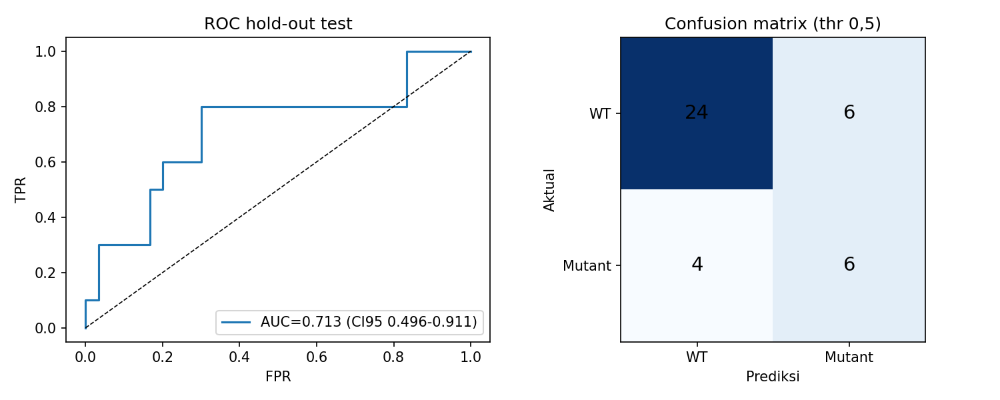


=== S4: efisiensi komputasi ===


,Tahap,Waktu,Peak VRAM
0,Praproses: tissue detection,4 s/WSI (total 0.2 jam),-
1,Praproses: stain normalization Macenko,491 s/WSI (total 27.3 jam),-
2,Praproses TOTAL,TIDAK LENGKAP - log tahap ini belum ada / tak ...,-
3,Ekstraksi fitur DenseNet201: komputasi GPU,"176.6 s/WSI (total 35319 s; 11,579,207 patch; ...",778 MB
4,menunggu data (baca zip Drive + decode),83.6 s/WSI (total 16716 s),-
5,simpan checkpoint ke Drive,9.6 s/WSI (total 1918 s),-
6,Training ABMIL 5-fold (config final),50.5 s/fold (total 252 s),44575 MB
7,Training ABMIL seluruh S1+tuning+S2,"34.6 s/fold (total 5190 s, 150 fold)",44575 MB
8,Training final (160 case),34.4 s,44569 MB
9,Pengujian hold-out (40 case),0.18 s,43717 MB


In [ ]:
import glob, os, json, pandas as pd
from IPython.display import display, Image
def newest(pat, folder):
    fs = glob.glob(f"{folder}/{pat}")
    return max(fs, key=os.path.getmtime) if fs else None
fj = newest("final_result_*.json", DIR_HOLD)
if fj is None:
    print("Hasil hold-out belum ada.")
else:
    r = json.load(open(fj)); print("Berkas:", os.path.basename(fj))
    print("Konfigurasi final:", r["config"], "| epoch final:", r["epochs_final"], "| bag di:", r.get("params", {}).get("penyimpanan_bag", "-"))
    for k, v in r["metrics"].items(): print(f"  {k:<11s}: {v:.4f}" + ("   (tambahan)" if k == "Specificity" else ""))
    print(f"  AUC CI95%  : [{r['auc_ci95'][0]:.4f}, {r['auc_ci95'][1]:.4f}] ({r['n_boot']} resampel valid; dibuang/diulang: {r.get('n_boot_dibuang', '-')})")
    print("  Confusion  :", r["confusion"], "(Mutant = positif)")
    print("  Attention  :", r["attention"])
    print("  Parameter  :", r.get("params", "(tidak tercatat: hasil dibuat sebelum revisi)"))
    png = newest("hasil_test_*.png", DIR_HOLD)
    if png: display(Image(png))
    ef = newest("efisiensi_komputasi_*.csv", DIR_HOLD)
    if ef: print("\n=== S4: efisiensi komputasi ==="); display(pd.read_csv(ef))

## Sel 14 — Revisi 1: persiapan tanpa GPU
**Tahap:** persiapan (definisi; tanpa GPU).
- Membuat folder `05_analisis_tambahan_revisi1/`, membaca kode data (`SIG`), hasil CV, dan hasil hold-out yang sudah tersimpan, serta menyiapkan fungsi simpan dan cache.
- **Masukan:** Sel 1, 2, 4 sudah dijalankan; `final_result_*.json` dan `cv_results_*.json` ada di Drive.
- **Cek hasil:** baris `Kode data … | konfigurasi final: wbce|attention|h256|a128|d0.25|lr0.0001|wd1e-05 | epoch final 21`.

In [ ]:
# ======================================================================
# REVISI 1 — PERSIAPAN TANPA GPU (dipakai Sel 15–17)
# ======================================================================
import glob
from itertools import combinations
from scipy.stats import rankdata

DIR_REV = f"{WORK}/05_analisis_tambahan_revisi1"            # semua keluaran Revisi 1 masuk ke sini
os.makedirs(DIR_REV, exist_ok=True)

_fs = sorted(glob.glob(f"{DIR_HOLD}/final_result_*.json"), key=os.path.getmtime)
if not _fs: fail("final_result_*.json belum ada di 04_hasil_holdout_dan_efisiensi/. Revisi 1 hanya berlaku setelah hold-out dijalankan (Sel 12).")
if len(_fs) > 1: log("PERINGATAN: ada >1 final_result; dipakai yang terbaru:", os.path.basename(_fs[-1]))
FINAL_PATH = _fs[-1]
SIG = os.path.basename(FINAL_PATH)[len("final_result_"):-len(".json")]
FINAL = json.load(open(FINAL_PATH))
CV_PATH = f"{DIR_CV}/cv_results_{SIG}.json"
if not os.path.exists(CV_PATH): fail(f"{CV_PATH} tidak ada (kode data tidak cocok dengan final_result).")
CV_RAW = json.load(open(CV_PATH))
EPOCH_FINAL = int(FINAL["epochs_final"]); BEST_KEY = FINAL["cv_key"]; BEST_CFG = FINAL["config"]

def save_table(df, name):
    p = f"{DIR_REV}/{name}_{SIG}.csv"; df.to_csv(p, index=False); log("tersimpan:", os.path.basename(p)); return p

def save_json(obj, name):
    p = f"{DIR_REV}/{name}_{SIG}.json"; atomic_json(obj, p, indent=1, default=float); log("tersimpan:", os.path.basename(p)); return p

# cache hasil per langkah, supaya sel GPU yang panjang bisa dilanjutkan bila sesi putus
REV_CACHE_PATH = f"{DIR_REV}/rev_cache_{SIG}.json"
REV = json.load(open(REV_CACHE_PATH)) if os.path.exists(REV_CACHE_PATH) else {}
# catatan waktu komputasi: setiap langkah yang benar-benar dihitung (bukan dibaca dari cache) ditambahkan ke waktu_komputasi_<kode>.csv
TIME_PATH = f"{DIR_REV}/waktu_komputasi_{SIG}.csv"
def catat_waktu(langkah, detik, ket=""):
    try: gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
    except Exception: gpu = "?"
    row = pd.DataFrame([dict(waktu_mulai=time.strftime("%Y-%m-%d %H:%M:%S"), langkah=langkah, detik=round(float(detik), 2), gpu=gpu, ket=ket)])
    row.to_csv(TIME_PATH, mode="a", header=not os.path.exists(TIME_PATH), index=False)
def _sync_gpu():
    try:
        if torch.cuda.is_available(): torch.cuda.synchronize()
    except Exception: pass
def memo(key, fn):
    if key in REV: return REV[key]
    _sync_gpu(); t0 = time.perf_counter(); v = fn(); _sync_gpu(); catat_waktu(key, time.perf_counter() - t0)
    REV[key] = v; atomic_json(REV, REV_CACHE_PATH); return v

tss_of = lambda cid: cid.split("-")[1]                      # TCGA-<TSS>-<peserta>

log(f"Kode data {SIG} | konfigurasi final: {BEST_KEY} | epoch final {EPOCH_FINAL}")
log(f"Folder keluaran Revisi 1: {DIR_REV}")

14:29:15 Kode data 7e86caa80d12 | konfigurasi final: wbce|attention|h256|a128|d0.25|lr0.0001|wd1e-05 | epoch final 21
14:29:15 Folder keluaran Revisi 1: /content/drive/MyDrive/EGFR_DenseNet201_ABMIL_py/05_analisis_tambahan_revisi1


## Sel 15 — A1–A3: Wilcoxon lengkap dan diagnosis epoch terbaik
**Tahap:** laporan (tanpa GPU).
- **A1/A2:** seluruh 10 pasangan loss S1 (dan 3 pasangan S2) dengan kolom jumlah fold yang selisihnya kembar (ties), p yang dilaporkan (peringkat rata-rata), dan p bila AUC dibulatkan lebih dulu (jangan dipakai). Tabel di naskah harus memuat semua 10 pasangan.
- **A3:** sebaran epoch terbaik pada 120 pelatihan tuning menurut learning rate dan fold, dengan tafsir yang benar.
- **Keluaran:** `wilcoxon_S1_lengkap_*.csv`, `wilcoxon_S2_lengkap_*.csv`, `epoch_terbaik_tuning_*.csv`.
- **Cek hasil:** BCE vs Class-Weighted BCE: p = 0,2500 (ties); epoch ≤ 5: 30 dari 120 (epoch 1: 17); lr 5e-5: 24 dari 60 vs lr 1e-4: 6 dari 60.

In [ ]:
# ======================================================================
# REVISI 1 · A1–A3 — Wilcoxon lengkap + diagnosis epoch terbaik (tanpa GPU)
# ======================================================================
def _signed_rank_p(d):
    """p dua-sisi uji signed-rank Wilcoxon lewat enumerasi seluruh 2^n tanda (n kecil -> eksak, tidak bergantung versi scipy).
    Selisih |d| yang kembar (ties) diberi peringkat rata-rata (permutasi tanda), sama seperti scipy.stats.wilcoxon bila ada ties."""
    d = np.asarray(d, float); d = d[d != 0]; n = len(d)
    if n == 0: return float("nan")
    r = rankdata(np.abs(d)); t_obs = r[d > 0].sum(); mu = r.sum() / 2
    signs = ((np.arange(2 ** n)[:, None] >> np.arange(n)) & 1).astype(float)           # semua 2^n kombinasi tanda
    return float(min(1.0, (np.abs(signs @ r - mu) >= abs(t_obs - mu) - 1e-9).mean()))

def wilcoxon_detail(named):
    rows = []
    for a, b in combinations(named, 2):
        x, y = np.array(named[a], float), np.array(named[b], float); d = x - y; nz = d[d != 0]
        n_tie = int(sum(c for c in pd.Series(np.round(np.abs(nz), 10)).value_counts() if c > 1))     # jumlah fold yang |selisihnya| kembar
        try: p_scipy = float(wilcoxon(x, y).pvalue)
        except ValueError: p_scipy = float("nan")
        try: p_round = float(wilcoxon(np.round(x, 4), np.round(y, 4)).pvalue)                         # p bila AUC dibulatkan 4 desimal dulu
        except ValueError: p_round = float("nan")
        rows.append(dict(A=a, B=b, mean_diff_AUC=d.mean(), A_menang_di_fold=int((d > 0).sum()), B_menang_di_fold=int((d < 0).sum()),
                         n_fold_selisih_kembar=n_tie, p_wilcoxon_dilaporkan=p_scipy, p_permutasi_midrank=_signed_rank_p(d),
                         p_bila_AUC_dibulatkan_4desimal=p_round))
    return pd.DataFrame(rows)

# ---- A1/A2: seluruh 10 pasangan S1 (+ S2) dengan kolom ties ----
s1_names = {"BCE": "bce|attention", "Class-Weighted BCE": "wbce|attention", "Focal g=1": "focal-g1-anone|attention",
            "Focal g=2": "focal-g2-anone|attention", "Focal g=5": "focal-g5-anone|attention"}
def _fold_auc(prefix, key_contains=None):
    ks = [k for k in CV_RAW if k.startswith(prefix) and "|h256|a128|d0.25|lr0.0001|wd1e-05" in k]
    if len(ks) != 1: fail(f"Konfigurasi S1 '{prefix}' tidak unik di cv_results ({ks}).")
    return CV_RAW[ks[0]]["fold_auc"]
named1 = {n: _fold_auc(pref) for n, pref in s1_names.items()}
w1 = wilcoxon_detail(named1)
named2 = {"attention": CV_RAW[BEST_KEY]["fold_auc"]}
for pool in ("mean", "max"):
    named2[pool] = CV_RAW[BEST_KEY.replace("|attention|", f"|{pool}|")]["fold_auc"]
w2 = wilcoxon_detail(named2)
save_table(w1.round(4), "wilcoxon_S1_lengkap"); save_table(w2.round(4), "wilcoxon_S2_lengkap")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
print("\n=== Wilcoxon S1 — seluruh 10 pasangan (n = 5 fold; p minimum dua-sisi = 0,0625) ===")
print(w1.round(4).to_string(index=False))
print("\nCatatan ties: AUC tiap fold berupa kelipatan 1/192 (8 Mutant × 24 Wild Type), sehingga selisih |AUC| antar fold sering persis kembar. "
      "Peringkat rata-rata dipakai pada p yang dilaporkan. Membulatkan AUC ke 4 desimal sebelum uji memecah ties secara semu dan MENGUBAH p pada pasangan berikut "
      "(jangan dipakai):")
t = w1[(w1.p_wilcoxon_dilaporkan - w1.p_bila_AUC_dibulatkan_4desimal).abs() > 1e-9]
for r in t.itertuples():
    print(f"  {r.A} vs {r.B}: p dilaporkan {r.p_wilcoxon_dilaporkan:.4f} | p dari AUC yang dibulatkan {r.p_bila_AUC_dibulatkan_4desimal:.4f}")
print("Tulis di naskah: metode (scipy.stats.wilcoxon pada AUC per fold yang belum dibulatkan), adanya ties, dan bahwa semua p bersifat deskriptif.")
bad = w1[(w1.p_wilcoxon_dilaporkan - w1.p_permutasi_midrank).abs() > 1e-6]
if len(bad): print("\nPERINGATAN: p scipy berbeda dari permutasi midrank pada", len(bad), "pasangan (versi scipy berbeda?):", bad[["A", "B"]].values.tolist())

# ---- A3: sebaran epoch terbaik pada 24 konfigurasi tuning (120 pelatihan fold) ----
tun = {k: v for k, v in CV_RAW.items() if v["cfg"]["loss"] == "wbce" and v["cfg"]["pooling"] == "attention"}
if len(tun) != 24: log(f"PERINGATAN: ditemukan {len(tun)} konfigurasi tuning (harapan 24).")
ep = pd.DataFrame([dict(config=k, hidden=v["cfg"]["hidden"], attn=v["cfg"]["attn"], dropout=v["cfg"]["dropout"], lr=v["cfg"]["lr"],
                        fold=i + 1, best_epoch=e, auc_val=v["fold_auc"][i])
                   for k, v in tun.items() for i, e in enumerate(v["best_epoch"])])
ep["epoch_le5"] = ep.best_epoch <= 5; ep["epoch_1"] = ep.best_epoch == 1; ep["epoch_maks"] = ep.best_epoch >= A.max_epoch
save_table(ep, "epoch_terbaik_tuning")
print(f"\n=== A3: epoch terbaik pada {len(ep)} pelatihan fold ({len(tun)} konfigurasi × 5 fold) ===")
print(f"epoch terbaik ≤ 5 : {int(ep.epoch_le5.sum())} dari {len(ep)}  (epoch 1 saja: {int(ep.epoch_1.sum())}) | mencapai batas {A.max_epoch}: {int(ep.epoch_maks.sum())}")
print("\nMenurut learning rate (jumlah epoch terbaik ≤ 5):\n" + ep.groupby("lr").agg(n=("epoch_le5", "size"), le5=("epoch_le5", "sum")).to_string())
print("\nMenurut fold (jumlah epoch terbaik ≤ 5):\n" + ep.groupby("fold").agg(n=("epoch_le5", "size"), le5=("epoch_le5", "sum")).to_string())
print("\nTafsir: epoch terbaik 1–5 + patience 10 berarti AUC validasi tidak pernah melampaui nilai awal selama 10 epoch berikutnya. "
      "Dengan hanya 8 Mutant per fold, AUC validasi sangat bising, jadi pola ini lebih mungkin 'puncak kebetulan' daripada 'berhenti sebelum konvergen'. "
      "Kriteria early stopping TIDAK diubah setelah hold-out dibuka.")

02:14:35 tersimpan: wilcoxon_S1_lengkap_7e86caa80d12.csv
02:14:35 tersimpan: wilcoxon_S2_lengkap_7e86caa80d12.csv

=== Wilcoxon S1 — seluruh 10 pasangan (n = 5 fold; p minimum dua-sisi = 0,0625) ===
                 A                  B  mean_diff_AUC  A_menang_di_fold  B_menang_di_fold  n_fold_selisih_kembar  p_wilcoxon_dilaporkan  p_permutasi_midrank  p_bila_AUC_dibulatkan_4desimal
               BCE Class-Weighted BCE        -0.0667                 1                 4                      2                 0.2500               0.2500                          0.3125
               BCE          Focal g=1        -0.0646                 1                 4                      2                 0.3125               0.3125                          0.1875
               BCE          Focal g=2        -0.0521                 2                 3                      4                 0.4375               0.4375                          0.6250
               BCE          Focal g=5        -0.0

## Sel 16 — A4, B1, B3: ringkasan data dan tissue source site (TSS)
**Tahap:** laporan (tanpa GPU; membaca `macenko_summary.csv`, `splits.json`, `inventaris_patch.csv`).
- Distribusi WSI, jumlah patch per kelompok, ukuran fitur dalam **GiB dan GB**, tabel **TSS × label × bagian** (train/dev vs hold-out), dan uji permutasi asosiasi TSS–label.
- **Keluaran:** `distribusi_wsi_*.csv`, `patch_per_kelompok_*.csv`, `tss_label_bagian_*.csv`, `ringkasan_data_*.json`.
- **B2:** µm/piksel tidak ada di log praproses. Bila kamu membuat `slide_properties.csv` (kolom `case_id, mpp_x, mpp_y, objective_power`) di folder kerja, sel ini meringkasnya.
- **Cek hasil:** 26 TSS; 41,41 GiB = 44,46 GB; hold-out: 7 dari 10 Mutant berasal dari TSS tanpa Wild Type di hold-out.

In [ ]:
# ======================================================================
# REVISI 1 · B1, A4, B3 — Ringkasan data: distribusi, jumlah patch, ukuran fitur, tissue source site (TSS) (tanpa GPU)
# ======================================================================
SPL = json.load(open(f"{DIR_SPLIT}/splits.json"))
SUM = pd.read_csv(f"{ZIP_DIR}/macenko_summary.csv"); INV = pd.read_csv(f"{DIR_SPLIT}/inventaris_patch.csv")
SUM["case_id"] = SUM.slide.map(cid_of); SUM["y"] = SUM.label.map(lab_of)
D = SUM[["case_id", "y"]].merge(INV[["case_id", "n_used"]], on="case_id")
D["bagian"] = np.where(D.case_id.isin(SPL["test"]), "test (hold-out)", "train/dev"); D["tss"] = D.case_id.map(tss_of)
D["kelas"] = D.y.map({1: "Mutant", 0: "Wild Type"})
assert len(D) == 200 and D.case_id.is_unique and set(D.case_id[D.bagian == "test (hold-out)"]) == set(SPL["test"]), "data tidak cocok dengan splits.json"

# ---- Tabel 1: distribusi WSI ----
t1 = pd.crosstab(D.bagian, D.kelas, margins=True, margins_name="Total").reset_index(); save_table(t1, "distribusi_wsi")
print("=== Distribusi WSI ===\n" + t1.to_string(index=False))

# ---- Jumlah patch & ukuran fitur (A4: tulis GiB dan GB secara konsisten) ----
n_patch = int(D.n_used.sum()); b = n_patch * 1920 * 2                   # fp16 = 2 byte
ukuran = dict(total_patch=n_patch, patch_per_wsi_min=int(D.n_used.min()), patch_per_wsi_rata2=float(D.n_used.mean()), patch_per_wsi_median=float(D.n_used.median()),
              patch_per_wsi_maks=int(D.n_used.max()), fitur_GiB=b / 2**30, fitur_GB=b / 1e9, dimensi_fitur=1920, presisi="fp16")
fd = Path(DIR_FEATFILES)
if fd.is_dir():
    fs = [p for p in fd.glob("*.pt")]; ukuran["berkas_fitur_di_drive_GiB"] = sum(p.stat().st_size for p in fs) / 2**30; ukuran["n_berkas_fitur"] = len(fs)
print(f"\n=== Jumlah patch & ukuran fitur ===\ntotal {n_patch:,} patch | per WSI: min {ukuran['patch_per_wsi_min']:,}, median {ukuran['patch_per_wsi_median']:,.0f}, "
      f"rata-rata {ukuran['patch_per_wsi_rata2']:,.0f}, maks {ukuran['patch_per_wsi_maks']:,}\n"
      f"ukuran fitur fp16 (n × 1920 × 2 byte) = {ukuran['fitur_GiB']:.2f} GiB = {ukuran['fitur_GB']:.2f} GB   <- tulis KEDUANYA dengan satuan, jangan dicampur")
pk = D.groupby(["bagian", "kelas"]).n_used.agg(n="size", total="sum", min="min", median="median", maks="max").reset_index(); save_table(pk, "patch_per_kelompok")
print("\nPatch per kelompok:\n" + pk.to_string(index=False))

# ---- B1: TSS × label × bagian ----
ts = D.pivot_table(index="tss", columns=["bagian", "kelas"], values="case_id", aggfunc="count", fill_value=0)
ts.columns = [f"{'test' if 'test' in a else 'dev'}_{'mut' if k == 'Mutant' else 'wt'}" for a, k in ts.columns]
for c in ("dev_mut", "dev_wt", "test_mut", "test_wt"):
    if c not in ts: ts[c] = 0
ts = ts[["dev_mut", "dev_wt", "test_mut", "test_wt"]].astype(int)
ts["dev_n"] = ts.dev_mut + ts.dev_wt; ts["test_n"] = ts.test_mut + ts.test_wt; ts["total_n"] = ts.dev_n + ts.test_n
ts["dev_frac_mut"] = (ts.dev_mut / ts.dev_n.replace(0, np.nan)).round(3)
ts = ts.sort_values(["total_n", "dev_mut"], ascending=False).reset_index(); save_table(ts, "tss_label_bagian")
print(f"\n=== TSS × label × bagian (B1): {D.tss.nunique()} TSS ===\n" + ts.to_string(index=False))
dev_tss, te_tss = set(D.tss[D.bagian == "train/dev"]), set(D.tss[D.bagian == "test (hold-out)"])
print(f"\nTSS pada train/dev: {len(dev_tss)} | pada hold-out: {len(te_tss)} | TSS hold-out yang tidak ada di train/dev: {sorted(te_tss - dev_tss) or 'tidak ada'}")
te_only_mut = ts[(ts.test_wt == 0) & (ts.test_mut > 0)]
print(f"Hold-out: Mutant di TSS yang TIDAK punya Wild Type di hold-out = {int(te_only_mut.test_mut.sum())} dari {int(ts.test_mut.sum())}  (TSS: {te_only_mut.tss.tolist()})")

# ---- asosiasi TSS × label (uji permutasi chi-kuadrat; sel kecil -> tidak pakai chi-kuadrat asimptotik) ----
def chi2_perm(sub, n_perm=20000, seed=SEED):
    ct = pd.crosstab(sub.tss, sub.y).values.astype(float)
    def stat(tab):
        e = tab.sum(1, keepdims=True) * tab.sum(0, keepdims=True) / tab.sum(); return float(((tab - e) ** 2 / e).sum())
    obs = stat(ct); rng = np.random.RandomState(seed); site = pd.factorize(sub.tss)[0]; y = sub.y.values.copy(); k = site.max() + 1; ge = 0
    for _ in range(n_perm):
        yp = rng.permutation(y); tab = np.zeros((k, 2)); np.add.at(tab, (site, yp), 1); ge += stat(tab) >= obs - 1e-12
    n = ct.sum(); return dict(chi2=obs, p_perm=float((ge + 1) / (n_perm + 1)), n=int(n), n_tss=int(k), cramers_v=float(np.sqrt(obs / n)))
assoc = {"train_dev": chi2_perm(D[D.bagian == "train/dev"]), "semua_200": chi2_perm(D)}
print("\nAsosiasi TSS dengan label (permutasi chi-kuadrat, 20.000 permutasi; eksploratori):")
for k, v in assoc.items(): print(f"  {k:<10s}: n={v['n']}, {v['n_tss']} TSS, chi2={v['chi2']:.1f}, Cramér V={v['cramers_v']:.2f}, p={v['p_perm']:.4f}")
big = ts[ts.dev_n >= 5][["tss", "dev_mut", "dev_n", "dev_frac_mut"]]
print("\nTSS train/dev dengan ≥5 kasus (proporsi Mutant; prevalensi dev = %.2f):\n%s" % (D[D.bagian == 'train/dev'].y.mean(), big.to_string(index=False)))
save_json(dict(ukuran=ukuran, asosiasi_tss_label=assoc, n_tss=dict(train_dev=len(dev_tss), holdout=len(te_tss)),
               holdout_mutant_di_tss_tanpa_wt=int(te_only_mut.test_mut.sum())), "ringkasan_data")

# ---- B2: resolusi slide (µm/piksel) — tidak ada di log praproses; isi bila kamu punya berkasnya ----
mpp = f"{WORK}/slide_properties.csv"
if os.path.exists(mpp):
    sp_ = pd.read_csv(mpp); print("\n=== Properti slide (slide_properties.csv) ===\n" + sp_.describe(include="all").to_string())
else:
    print("\nB2: µm/piksel belum tercatat. Buat slide_properties.csv (kolom case_id, mpp_x, mpp_y, objective_power) di folder kerja, mis. dengan "
          "openslide: s.properties['openslide.mpp-x'], s.properties['openslide.objective-power'], lalu jalankan ulang sel ini.")

02:14:42 tersimpan: distribusi_wsi_7e86caa80d12.csv
=== Distribusi WSI ===
         bagian  Mutant  Wild Type  Total
test (hold-out)      10         30     40
      train/dev      40        120    160
          Total      50        150    200

=== Jumlah patch & ukuran fitur ===
total 11,579,207 patch | per WSI: min 2,115, median 57,258, rata-rata 57,896, maks 165,616
ukuran fitur fp16 (n × 1920 × 2 byte) = 41.41 GiB = 44.46 GB   <- tulis KEDUANYA dengan satuan, jangan dicampur
02:14:42 tersimpan: patch_per_kelompok_7e86caa80d12.csv

Patch per kelompok:
         bagian     kelas   n   total  min  median   maks
test (hold-out)    Mutant  10  433139 9122 44291.0  90009
test (hold-out) Wild Type  30 1859170 2115 60276.0 133847
      train/dev    Mutant  40 1799094 6123 32992.0 165616
      train/dev Wild Type 120 7487804 5412 63478.0 133991
02:14:42 tersimpan: tss_label_bagian_7e86caa80d12.csv

=== TSS × label × bagian (B1): 26 TSS ===
tss  dev_mut  dev_wt  test_mut  test_wt  dev_n  test_

## Sel 17 — B4, C4, C6, C9, TSS hold-out: analisis sekunder pada hold-out
**Tahap:** laporan (tanpa GPU; membaca `holdout_predictions_*` dan `attention_check_*`).
- **C4:** CI DeLong dan uji AUROC > 0,5 (DeLong, Mann–Whitney eksak, permutasi). **C1 (sebagian):** AUROC hold-out tanpa TSS dominan dan pada TSS yang punya kedua kelas. **C6:** Brier score dan tabel kalibrasi. **C9:** korelasi Spearman jumlah patch dengan probabilitas. **B4:** PPV/NPV menurut prevalensi.
- Kode identik dengan `analisis_sekunder.py` (dapat dijalankan terpisah).
- **Keluaran:** `analisis_sekunder_*.json`, `tss_holdout_*.csv`, `kalibrasi_bins_*.csv`.
- **Cek hasil:** DeLong p ≈ 0,045, Mann–Whitney p ≈ 0,046; tanpa TSS 38 AUROC 0,643; Brier 0,2035 > 0,1875 (prediktor prevalensi).

In [ ]:
# ======================================================================
# REVISI 1 · C4, C6, C9, B4, TSS hold-out — Analisis sekunder pada hold-out (tanpa GPU)
# ======================================================================
# Kode yang sama dengan berkas analisis_sekunder.py (bisa dijalankan terpisah di luar Colab). Hold-out TETAP hasil utama; semua analisis di bawah
# bersifat sekunder/eksploratori, tidak dikoreksi untuk perbandingan berganda, dan TIDAK dipakai untuk memilih atau mengubah model.
from scipy import stats
from sklearn.metrics import brier_score_loss, average_precision_score

def run(pred, attn, sig="sig", out=".", seed=42, verbose=True):
    class _A: pass
    a = _A(); a.pred, a.attn, a.sig, a.out, a.seed = pred, attn, sig, out, seed
    p_df = pd.read_csv(a.pred)
    at = pd.read_csv(a.attn).drop(columns=["top5_patch"], errors="ignore")
    d = p_df.merge(at, on="case_id")
    assert len(d) == len(p_df) == 40, "jumlah kasus hold-out harus 40"
    d["tss"] = d.case_id.str.split("-").str[1]            # TCGA-<TSS>-<peserta>
    y, p = d.label.values.astype(int), d.prob_mutant.values
    d["grp"] = np.select([(y == 1) & (d["pred@0.5"] == 1), (y == 1) & (d["pred@0.5"] == 0), (y == 0) & (d["pred@0.5"] == 1)],
                         ["TP", "FN", "FP"], "TN")
    R = {}

    # ---------- C4: uji AUROC > 0,5 dan CI DeLong ----------
    def delong(y, p):
        pos, neg = p[y == 1], p[y == 0]; m, n = len(pos), len(neg)
        psi = lambda x, z: (x > z) + 0.5 * (x == z)
        v10 = np.array([psi(x, neg).mean() for x in pos]); v01 = np.array([psi(pos, z).mean() for z in neg])
        return v10.mean(), v10.var(ddof=1) / m + v01.var(ddof=1) / n

    auc, var = delong(y, p); se = float(np.sqrt(var)); z = (auc - 0.5) / se
    mw_two = stats.mannwhitneyu(p[y == 1], p[y == 0], alternative="two-sided", method="exact")
    mw_one = stats.mannwhitneyu(p[y == 1], p[y == 0], alternative="greater", method="exact")
    rng = np.random.RandomState(a.seed)
    perm = np.array([roc_auc_score(rng.permutation(y), p) for _ in range(20000)])
    R["auc_test"] = dict(
        auc=float(roc_auc_score(y, p)), delong_se=se, delong_ci95=[float(auc - 1.96 * se), float(auc + 1.96 * se)],
        delong_z=float(z), delong_p_two=float(2 * stats.norm.sf(abs(z))), delong_p_one=float(stats.norm.sf(z)),
        mwu_U=float(mw_two.statistic), mwu_p_two=float(mw_two.pvalue), mwu_p_one=float(mw_one.pvalue),
        perm_p_one=float((perm >= auc - 1e-12).mean()), n_perm=20000)

    # ---------- C6: Brier dan kalibrasi ----------
    prev = y.mean()
    R["kalibrasi"] = dict(brier=float(brier_score_loss(y, p)), brier_prediktor_prevalensi=float(prev * (1 - prev)),
                          average_precision=float(average_precision_score(y, p)), prevalensi=float(prev))
    bins = [0, 0.05, 0.5, 0.95, 1.0001]; labels = ["[0; 0,05)", "[0,05; 0,5)", "[0,5; 0,95)", "[0,95; 1]"]
    d["bin"] = pd.cut(d.prob_mutant, bins, right=False, labels=labels)
    cal = d.groupby("bin", observed=False).agg(n=("label", "size"), mean_pred=("prob_mutant", "mean"),
                                               n_mutant=("label", "sum")).reset_index()
    cal["frac_mutant"] = cal.n_mutant / cal.n
    cal.to_csv(f"{a.out}/kalibrasi_bins_{a.sig}.csv", index=False)
    R["kalibrasi_bins"] = cal.astype({"bin": str}).to_dict("records")
    R["bimodal"] = dict(n_lt_005=int((p < 0.05).sum()), n_005_095=int(((p >= 0.05) & (p <= 0.95)).sum()), n_gt_095=int((p > 0.95).sum()))

    # ---------- C9: jumlah patch ----------
    rho, pv = stats.spearmanr(d.K, d.prob_mutant); rho2, pv2 = stats.spearmanr(d.K, d.norm_entropy)
    R["jumlah_patch"] = dict(spearman_K_prob=float(rho), p_K_prob=float(pv), spearman_K_entropi=float(rho2), p_K_entropi=float(pv2),
                             median_K_mutant=float(d[d.label == 1].K.median()), median_K_wt=float(d[d.label == 0].K.median()), n=int(len(d)))

    # ---------- B1/C1 (sebagian): tissue source site pada hold-out ----------
    site = d.groupby("tss").agg(mutant=("label", lambda s: int((s == 1).sum())), wild_type=("label", lambda s: int((s == 0).sum())),
                                TP=("grp", lambda s: int((s == "TP").sum())), FN=("grp", lambda s: int((s == "FN").sum())),
                                FP=("grp", lambda s: int((s == "FP").sum())), TN=("grp", lambda s: int((s == "TN").sum()))).reset_index()
    site = site.sort_values(["mutant", "tss"], ascending=[False, True]); site.to_csv(f"{a.out}/tss_holdout_{a.sig}.csv", index=False)
    R["tss_holdout"] = site.to_dict("records")

    def boot_ci(yy, pp, seed):
        r = np.random.RandomState(seed); b = []
        while len(b) < 1000:
            ix = r.randint(0, len(yy), len(yy))
            if len(set(yy[ix])) < 2: continue
            b.append(roc_auc_score(yy[ix], pp[ix]))
        return [float(v) for v in np.percentile(b, [2.5, 97.5])]

    def sens(sub, ci=True):
        yy, pp = sub.label.values, sub.prob_mutant.values
        out = dict(n=int(len(sub)), n_mutant=int(yy.sum()), auc=float(roc_auc_score(yy, pp)))
        out["mwu_p_two"] = float(stats.mannwhitneyu(pp[yy == 1], pp[yy == 0], alternative="two-sided", method="exact").pvalue)
        if ci: out["boot_ci95"] = boot_ci(yy, pp, a.seed)
        return out

    g = d.groupby("tss").label.agg(["min", "max"])
    mixed = g[(g["min"] == 0) & (g["max"] == 1)].index.tolist()
    only_mut = g[g["min"] == 1].index.tolist()
    dom = site.iloc[0].tss                                       # TSS dengan Mutant terbanyak
    R["sensitivitas_tss"] = dict(
        semua=sens(d), tanpa_tss_dominan=dict(tss_dikeluarkan=dom, **sens(d[d.tss != dom])),
        tss_campuran=dict(tss=mixed, **sens(d[d.tss.isin(mixed)], ci=False)),
        tss_hanya_mutant=dict(tss=only_mut, n_mutant=int(d[d.tss.isin(only_mut)].label.sum()), n_wt=0))

    # ---------- B4: prevalensi ----------
    se_, sp_ = 0.6, 0.8
    R["ppv_prevalensi"] = [dict(prevalensi=pr, ppv=float(se_ * pr / (se_ * pr + (1 - sp_) * (1 - pr))),
                                npv=float(sp_ * (1 - pr) / (sp_ * (1 - pr) + (1 - se_) * pr))) for pr in (0.25, 0.14, 0.11)]

    # ---------- C10 (sebagian): parameter ABMIL terlatih ----------
    R["parameter_abmil"] = 1920 * 256 + 256 + 256 * 128 + 128 + 128 + 1 + 256 + 1

    # ---------- ringkasan median entropi per kelompok ----------
    R["median_entropi"] = {k: float(v) for k, v in d.groupby("grp").norm_entropy.median().items()}
    R["jumlah_max_weight_gt_05"] = int((d.max_weight > 0.5).sum())

    json.dump(R, open(f"{a.out}/analisis_sekunder_{a.sig}.json", "w"), indent=1, ensure_ascii=False)
    if verbose: print(json.dumps({k: R[k] for k in ("auc_test", "kalibrasi", "jumlah_patch", "sensitivitas_tss")}, indent=1, ensure_ascii=False))
    return R

R23 = run(f"{DIR_HOLD}/holdout_predictions_{SIG}.csv", f"{DIR_HOLD}/attention_check_{SIG}.csv", sig=SIG, out=DIR_REV, seed=SEED, verbose=False)
for _f in ("analisis_sekunder", "tss_holdout", "kalibrasi_bins"): log("tersimpan:", f"{_f}_{SIG}." + ("json" if _f == "analisis_sekunder" else "csv"))
A_ = R23["auc_test"]; K_ = R23["kalibrasi"]; J_ = R23["jumlah_patch"]; T_ = R23["sensitivitas_tss"]
print("\n=== C4: uji AUROC terhadap 0,5 (hold-out, n = 40; 10 Mutant) ===")
print(f"AUROC {A_['auc']:.4f} | CI95 DeLong [{A_['delong_ci95'][0]:.3f}, {A_['delong_ci95'][1]:.3f}] (CI bootstrap utama: {FINAL['auc_ci95'][0]:.3f}–{FINAL['auc_ci95'][1]:.3f})")
print(f"DeLong z = {A_['delong_z']:.2f}: p dua-sisi {A_['delong_p_two']:.4f}, satu-sisi {A_['delong_p_one']:.4f} | Mann–Whitney eksak: U = {A_['mwu_U']:.0f}, p dua-sisi {A_['mwu_p_two']:.4f}, "
      f"satu-sisi {A_['mwu_p_one']:.4f} | permutasi label (20.000): p satu-sisi {A_['perm_p_one']:.4f}")
print("\n=== C1 (sebagian)/B1: sensitivitas AUROC hold-out terhadap komposisi TSS ===")
for nm, k in (("Seluruh hold-out", "semua"), (f"Tanpa TSS {T_['tanpa_tss_dominan']['tss_dikeluarkan']} (Mutant terbanyak)", "tanpa_tss_dominan"), (f"Hanya TSS yang punya kedua kelas {T_['tss_campuran']['tss']}", "tss_campuran")):
    v = T_[k]; ci_ = f" | CI95 bootstrap [{v['boot_ci95'][0]:.3f}, {v['boot_ci95'][1]:.3f}]" if "boot_ci95" in v else ""
    print(f"  {nm:<55s} n = {v['n']} ({v['n_mutant']} Mutant) | AUROC {v['auc']:.3f} | p Mann–Whitney {v['mwu_p_two']:.3f}{ci_}")
print(f"  TSS yang hanya berisi Mutant di hold-out: {T_['tss_hanya_mutant']['tss']} ({T_['tss_hanya_mutant']['n_mutant']} Mutant, 0 Wild Type)")
print(f"\n=== C6: kalibrasi ===\nBrier {K_['brier']:.4f} | Brier prediktor prevalensi ({K_['prevalensi']:.2f}) {K_['brier_prediktor_prevalensi']:.4f} | average precision {K_['average_precision']:.3f}")
print(pd.DataFrame(R23["kalibrasi_bins"]).round(3).to_string(index=False))
print(f"Keluaran bimodal: {R23['bimodal']['n_lt_005']} dari 40 kasus memiliki P < 0,05; hanya {R23['bimodal']['n_005_095']} kasus berada di antara 0,05 dan 0,95.")
print(f"\n=== C9: jumlah patch ===\nSpearman ρ(K, P Mutant) = {J_['spearman_K_prob']:.3f} (p = {J_['p_K_prob']:.3f}) | ρ(K, entropi attention) = {J_['spearman_K_entropi']:.3f} (p = {J_['p_K_entropi']:.3f}) | "
      f"median K Mutant {J_['median_K_mutant']:,.0f} vs Wild Type {J_['median_K_wt']:,.0f}")
print("\n=== B4: PPV/NPV pada sensitivitas 0,60 dan spesifisitas 0,80 menurut prevalensi ===")
print(pd.DataFrame(R23["ppv_prevalensi"]).round(3).to_string(index=False))
print("\nTSS pada hold-out (TP/FN/FP/TN):\n" + pd.DataFrame(R23["tss_holdout"]).to_string(index=False))

02:15:17 tersimpan: analisis_sekunder_7e86caa80d12.json
02:15:17 tersimpan: tss_holdout_7e86caa80d12.csv
02:15:17 tersimpan: kalibrasi_bins_7e86caa80d12.csv

=== C4: uji AUROC terhadap 0,5 (hold-out, n = 40; 10 Mutant) ===
AUROC 0.7133 | CI95 DeLong [0.505, 0.922] (CI bootstrap utama: 0.496–0.911)
DeLong z = 2.01: p dua-sisi 0.0449, satu-sisi 0.0224 | Mann–Whitney eksak: U = 214, p dua-sisi 0.0461, satu-sisi 0.0231 | permutasi label (20.000): p satu-sisi 0.0232

=== C1 (sebagian)/B1: sensitivitas AUROC hold-out terhadap komposisi TSS ===
  Seluruh hold-out                                        n = 40 (10 Mutant) | AUROC 0.713 | p Mann–Whitney 0.046 | CI95 bootstrap [0.496, 0.911]
  Tanpa TSS 38 (Mutant terbanyak)                         n = 37 (7 Mutant) | AUROC 0.643 | p Mann–Whitney 0.259 | CI95 bootstrap [0.355, 0.905]
  Hanya TSS yang punya kedua kelas ['50', '95', 'MP']     n = 11 (3 Mutant) | AUROC 0.583 | p Mann–Whitney 0.776
  TSS yang hanya berisi Mutant di hold-out: ['38', '

## Sel 18 — Revisi 1: persiapan GPU
**Tahap:** persiapan (memuat bag fitur ke GPU/RAM; **A100 atau GPU ≥ 40 GB disarankan**).
- Menyiapkan `Exp` (seperti Sel 10/12) dan membaca konfigurasi final dari cache CV. Tidak ada pelatihan di sel ini.
- Berhenti bila kode data atau konfigurasi terbaik berbeda dari `final_result`.
- **Cek hasil:** baris `Konfigurasi final: … | epoch final 21 | dev 160 + test 40 WSI`.

In [ ]:
# ======================================================================
# REVISI 1 — PERSIAPAN GPU (dipakai Sel 19–24): muat bag fitur, baca konfigurasi final dari cache
# ======================================================================
from sklearn.model_selection import StratifiedGroupKFold, RepeatedStratifiedKFold
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt

require_torch()
import gc
for _n in ("X", "X2", "m_u"):                                  # lepaskan bag/model dari menjalankan Sel 18 atau 27 sebelumnya (kalau tidak, GPU penuh)
    if _n in globals(): globals()[_n] = None
gc.collect(); torch.cuda.empty_cache()
log(f"Memori GPU terpakai sebelum memuat bag: {torch.cuda.memory_allocated() / 2**30:.1f} GiB (harus mendekati 0)")
C = load_context(); X = Exp(C)
if X.SIG != SIG: fail(f"Kode data sesi ini ({X.SIG}) berbeda dari final_result ({SIG}). Pastikan Sel 2 sama seperti saat CV/hold-out dijalankan.")
s1, best_loss_name, tune, best_key, best_cfg, s2 = X.run_all(False)          # hanya membaca cache; tidak melatih
if best_key != BEST_KEY: fail("Konfigurasi terbaik dari cache CV berbeda dari final_result. Jangan lanjut; selidiki dulu.")
DEV, TEST = X.splits["dev"], X.splits["test"]; ALL = DEV + TEST
log(f"Konfigurasi final: {best_key} | epoch final {EPOCH_FINAL} | dev {len(DEV)} + test {len(TEST)} WSI | bag di {X.storage.upper()} | GPU {X.gpu}")
log("Hold-out TETAP hasil utama (seed 42, threshold 0,5). Sel 19–24 hanya analisis sekunder dan tidak mengubah model/konfigurasi.")

def metrics_at(y, p, thr=0.5):
    """Metrik klasifikasi pada ambang tertentu (Mutant = positif)."""
    pred = (np.asarray(p) >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(thr=float(thr), TP=int(tp), FN=int(fn), FP=int(fp), TN=int(tn), sens=float(tp / max(tp + fn, 1)), spec=float(tn / max(tn + fp, 1)),
                ppv=float(tp / (tp + fp)) if tp + fp else float("nan"), acc=float((tp + tn) / len(y)), f1=float(2 * tp / max(2 * tp + fp + fn, 1)))

14:29:24 Memori GPU terpakai sebelum memuat bag: 0.0 GiB (harus mendekati 0)
14:29:30 Katalog: 200 WSI, Mutant 50, Wild Type 150 | split: {'train': 160, 'test': 40}
14:29:30 Jumlah zip per split x kelas (harus train 40/120, test 10/30):
y      Mutant  Wildtype  All
split                       
test       10        30   40
train      40       120  160
All        50       150  200
14:29:30 Folder validation/ (197 berkas) hanya QC, TIDAK dipakai model (split tetap train/test).
14:29:31 Hold-out: 40 case (Mutant 10) | Development: 160 case (Mutant 40)
14:29:31   Fold 1: train 128 case (Mutant 32) | val 32 case (Mutant 8)
14:29:31   Fold 2: train 128 case (Mutant 32) | val 32 case (Mutant 8)
14:29:31   Fold 3: train 128 case (Mutant 32) | val 32 case (Mutant 8)
14:29:31   Fold 4: train 128 case (Mutant 32) | val 32 case (Mutant 8)
14:29:31   Fold 5: train 128 case (Mutant 32) | val 32 case (Mutant 8)


RuntimeError: 
ERROR: Seluruh fitur (41.4 GB) tidak muat di VRAM (14.6 GB) maupun RAM kosong (47.9 GB). Seluruh patch wajib dipakai (tanpa cap), jadi gunakan runtime dengan memori lebih besar: High-RAM (Colab Pro, RAM ~50 GB) atau GPU VRAM lebih besar (L4 24 GB / A100 40 GB), lalu ulangi sel ini. Fitur yang sudah diekstraksi tetap dipakai.

## Sel 19 — C1: validasi silang yang menjaga site (site-preserved CV)
**Tahap:** analisis sekunder (GPU).
- 5 fold `StratifiedGroupKFold` pada 160 WSI train/dev dengan grup = TSS (tiap TSS hanya di latih **atau** validasi), konfigurasi final tanpa tuning ulang, protokol early stopping sama dengan CV utama.
- **Keluaran:** `C1_site_preserved_cv_*.csv/.json`. Dibandingkan dengan CV utama 0,827 ± 0,089.
- Selisih kecil tidak bermakna (8 Mutant per fold); tulis sebagai eksploratori.

In [ ]:
# ======================================================================
# REVISI 1 · C1 — Validasi silang yang menjaga site (site-preserved CV) pada train/dev
# ======================================================================
# Satu TSS tidak boleh muncul di data latih DAN validasi pada fold yang sama. Konfigurasi, loss, dan protokol early stopping sama dengan CV utama
# (tanpa tuning ulang), jadi selisih terhadap CV utama (0,827) mengukur seberapa jauh kinerja bergantung pada kemunculan site yang sama.
y_dev = np.array([X.LABEL[c] for c in DEV]); g_dev = np.array([tss_of(c) for c in DEV])

def site_folds(min_per_class=4, seeds=range(42, 242)):
    """Cari pembagian StratifiedGroupKFold (grup = TSS) dengan tiap fold validasi minimal `min_per_class` Mutant dan Wild Type."""
    for rs in seeds:
        folds, ok = [], True
        for tr, va in StratifiedGroupKFold(5, shuffle=True, random_state=rs).split(DEV, y_dev, g_dev):
            ok &= (y_dev[va].sum() >= min_per_class) and ((1 - y_dev[va]).sum() >= min_per_class) and len(set(y_dev[tr])) == 2
            folds.append(([DEV[i] for i in tr], [DEV[i] for i in va]))
        if ok: return rs, folds
    fail("Tidak ada pembagian site-preserved yang memenuhi syarat minimum kelas per fold.")

C1_SEED, C1_FOLDS = site_folds()
rows, oof_id, oof_p = [], [], []
for i, (tr, va) in enumerate(C1_FOLDS, 1):
    assert not ({tss_of(c) for c in tr} & {tss_of(c) for c in va}), "ada TSS yang muncul di latih dan validasi"
    def _fit(tr=tr, va=va):
        model, auc, ep = X.train_model(best_cfg, tr, va); yv, pv = X.predict(model, va)
        return dict(auc=float(auc), best_epoch=int(ep), ids=va, p=pv.tolist())
    r = memo(f"c1|seed{C1_SEED}|fold{i}", _fit); oof_id += r["ids"]; oof_p += r["p"]
    yv = [X.LABEL[c] for c in r["ids"]]
    rows.append(dict(fold=i, n_train=len(tr), n_val=len(va), val_mutant=int(sum(yv)), val_wild_type=len(yv) - int(sum(yv)), n_tss_val=len({tss_of(c) for c in va}),
                     tss_val=" ".join(sorted({tss_of(c) for c in va})), best_epoch=r["best_epoch"], auc_val=r["auc"]))
    log(f"  site-preserved fold {i}: AUC validasi {r['auc']:.4f} (epoch {r['best_epoch']}) | val {len(va)} WSI, {len({tss_of(c) for c in va})} TSS")
t = pd.DataFrame(rows); save_table(t, "C1_site_preserved_cv")
base = CV_RAW[BEST_KEY]; y_oof = np.array([X.LABEL[c] for c in oof_id])
res = dict(seed_pembagian=C1_SEED, auc_fold=t.auc_val.tolist(), mean_auc=float(t.auc_val.mean()), sd_auc=float(t.auc_val.std(ddof=1)),
           pooled_oof_auc=float(roc_auc_score(y_oof, oof_p)), cv_utama_mean_auc=base["mean_auc"], cv_utama_sd_auc=base["std_auc"], cv_utama_fold_auc=base["fold_auc"],
           selisih_vs_cv_utama=float(t.auc_val.mean() - base["mean_auc"]))
save_json(res, "C1_site_preserved_cv")
print("\n=== C1: site-preserved CV (tiap TSS hanya di satu sisi: latih ATAU validasi) ===\n" + t.round(4).to_string(index=False))
print(f"\nSite-preserved : AUC rata-rata {res['mean_auc']:.4f} ± {res['sd_auc']:.4f} | pooled OOF AUC {res['pooled_oof_auc']:.4f}")
print(f"CV utama (stratified acak): AUC rata-rata {base['mean_auc']:.4f} ± {base['std_auc']:.4f}  -> selisih {res['selisih_vs_cv_utama']:+.4f}")
print("Catatan: kedua AUC memakai protokol yang sama (early stopping pada fold validasi) sehingga sama-sama optimistis; yang dibandingkan adalah SELISIHNYA. "
      "Dengan 8 Mutant per fold dan TSS yang tidak seimbang, selisih kecil tidak bermakna; tulis sebagai analisis sekunder/eksploratori.")

02:37:22   site-preserved fold 1: AUC validasi 0.9239 (epoch 36) | val 27 WSI, 3 TSS
02:38:05   site-preserved fold 2: AUC validasi 0.7593 (epoch 18) | val 21 WSI, 3 TSS
02:38:51   site-preserved fold 3: AUC validasi 0.6800 (epoch 20) | val 20 WSI, 6 TSS
02:39:20   site-preserved fold 4: AUC validasi 0.7014 (epoch 13) | val 63 WSI, 8 TSS
02:40:33   site-preserved fold 5: AUC validasi 0.9805 (epoch 42) | val 29 WSI, 6 TSS
02:40:33 tersimpan: C1_site_preserved_cv_7e86caa80d12.csv
02:40:33 tersimpan: C1_site_preserved_cv_7e86caa80d12.json

=== C1: site-preserved CV (tiap TSS hanya di satu sisi: latih ATAU validasi) ===
 fold  n_train  n_val  val_mutant  val_wild_type  n_tss_val                 tss_val  best_epoch  auc_val
    1      133     27           4             23          3                69 MP NJ          36   0.9239
    2      139     21           9             12          3                55 95 J2          18   0.7593
    3      140     20           5             15          6  

## Sel 20 — C5: ambang Youden dari prediksi out-of-fold
**Tahap:** analisis sekunder (GPU, ±5 menit).
- Melatih ulang 5 fold CV utama (hasil harus identik dengan CV utama; peringatan muncul bila beda > 1e-3), mengumpulkan prediksi OOF 160 WSI, menghitung ambang Youden, lalu melaporkannya berdampingan dengan ambang 0,5 pada OOF dan hold-out. Ambang **tidak** dituning pada hold-out.
- **Keluaran:** `C5_oof_predictions_*.csv`, `C5_ambang_youden_*.csv/.json`.

In [ ]:
# ======================================================================
# REVISI 1 · C5 — Ambang dari prediksi out-of-fold (indeks Youden), dilaporkan berdampingan dengan ambang 0,5
# ======================================================================
# Prediksi OOF = prediksi tiap kasus train/dev oleh model fold yang TIDAK melihat kasus itu (5 fold CV utama, konfigurasi final).
# Ambang ditetapkan HANYA dari data train/dev, lalu dipakai apa adanya pada hold-out (tidak melanggar aturan hold-out). Ambang 0,5 tetap hasil utama.
oof_id, oof_p, oof_fold = [], [], []
for i, f in enumerate(X.splits["folds"], 1):
    def _fit(f=f):
        model, auc, ep = X.train_model(best_cfg, f["train"], f["val"]); yv, pv = X.predict(model, f["val"])
        return dict(auc=float(auc), best_epoch=int(ep), ids=f["val"], p=pv.tolist())
    r = memo(f"c5|fold{i}", _fit); oof_id += r["ids"]; oof_p += r["p"]; oof_fold += [i] * len(r["ids"])
    ref = CV_RAW[BEST_KEY]["fold_auc"][i - 1]
    log(f"  fold {i}: AUC {r['auc']:.4f} (CV utama {ref:.4f}) epoch {r['best_epoch']}" + ("" if abs(r["auc"] - ref) < 1e-3 else "   <-- PERINGATAN: tidak identik dengan CV utama"))
y_oof = np.array([X.LABEL[c] for c in oof_id]); p_oof = np.array(oof_p)
pd.DataFrame(dict(case_id=oof_id, fold=oof_fold, label=y_oof, prob_mutant=p_oof)).to_csv(f"{DIR_REV}/C5_oof_predictions_{SIG}.csv", index=False)
fpr, tpr, thr = roc_curve(y_oof, p_oof); j = tpr - fpr; k = int(np.argmax(j))
THR_YOUDEN = float(thr[k]); auc_oof = float(roc_auc_score(y_oof, p_oof))
print(f"\nAUC OOF (160 WSI gabungan 5 fold): {auc_oof:.4f}")
print(f"Ambang Youden dari OOF: {THR_YOUDEN:.4f}  (sens {tpr[k]:.3f}, spes {1 - fpr[k]:.3f}, J = {j[k]:.3f})")

hp = pd.read_csv(f"{DIR_HOLD}/holdout_predictions_{SIG}.csv"); y_te, p_te = hp.label.values, hp.prob_mutant.values
rows = [dict(sumber="OOF train/dev (160)", **metrics_at(y_oof, p_oof, 0.5), ket="ambang 0,5"), dict(sumber="OOF train/dev (160)", **metrics_at(y_oof, p_oof, THR_YOUDEN), ket="ambang Youden OOF"),
        dict(sumber="Hold-out (40) — HASIL UTAMA", **metrics_at(y_te, p_te, 0.5), ket="ambang 0,5"),
        dict(sumber="Hold-out (40) — sekunder", **metrics_at(y_te, p_te, THR_YOUDEN), ket="ambang Youden dari OOF (tetap, tidak dituning pada hold-out)")]
t = pd.DataFrame(rows); save_table(t.round(4), "C5_ambang_youden")
save_json(dict(ambang_youden=THR_YOUDEN, auc_oof=auc_oof, J=float(j[k]), tabel=rows), "C5_ambang_youden")
print("\n" + t.round(3).to_string(index=False))
print("\nCatatan: prediksi OOF diambil dari model pada epoch terbaik fold (early stopping pada fold yang sama) -> cenderung optimistis, dan keluaran model sangat bimodal "
      "sehingga ambang Youden bisa jauh dari 0,5. Laporkan kedua ambang berdampingan; hasil utama tetap ambang 0,5.")

02:42:47   fold 1: AUC 0.7083 (CV utama 0.7083) epoch 21
02:43:39   fold 2: AUC 0.7552 (CV utama 0.7552) epoch 26
02:44:22   fold 3: AUC 0.8802 (CV utama 0.8802) epoch 19
02:45:32   fold 4: AUC 0.9062 (CV utama 0.9062) epoch 39
02:46:16   fold 5: AUC 0.8854 (CV utama 0.8854) epoch 20

AUC OOF (160 WSI gabungan 5 fold): 0.7744
Ambang Youden dari OOF: 0.0833  (sens 0.750, spes 0.725, J = 0.475)
02:46:17 tersimpan: C5_ambang_youden_7e86caa80d12.csv
02:46:17 tersimpan: C5_ambang_youden_7e86caa80d12.json

                     sumber   thr  TP  FN  FP  TN  sens  spec   ppv   acc    f1                                                          ket
        OOF train/dev (160) 0.500  23  17  18 102 0.575 0.850 0.561 0.781 0.568                                                   ambang 0,5
        OOF train/dev (160) 0.083  30  10  33  87 0.750 0.725 0.476 0.731 0.583                                            ambang Youden OOF
Hold-out (40) — HASIL UTAMA 0.500   6   4   6  24 0.600 0.800 0.500 0.7

## Sel 21 — C7: konfigurasi final dengan 5 seed
**Tahap:** analisis sekunder (GPU).
- (a) Model final (160 WSI, 21 epoch) per seed 42–46 → AUC dan sens/spes hold-out per seed. (b) CV 5 fold per seed (atur `RUN_CV_SEEDS = False` bila hanya ingin (a)). Seed 42 harus mereproduksi hasil utama.
- Membandingkan SD antar-seed dengan SD antar-fold dan selisih antar konfigurasi teratas.
- **Keluaran:** `C7_seed_holdout_*.csv`, `C7_seed_cv_*.csv`, `C7_seed_*.json`. Hasil utama tetap seed 42.

In [ ]:
# ======================================================================
# REVISI 1 · C7 — Konfigurasi final dilatih ulang dengan 5 seed (stabilitas terhadap inisialisasi/urutan bag)
# ======================================================================
SEEDS = [42, 43, 44, 45, 46]          # 42 = seed hasil utama (harus mereproduksi angka hold-out utama)
RUN_CV_SEEDS = True                   # False = hanya model final (±3 menit); True = + 5-fold per seed (±15–20 menit di A100)

# (a) model final (160 WSI, epoch tetap) per seed -> AUC hold-out per seed [SEKUNDER]
def _final(s):
    model, _, _ = X.train_model(best_cfg, DEV, None, fixed_epochs=EPOCH_FINAL, seed=s); y, p = X.predict(model, TEST)
    return dict(p=p.tolist(), auc=float(roc_auc_score(y, p)), **{k: v for k, v in metrics_at(y, p, 0.5).items() if k in ("sens", "spec", "TP", "FN", "FP", "TN")})
rows = []
for s in SEEDS:
    r = memo(f"c7|final|{s}", lambda s=s: _final(s)); rows.append(dict(seed=s, auc_holdout=r["auc"], sens=r["sens"], spec=r["spec"], TP=r["TP"], FN=r["FN"], FP=r["FP"], TN=r["TN"]))
    log(f"  seed {s}: AUC hold-out {r['auc']:.4f} | sens {r['sens']:.2f} spes {r['spec']:.2f}")
tf = pd.DataFrame(rows)
if abs(tf.loc[tf.seed == 42, "auc_holdout"].iloc[0] - FINAL["metrics"]["AUC"]) > 1e-4:
    log(f"PERINGATAN: seed 42 tidak persis mereproduksi AUC hold-out utama ({FINAL['metrics']['AUC']:.4f}); periksa versi PyTorch/GPU (determinisme).")
save_table(tf.round(4), "C7_seed_holdout")
print("\n=== C7a: model final per seed (hold-out; sekunder — hasil utama tetap seed 42) ===\n" + tf.round(4).to_string(index=False))
print(f"AUC hold-out: rata-rata {tf.auc_holdout.mean():.4f} | SD antar-seed {tf.auc_holdout.std(ddof=1):.4f} | rentang {tf.auc_holdout.min():.4f}–{tf.auc_holdout.max():.4f}")

# (b) CV 5-fold per seed -> bandingkan SD antar-seed dengan SD antar-fold dan selisih antar konfigurasi teratas
res = dict(seeds=SEEDS, holdout=tf.to_dict("records"), holdout_auc_mean=float(tf.auc_holdout.mean()), holdout_auc_sd=float(tf.auc_holdout.std(ddof=1)))
if RUN_CV_SEEDS:
    rows = []
    for s in SEEDS:
        aucs = []
        for i, f in enumerate(X.splits["folds"], 1):
            def _fit(f=f, s=s):
                _, auc, ep = X.train_model(best_cfg, f["train"], f["val"], seed=s); return dict(auc=float(auc), best_epoch=int(ep))
            r = memo(f"c7|cv|{s}|{i}", _fit); aucs.append(r["auc"])
        rows.append(dict(seed=s, **{f"fold{i + 1}": a for i, a in enumerate(aucs)}, mean_auc=float(np.mean(aucs)), sd_fold=float(np.std(aucs, ddof=1))))
        log(f"  CV seed {s}: rata-rata AUC {np.mean(aucs):.4f}")
    tc = pd.DataFrame(rows); save_table(tc.round(4), "C7_seed_cv")
    ref = CV_RAW[BEST_KEY]["mean_auc"]; top = sorted([v["mean_auc"] for k, v in CV_RAW.items() if v["cfg"]["loss"] == "wbce" and v["cfg"]["pooling"] == "attention"], reverse=True)
    res.update(cv=tc.to_dict("records"), cv_mean_over_seeds=float(tc.mean_auc.mean()), cv_sd_over_seeds=float(tc.mean_auc.std(ddof=1)), sd_fold_rata2=float(tc.sd_fold.mean()))
    print("\n=== C7b: CV 5-fold per seed ===\n" + tc.round(4).to_string(index=False))
    print(f"Rata-rata AUC CV antar-seed {tc.mean_auc.mean():.4f} | SD antar-seed {tc.mean_auc.std(ddof=1):.4f} | SD antar-fold (rata-rata) {tc.sd_fold.mean():.4f}")
    print(f"Pembanding: selisih AUC CV antara konfigurasi terbaik dan peringkat 2/3/5 tuning = {top[0] - top[1]:.4f} / {top[0] - top[2]:.4f} / {top[0] - top[4]:.4f}")
    print("Bila SD antar-seed sebanding atau lebih besar dari selisih-selisih itu, urutan konfigurasi teratas tidak boleh dibaca sebagai perbedaan nyata.")
save_json(res, "C7_seed")

02:47:29   seed 42: AUC hold-out 0.7133 | sens 0.60 spes 0.80
02:48:03   seed 43: AUC hold-out 0.6900 | sens 0.60 spes 0.83
02:48:38   seed 44: AUC hold-out 0.6200 | sens 0.30 spes 0.77
02:49:12   seed 45: AUC hold-out 0.6800 | sens 0.70 spes 0.77
02:49:47   seed 46: AUC hold-out 0.6667 | sens 0.70 spes 0.70
02:49:47 tersimpan: C7_seed_holdout_7e86caa80d12.csv

=== C7a: model final per seed (hold-out; sekunder — hasil utama tetap seed 42) ===
 seed  auc_holdout  sens   spec  TP  FN  FP  TN
   42       0.7133   0.6 0.8000   6   4   6  24
   43       0.6900   0.6 0.8333   6   4   5  25
   44       0.6200   0.3 0.7667   3   7   7  23
   45       0.6800   0.7 0.7667   7   3   7  23
   46       0.6667   0.7 0.7000   7   3   9  21
AUC hold-out: rata-rata 0.6740 | SD antar-seed 0.0347 | rentang 0.6200–0.7133
02:54:00   CV seed 42: rata-rata AUC 0.8271
02:57:23   CV seed 43: rata-rata AUC 0.8031
03:00:41   CV seed 44: rata-rata AUC 0.7865
03:04:49   CV seed 45: rata-rata AUC 0.7844
03:08:21   

'/content/drive/MyDrive/EGFR_DenseNet201_ABMIL_py/05_analisis_tambahan_revisi1/C7_seed_7e86caa80d12.json'

## Sel 22 — C10, B3: parameter, FLOPs, dan waktu inferensi end-to-end
**Tahap:** analisis sekunder (GPU, detik).
- Jumlah parameter DenseNet201 (18,09 juta, dibekukan) dan ABMIL (525.058), FLOPs per patch, throughput ekstraksi pada GPU sesi ini (data sintetis, tanpa I/O), dan perkiraan waktu end-to-end per WSI rata-rata dari log ekstraksi aktual.
- **Keluaran:** `C10_kompleksitas_inferensi_*.csv/.json`. Waktu 0,18 detik pada tabel S4 hanya ABMIL; angka end-to-end ada di sini.

In [ ]:
# ======================================================================
# REVISI 1 · C10, B3 — Jumlah parameter, FLOPs, dan waktu inferensi end-to-end per WSI
# ======================================================================
from torch.utils.flop_counter import FlopCounterMode
dev = X.dev; amp_ok = dev.type == "cuda"
net = torchvision.models.densenet201(weights=None); net.classifier = nn.Identity(); net = net.to(dev).eval().to(memory_format=torch.channels_last)  # bobot acak: kompleksitas dan kecepatan sama
n_dn = sum(p.numel() for p in net.parameters())
abmil = MILNet(1920, best_cfg["hidden"], best_cfg["attn"], best_cfg["dropout"], best_cfg["pooling"]).to(dev).eval()
n_ab = sum(p.numel() for p in abmil.parameters())
with torch.no_grad():
    with FlopCounterMode(display=False) as fc: net(torch.zeros(1, 3, 224, 224, device=dev).contiguous(memory_format=torch.channels_last))
    fl_dn = fc.get_total_flops()
    with FlopCounterMode(display=False) as fc2: abmil(torch.zeros(1000, 1920, device=dev))
    fl_ab = fc2.get_total_flops() / 1000                                                   # per patch (bag 1000)

def _sync():
    if amp_ok: torch.cuda.synchronize()
B = 128; xb = torch.randn(B, 3, 224, 224, device=dev).contiguous(memory_format=torch.channels_last)
with torch.no_grad(), torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=amp_ok):
    for _ in range(5): net(xb)
    _sync(); t0 = time.perf_counter(); n_it = 30 if amp_ok else 2
    for _ in range(n_it): net(xb)
    _sync(); thr_gpu = B * n_it / (time.perf_counter() - t0)                               # patch/detik (hanya komputasi GPU, tanpa I/O)
K_mean = float(X.man.n_used.mean())
cid_mid = X.man.iloc[(X.man.n_used - K_mean).abs().argsort().iloc[0]].case_id; bag = X.bag(cid_mid)   # bag dengan K paling dekat rata-rata
with torch.no_grad():
    for _ in range(3): abmil(bag)
    _sync(); t0 = time.perf_counter()
    for _ in range(20): abmil(bag)
    _sync(); t_ab = (time.perf_counter() - t0) / 20

te = pd.read_csv(f"{DIR_FEAT}/timings_extraction_{CAP_TAG}_{PREC}.csv").drop_duplicates("case_id", keep="last")
mean_gpu, mean_wait, mean_save = te.t_gpu_s.mean(), te.t_wait_s.mean(), te.t_save_s.mean()
rows = [["Parameter DenseNet201 (backbone, dibekukan)", f"{n_dn:,}"], ["Parameter ABMIL (dilatih)", f"{n_ab:,}"],
        ["FLOPs DenseNet201 per patch 224×224 (2×MAC)", f"{fl_dn / 1e9:.2f} GFLOPs"], ["FLOPs ABMIL per patch (bag 1.000)", f"{fl_ab / 1e6:.2f} MFLOPs"],
        [f"Throughput DenseNet201, {X.gpu}, fp16, batch {B} (tanpa I/O)", f"{thr_gpu:,.0f} patch/s"],
        [f"Estimasi komputasi GPU ekstraksi untuk 1 WSI rata-rata (K = {K_mean:,.0f}) pada {X.gpu}", f"{K_mean / thr_gpu:.1f} s"],
        [f"Inferensi ABMIL 1 WSI (K = {int(len(bag)):,}) pada {X.gpu}", f"{t_ab * 1000:.1f} ms"],
        ["Ekstraksi aktual per WSI dari log (komputasi GPU) — GPU ekstraksi: " + ", ".join(te.gpu.unique()), f"{mean_gpu:.1f} s"],
        ["  + menunggu data (baca zip Drive + decode)", f"{mean_wait:.1f} s"], ["  + simpan checkpoint ke Drive", f"{mean_save:.1f} s"],
        ["Inferensi end-to-end 1 WSI rata-rata (log aktual: GPU + tunggu data + ABMIL, tanpa simpan)", f"{mean_gpu + mean_wait + t_ab:.1f} s ≈ {(mean_gpu + mean_wait + t_ab) / 60:.1f} menit"],
        ["  hanya komputasi GPU (tanpa I/O)", f"{mean_gpu + t_ab:.1f} s ≈ {(mean_gpu + t_ab) / 60:.1f} menit"]]
t = pd.DataFrame(rows, columns=["Komponen", "Nilai"]); save_table(t, "C10_kompleksitas_inferensi"); save_json(dict(rows=rows, n_params_densenet201=n_dn, n_params_abmil=n_ab,
                                                                                         gflops_densenet201=fl_dn / 1e9, throughput_patch_per_s=thr_gpu, abmil_ms=t_ab * 1000), "C10_kompleksitas_inferensi")
print("\n=== C10: kompleksitas dan waktu inferensi ===\n" + t.to_string(index=False))
print("\nCatatan: waktu 0,18 detik pada tabel S4 hanya mencakup ABMIL setelah fitur dimuat; waktu end-to-end per WSI ada pada baris di atas. "
      "Waktu praproses (Macenko dkk., di server praproses) belum termasuk.")
del net, xb; torch.cuda.empty_cache() if amp_ok else None

03:11:39 tersimpan: C10_kompleksitas_inferensi_7e86caa80d12.csv
03:11:39 tersimpan: C10_kompleksitas_inferensi_7e86caa80d12.json

=== C10: kompleksitas dan waktu inferensi ===
                                                                                      Komponen               Nilai
                                                   Parameter DenseNet201 (backbone, dibekukan)          18,092,928
                                                                     Parameter ABMIL (dilatih)             525,058
                                                   FLOPs DenseNet201 per patch 224×224 (2×MAC)         8.58 GFLOPs
                                                             FLOPs ABMIL per patch (bag 1.000)         1.05 MFLOPs
                    Throughput DenseNet201, NVIDIA A100-SXM4-80GB, fp16, batch 128 (tanpa I/O)       2,852 patch/s
Estimasi komputasi GPU ekstraksi untuk 1 WSI rata-rata (K = 57,896) pada NVIDIA A100-SXM4-80GB              20.3 s
                   

## Sel 23 — C8: heatmap attention dan montase top-k patch
**Tahap:** analisis sekunder (GPU + akses ZIP di Drive, ±5 menit).
- Untuk 2 TP (probabilitas tertinggi), FN **TCGA-55-6980**, dan FP **TCGA-MP-A5C7**: heatmap bobot attention (skala log10(bobot × K)) dan 10 patch teratas. Daftar kasus dapat diubah di `CASES_C8`. Bila ZIP tidak terbaca, heatmap tetap dibuat.
- **Periksa manual** apakah patch teratas berisi pen mark, blur, lipatan, atau jaringan non-tumor; interpretasi biologis butuh patolog.
- **Keluaran:** `C8_<grup>_<case>_*.png`, `C8_top_patch_*.csv`.

03:16:07   TP TCGA-86-8668: P=0.953 | bobot maks 0.157 | 10 patch teratas memuat 33.5% bobot
03:16:18   TP TCGA-MP-A4T6: P=0.908 | bobot maks 0.188 | 10 patch teratas memuat 78.3% bobot
03:16:30   FN TCGA-55-6980: P=0.009 | bobot maks 0.903 | 10 patch teratas memuat 98.8% bobot
03:16:37   FP TCGA-MP-A5C7: P=0.940 | bobot maks 0.966 | 10 patch teratas memuat 98.0% bobot
03:16:37 tersimpan: C8_top_patch_7e86caa80d12.csv

Figur per kasus: /content/drive/MyDrive/EGFR_DenseNet201_ABMIL_py/05_analisis_tambahan_revisi1/C8_<grup>_<case>_7e86caa80d12.png  (kiri: heatmap, angka 1–5 = lima patch teratas; kanan: 10 patch teratas)
Periksa manual: apakah patch teratas pada TCGA-55-6980 (FN) dan TCGA-MP-A5C7 (FP) berisi pen mark, blur, lipatan jaringan, atau jaringan non-tumor. Catat hasilnya di Bab IV; tinjauan patolog diperlukan.


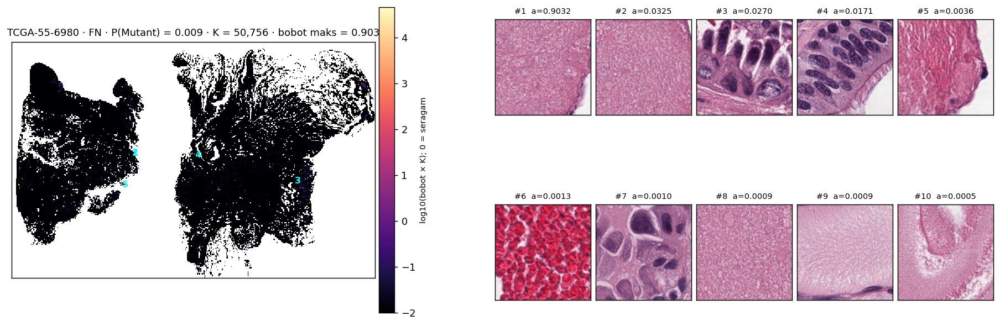

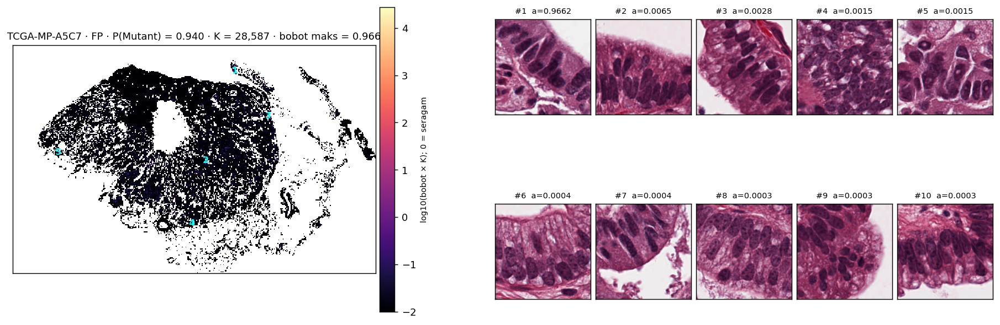

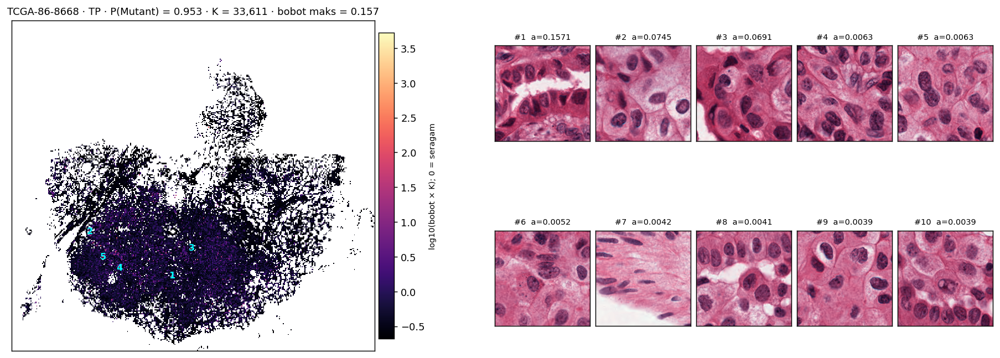

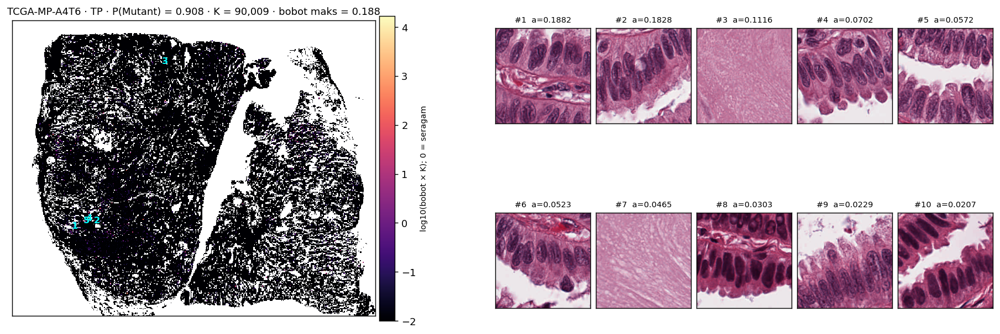

In [ ]:
# ======================================================================
# REVISI 1 · C8 — Heatmap attention + montase top-k patch (2 TP, 1 FN, 1 FP) pada hold-out
# ======================================================================
# Tujuan: melihat patch mana yang diberi bobot attention tertinggi dan memeriksa artefak (pen mark, blur, lipatan jaringan), terutama pada
# TCGA-55-6980 (FN, bobot maks 0,90) dan TCGA-MP-A5C7 (FP, bobot maks 0,97). Bobot attention BUKAN bukti biologis; interpretasi butuh patolog.
TOPK = 10
hp = pd.read_csv(f"{DIR_HOLD}/holdout_predictions_{SIG}.csv").set_index("case_id")
_tp = hp[(hp.label == 1) & (hp["pred@0.5"] == 1)].sort_values("prob_mutant", ascending=False).index.tolist()
CASES_C8 = {"TP": _tp[:2], "FN": ["TCGA-55-6980"], "FP": ["TCGA-MP-A5C7"]}   # TP: 2 dengan probabilitas tertinggi; FN dan FP: kasus yang disebut pembimbing. Ubah bila perlu.
for g, ids in CASES_C8.items():
    for c in ids:
        if c not in TEST: fail(f"{c} bukan kasus hold-out.")

model = MILNet(1920, best_cfg["hidden"], best_cfg["attn"], best_cfg["dropout"], best_cfg["pooling"]).to(X.dev)
model.load_state_dict(torch.load(f"{DIR_HOLD}/final_model_{SIG}.pt", map_location=X.dev)); model.eval()
XY = re.compile(r"_x(\d+)_y(\d+)\.\w+$")

def read_top_patches(cid, idx):
    """Baca patch ke-idx dari ZIP Drive lewat cache seleksi. Mengembalikan list array 224×224×3 (atau None bila ZIP tak terbaca)."""
    try:
        with gzip.open(f"{DIR_PATCHLIST}/{cid}.json.gz", "rt") as f: d = json.load(f)
        fd = os.open(f"{ZIP_DIR}/{C['zip_of'][cid]}", os.O_RDONLY)
        try: return [fetch_patch(fd, d["names"][j], int(d["offs"][j]), int(d["csz"][j]), int(d["ctype"][j])) for j in idx]
        finally: os.close(fd)
    except Exception as e:
        log(f"  patch {cid} tidak terbaca ({type(e).__name__}); montase dilewati, heatmap tetap dibuat"); return None

top_rows = []
for grp, ids in CASES_C8.items():
    for cid in ids:
        with torch.no_grad(): lg, a = model(X.bag(cid)); prob = float(torch.sigmoid(lg))
        a = a.cpu().numpy(); K = len(a); names = X.PATHS[cid]
        if abs(prob - hp.loc[cid, "prob_mutant"]) > 1e-3: log(f"  PERINGATAN {cid}: probabilitas {prob:.4f} != csv {hp.loc[cid, 'prob_mutant']:.4f}")
        xy = np.array([[int(m.group(1)), int(m.group(2))] for m in (XY.search(n) for n in names)])
        step = int(np.gcd.reduce(np.r_[xy[:, 0], xy[:, 1]])) or 224; gx, gy = xy[:, 0] // step, xy[:, 1] // step
        grid = np.full((gy.max() + 1, gx.max() + 1), np.nan); grid[gy, gx] = np.log10(np.maximum(a * K, 1e-2))       # log10(bobot × K): 0 = rata-rata seragam
        order = np.argsort(-a); top = order[:TOPK]; patches = read_top_patches(cid, top)
        fig = plt.figure(figsize=(14, 5.6)); ax = fig.add_axes([0.02, 0.08, 0.38, 0.82])
        im = ax.imshow(grid, cmap="magma", interpolation="nearest"); ax.set_xticks([]); ax.set_yticks([])
        for r_, j in enumerate(top[:5]): ax.text(gx[j], gy[j], str(r_ + 1), color="cyan", fontsize=9, ha="center", va="center", fontweight="bold")
        fig.colorbar(im, ax=ax, fraction=0.04, pad=0.01).set_label("log10(bobot × K); 0 = seragam", fontsize=8)
        ax.set_title(f"{cid} · {grp} · P(Mutant) = {prob:.3f} · K = {K:,} · bobot maks = {a.max():.3f}", fontsize=10)
        if patches is not None:
            for r_, (j, pt) in enumerate(zip(top, patches)):
                axp = fig.add_axes([0.50 + (r_ % 5) * 0.100, 0.52 - (r_ // 5) * 0.46, 0.095, 0.40]); axp.imshow(pt); axp.set_xticks([]); axp.set_yticks([])
                axp.set_title(f"#{r_ + 1}  a={a[j]:.4f}", fontsize=8)
        fig.savefig(f"{DIR_REV}/C8_{grp}_{cid}_{SIG}.png", dpi=130, bbox_inches="tight"); plt.close(fig)
        for r_, j in enumerate(top): top_rows.append(dict(grup=grp, case_id=cid, prob_mutant=prob, K=K, peringkat=r_ + 1, bobot=float(a[j]), bobot_x_K=float(a[j] * K), x=int(xy[j, 0]), y=int(xy[j, 1]), patch=names[j]))
        log(f"  {grp} {cid}: P={prob:.3f} | bobot maks {a.max():.3f} | 10 patch teratas memuat {a[top].sum():.1%} bobot")
save_table(pd.DataFrame(top_rows), "C8_top_patch")
print(f"\nFigur per kasus: {DIR_REV}/C8_<grup>_<case>_{SIG}.png  (kiri: heatmap, angka 1–5 = lima patch teratas; kanan: {TOPK} patch teratas)")
print("Periksa manual: apakah patch teratas pada TCGA-55-6980 (FN) dan TCGA-MP-A5C7 (FP) berisi pen mark, blur, lipatan jaringan, atau jaringan non-tumor. Catat hasilnya di Bab IV; tinjauan patolog diperlukan.")
try:
    from IPython.display import Image, display
    for p_ in sorted(glob.glob(f"{DIR_REV}/C8_*_{SIG}.png")): display(Image(p_))
except ImportError: pass

## Sel 24 — C3: CV berulang 5×5 pada 200 WSI
**Tahap:** analisis sekunder (GPU, ±30–40 menit untuk 5 ulangan; atur `N_REPEATS = 2` untuk uji cepat).
- Konfigurasi final tetap, 5 ulangan × 5 fold pada seluruh 200 WSI (hold-out ikut masuk CV, jadi **bukan** pengganti hold-out). Dua protokol: early stopping pada fold validasi (`es`) dan epoch tetap 21 tanpa melihat fold validasi (`fixed`).
- Selisih `es` − `fixed` = optimisme early stopping; selisih CV utama (0,827) dan hold-out (0,713) juga memuat optimisme pemilihan konfigurasi. Nested CV penuh tidak dikerjakan (±7 jam).
- **Keluaran:** `C3_repeated_cv_per_fold_*.csv`, `C3_repeated_cv_*.json`.

In [ ]:
# ======================================================================
# REVISI 1 · C3 — CV berulang 5×5 pada seluruh 200 WSI (pelengkap hold-out; sekunder)
# ======================================================================
# Konfigurasi final tetap (tanpa tuning ulang). Dua protokol dilaporkan berdampingan:
#   'es'    = early stopping pada fold validasi (seperti CV utama; optimistis)
#   'fixed' = epoch tetap = epoch final (21), dievaluasi pada epoch terakhir tanpa melihat fold validasi -> membuang optimisme early stopping
# Selisih 'es' vs 'fixed' mengukur optimisme early stopping; selisih CV utama (0,827) vs hold-out (0,713) juga memuat optimisme pemilihan konfigurasi.
# Catatan: 40 WSI hold-out ikut masuk CV di sini, jadi hasil ini BUKAN pengganti hold-out (analisis sekunder).
N_REPEATS = 5            # turunkan ke 2 untuk uji cepat (±10 menit di A100); 5 = ±30–40 menit
RUN_FIXED = True

y_all = np.array([X.LABEL[c] for c in ALL]); rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=N_REPEATS, random_state=SEED)
rows = []
for n, (tr, va) in enumerate(rskf.split(ALL, y_all)):
    rep, fold = n // 5 + 1, n % 5 + 1; tr_ids, va_ids = [ALL[i] for i in tr], [ALL[i] for i in va]
    def _es(tr_ids=tr_ids, va_ids=va_ids):
        model, auc, ep = X.train_model(best_cfg, tr_ids, va_ids); yv, pv = X.predict(model, va_ids)
        return dict(auc=float(auc), best_epoch=int(ep), ids=va_ids, p=pv.tolist())
    r = memo(f"c3|es|r{rep}f{fold}", _es); row = dict(repeat=rep, fold=fold, auc_es=r["auc"], epoch_es=r["best_epoch"]); ids_es, p_es = r["ids"], r["p"]
    if RUN_FIXED:
        def _fx(tr_ids=tr_ids, va_ids=va_ids):
            model, _, _ = X.train_model(best_cfg, tr_ids, None, fixed_epochs=EPOCH_FINAL); yv, pv = X.predict(model, va_ids)
            return dict(auc=float(roc_auc_score(yv, pv)), ids=va_ids, p=pv.tolist())
        r2 = memo(f"c3|fixed|r{rep}f{fold}", _fx); row.update(auc_fixed=r2["auc"], ids_fixed=r2["ids"], p_fixed=r2["p"])
    row.update(ids_es=ids_es, p_es=p_es); rows.append(row)
    log(f"  ulangan {rep} fold {fold}: AUC es {row['auc_es']:.4f}" + (f" | fixed {row['auc_fixed']:.4f}" if RUN_FIXED else ""))
R = pd.DataFrame(rows)
def _pooled(col_ids, col_p):                                          # AUC gabungan prediksi OOF per ulangan (lebih stabil dari AUC per fold)
    out = []
    for rep, g in R.groupby("repeat"):
        ids = sum(g[col_ids].tolist(), []); p = sum(g[col_p].tolist(), []); out.append(float(roc_auc_score([X.LABEL[c] for c in ids], p)))
    return out
summ = dict(n_repeats=N_REPEATS, n_fold_total=len(R), auc_es_mean=float(R.auc_es.mean()), auc_es_sd=float(R.auc_es.std(ddof=1)), pooled_es_per_repeat=_pooled("ids_es", "p_es"))
summ["pooled_es_mean"] = float(np.mean(summ["pooled_es_per_repeat"]))
if RUN_FIXED:
    summ.update(auc_fixed_mean=float(R.auc_fixed.mean()), auc_fixed_sd=float(R.auc_fixed.std(ddof=1)), pooled_fixed_per_repeat=_pooled("ids_fixed", "p_fixed"))
    summ["pooled_fixed_mean"] = float(np.mean(summ["pooled_fixed_per_repeat"])); summ["optimisme_early_stopping"] = summ["auc_es_mean"] - summ["auc_fixed_mean"]
save_table(R.drop(columns=[c for c in R if c.startswith(("ids", "p_"))]).round(4), "C3_repeated_cv_per_fold"); save_json(summ, "C3_repeated_cv")
print(f"\n=== C3: CV berulang {N_REPEATS}×5 pada 200 WSI ({len(R)} fold) ===")
print(f"'es'    : AUC per fold {summ['auc_es_mean']:.4f} ± {summ['auc_es_sd']:.4f} | AUC gabungan per ulangan {summ['pooled_es_mean']:.4f} (rentang {min(summ['pooled_es_per_repeat']):.3f}–{max(summ['pooled_es_per_repeat']):.3f})")
if RUN_FIXED:
    print(f"'fixed' : AUC per fold {summ['auc_fixed_mean']:.4f} ± {summ['auc_fixed_sd']:.4f} | AUC gabungan per ulangan {summ['pooled_fixed_mean']:.4f} (rentang {min(summ['pooled_fixed_per_repeat']):.3f}–{max(summ['pooled_fixed_per_repeat']):.3f})")
    print(f"Optimisme early stopping (es − fixed) = {summ['optimisme_early_stopping']:+.4f}")
print(f"Pembanding: CV utama (160 WSI) {CV_RAW[BEST_KEY]['mean_auc']:.4f} | hold-out utama {FINAL['metrics']['AUC']:.4f}")
print("Tafsir: 'fixed' + CV pada 200 WSI memakai seluruh 50 Mutant dan tidak memakai fold validasi untuk memilih epoch; yang masih tersisa adalah optimisme pemilihan "
      "konfigurasi (dipilih dari 30 kandidat pada 160 WSI). Nested CV penuh (tuning ulang di tiap lipatan luar, ±7 jam) tidak dikerjakan; sebut sebagai keterbatasan.")

03:20:06   ulangan 1 fold 1: AUC es 0.8867 | fixed 0.8467
03:21:07   ulangan 1 fold 2: AUC es 0.9167 | fixed 0.7833
03:22:36   ulangan 1 fold 3: AUC es 0.7267 | fixed 0.7167
03:24:21   ulangan 1 fold 4: AUC es 0.7500 | fixed 0.6833
03:25:38   ulangan 1 fold 5: AUC es 0.9200 | fixed 0.8533
03:26:46   ulangan 2 fold 1: AUC es 0.9367 | fixed 0.7500
03:28:27   ulangan 2 fold 2: AUC es 0.7767 | fixed 0.7633
03:30:19   ulangan 2 fold 3: AUC es 0.8633 | fixed 0.7900
03:31:40   ulangan 2 fold 4: AUC es 0.7733 | fixed 0.7267
03:33:04   ulangan 2 fold 5: AUC es 0.8167 | fixed 0.7967
03:34:15   ulangan 3 fold 1: AUC es 0.8567 | fixed 0.6667
03:35:21   ulangan 3 fold 2: AUC es 0.7067 | fixed 0.6633
03:36:43   ulangan 3 fold 3: AUC es 0.8833 | fixed 0.8700
03:37:58   ulangan 3 fold 4: AUC es 0.6667 | fixed 0.6367
03:39:57   ulangan 3 fold 5: AUC es 0.8700 | fixed 0.8100
03:41:45   ulangan 4 fold 1: AUC es 0.8900 | fixed 0.8400
03:43:15   ulangan 4 fold 2: AUC es 0.7667 | fixed 0.7667
03:45:17   ula

## Sel 25 — C2 (1/3): baseline backbone patologi UNI — akses dan pengaturan
**Tahap:** analisis sekunder (GPU; butuh akses UNI di HuggingFace).
- **Prasyarat:** akun HuggingFace, setujui syarat model `MahmoodLab/UNI` (butuh email institusi; lisensi CC-BY-NC-ND, akademik non-komersial), buat token Read, simpan sebagai secret Colab bernama `HF_TOKEN`.
- Sel memuat UNI dan mencetak jumlah parameternya. Bila gagal, pesan menjelaskan penyebabnya (izin belum disetujui/token).
- **DenseNet201 tetap model utama**; C2 hanya pembanding sekunder.

In [ ]:
# ======================================================================
import sys
# REVISI 1 · C2 (1/3) — Baseline backbone patologi UNI: pengaturan & akses model
# ======================================================================
# C2 = analisis SEKUNDER: DenseNet201 (ImageNet) tetap model utama. UNI (MahmoodLab, ViT-L/16, fitur 1024-d) hanya pembanding
# dengan ABMIL, loss, fold, dan konfigurasi yang SAMA (tanpa tuning ulang). Syarat akses UNI:
#   1. akun HuggingFace, buka https://huggingface.co/MahmoodLab/UNI → setujui syarat (butuh email institusi; lisensi CC-BY-NC-ND, hanya akademik non-komersial);
#   2. buat access token (Read) di Settings → Access Tokens;
#   3. di Colab: ikon kunci (Secrets) → tambah secret bernama HF_TOKEN → aktifkan "Notebook access".
C2_TAG = "uni-vitl16"                                              # penanda backbone di metadata fitur & kode data
C2_DIM = 1024
C2_DEVICE = "cuda"
DIR_FEATFILES_C2 = f"{WORK}/features_all_uni_amp16"
C2_TIMING = f"{WORK}/timings_extraction_uni_amp16.csv"
os.makedirs(DIR_FEATFILES_C2, exist_ok=True)

def build_c2_backbone():
    """Muat UNI (keluaran 1024-d). Diganti model kecil hanya saat pengujian kode."""
    import timm
    from huggingface_hub import login
    tok = None
    try:
        from google.colab import userdata; tok = userdata.get("HF_TOKEN")
    except Exception: tok = os.environ.get("HF_TOKEN")
    if not tok: fail("HF_TOKEN tidak ditemukan. Ikuti langkah akses UNI di komentar sel ini (secret Colab bernama HF_TOKEN).")
    login(token=tok)
    try:
        return timm.create_model("hf-hub:MahmoodLab/uni", pretrained=True, init_values=1e-5, dynamic_img_size=True)
    except Exception as e:
        fail(f"Gagal memuat UNI: {repr(e)[:200]}\nPenyebab tersering: izin akses UNI belum disetujui untuk akun ini, atau token salah.")

if "timm" not in sys.modules:
    try: import timm
    except ImportError: os.system("pip -q install timm huggingface_hub"); import timm
C2_BACKBONE_FACTORY = build_c2_backbone                             # dapat diganti untuk uji
_m = C2_BACKBONE_FACTORY()
C2_PARAMS = sum(p.numel() for p in _m.parameters()); del _m
log(f"UNI berhasil dimuat: {C2_PARAMS:,} parameter (DenseNet201: 18,09 juta); fitur {C2_DIM}-d; folder fitur: {DIR_FEATFILES_C2}")

config.json:   0%|          | 0.00/686 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.21GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

16:03:31 UNI berhasil dimuat: 303,350,784 parameter (DenseNet201: 18,09 juta); fitur 1024-d; folder fitur: /content/drive/MyDrive/EGFR_DenseNet201_ABMIL_py/features_all_uni_amp16


## Sel 26 — C2 (2/3): ekstraksi fitur UNI (±sama dengan Sel 7; lanjut otomatis)
**Tahap:** analisis sekunder (GPU; **jam-jaman**, A100 disarankan).
- Mengekstraksi 1024-d fitur UNI untuk semua 11.579.207 patch (patch, normalisasi, presisi sama dengan DenseNet). Hasil: `features_all_uni_amp16/` (≈ 22 GiB di Drive) dan `timings_extraction_uni_amp16.csv`.
- **Waktu:** UNI (ViT-L, ±300 juta parameter) lebih berat daripada DenseNet201; tidak bisa kuperkirakan tepat. Pantau baris `sisa ≈ … menit` setelah beberapa WSI. Bila sesi putus, jalankan ulang Sel 1, 2, 4, 6, 9, 25, 26: WSI yang selesai dilewati.
- Pilih `Stop` jika estimasi tidak sanggup; C2 lalu dicatat sebagai belum dikerjakan.

In [ ]:
# ======================================================================
# REVISI 1 · C2 (2/3) — Ekstraksi fitur UNI (GPU, dapat dilanjutkan bila sesi putus)
# ======================================================================
# Praproses identik dengan DenseNet201: patch 224×224 hasil Macenko, normalisasi mean/std ImageNet (yang juga dipakai UNI), presisi fp16.
# Seluruh patch dipakai (11.579.207). Berkas yang sudah selesai dilewati.
def feat_path_c2(C, cid): return f"{DIR_FEATFILES_C2}/{cid}_{C['NH'][cid]}.pt"

def read_feature_c2(C, cid):
    d = torch.load(feat_path_c2(C, cid), map_location="cpu", weights_only=True); f, m = d["feats"], d["meta"]
    ok = (d["case_id"] == cid and d["label"] == int(C["LABEL"][cid]) and m["backbone"] == C2_TAG and m["prep"] == PREP_TAG and m["prec"] == PREC
          and m["names_hash"] == C["NH"][cid] and f.ndim == 2 and f.shape[1] == C2_DIM and len(d["names"]) == len(f) == int(C["N_USED"][cid])
          and hashlib.md5("\n".join(d["names"]).encode()).hexdigest()[:10] == C["NH"][cid] and bool(torch.isfinite(f.float()).all()))
    if not ok: raise ValueError("isi/metadata fitur UNI tidak cocok dengan inventaris")
    return d

class BatchDSC2(tud.Dataset):
    """Salinan BatchDS (Sel 7): satu item = satu batch patch dari satu WSI, dibaca paralel dari ZIP."""
    def __init__(self, plan, zips, sels, io_threads):
        self.plan, self.zips, self.sels, self.io_threads = plan, zips, sels, io_threads; self._pool, self._fds = None, {}
    def __len__(self): return len(self.plan)
    def _fd(self, k):
        if k not in self._fds:
            for old in list(self._fds): os.close(self._fds.pop(old))
            self._fds[k] = os.open(self.zips[k], os.O_RDONLY)
        return self._fds[k]
    def _drop(self, k):
        fd = self._fds.pop(k, None)
        if fd is not None:
            try: os.close(fd)
            except OSError: pass
    def __getitem__(self, i):
        k, s, e, _ = self.plan[i]; names, offs, csz, ct = self.sels[k]
        if self._pool is None: self._pool = ThreadPoolExecutor(self.io_threads)
        err = None
        for attempt in range(4):
            try:
                fd = self._fd(k); out = np.empty((e - s, 224, 224, 3), np.uint8)
                def work(j): out[j - s] = fetch_patch(fd, names[j], int(offs[j]), int(csz[j]), int(ct[j]))
                list(self._pool.map(work, range(s, e))); return torch.from_numpy(out)
            except (OSError, zlib.error) as ex:
                err = ex; self._drop(k); time.sleep(3 * (attempt + 1))
        raise RuntimeError(f"Gagal membaca {self.zips[k]}: {err}. Bila 'Transport endpoint is not connected': restart sesi, mount ulang Drive, jalankan ulang sel ini (resume otomatis).")

def stage_extract_c2():
    C = load_context(); LABEL, NH, man, zip_of = C["LABEL"], C["NH"], C["man"], C["zip_of"]
    rows = pd.read_csv(C2_TIMING).to_dict("records") if os.path.exists(C2_TIMING) else []
    have = [c for c in man.case_id if os.path.exists(feat_path_c2(C, c))]
    if have:
        def _chk(c):
            try: read_feature_c2(C, c); return c, None
            except Exception as e: return c, repr(e)[:90]
        with ThreadPoolExecutor(4) as ex: res = list(ex.map(_chk, have))
        for c, e in [r for r in res if r[1]]:
            os.replace(feat_path_c2(C, c), feat_path_c2(C, c) + ".bad"); log(f"  fitur UNI {c} tidak valid -> dikarantina, diekstraksi ulang: {e}")
    todo = [c for c in man.case_id if not os.path.exists(feat_path_c2(C, c))]
    log(f"{len(man) - len(todo)} WSI sudah punya fitur UNI, {len(todo)} akan diproses")
    if not todo: return
    dev = torch.device(C2_DEVICE); cuda = dev.type == "cuda"; gpu = torch.cuda.get_device_name(0) if cuda else "CPU-test"
    sels = {}
    for c in todo:
        p = f"{DIR_PATCHLIST}/{c}.json.gz"
        if not os.path.exists(p): fail(f"Seleksi {c} belum ada (cache daftar patch dari tahap scan).")
        with gzip.open(p, "rt") as f: d = json.load(f)
        if d.get("fmt") != FORMAT_VER or d["names_hash"][:10] != NH[c]: fail(f"Cache seleksi {c} tidak cocok inventaris.")
        sels[c] = d
    zips = [f"{ZIP_DIR}/{sels[c]['zip']}" for c in todo]
    sel_arr = [(sels[c]["names"], np.asarray(sels[c]["offs"], np.int64), np.asarray(sels[c]["csz"], np.int64), np.asarray(sels[c]["ctype"], np.int64)) for c in todo]
    plan = []
    for k, c in enumerate(todo):
        n = len(sels[c]["names"])
        for s in range(0, n, A.extract_batch): plan.append((k, s, min(s + A.extract_batch, n), s + A.extract_batch >= n))
    torch.manual_seed(SEED)
    net = C2_BACKBONE_FACTORY().to(dev).eval()
    for p in net.parameters(): p.requires_grad = False
    mean_t = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1) * 255.0
    std_t = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1) * 255.0
    def embed(xb):
        x = ((xb.permute(0, 3, 1, 2).float() - mean_t) / std_t).contiguous()
        with torch.autocast(C2_DEVICE, dtype=torch.float16, enabled=cuda): return net(x)
    loader = tud.DataLoader(BatchDSC2(plan, zips, sel_arr, A.io_threads), batch_size=None, shuffle=False, num_workers=max(1, A.workers), prefetch_factor=3, pin_memory=cuda)
    tot_p = sum(e - s for _, s, e, _ in plan); log(f"{tot_p:,} patch, {len(plan)} batch")
    sync = torch.cuda.synchronize if cuda else (lambda: None)
    with torch.no_grad(): embed(torch.zeros(A.extract_batch, 224, 224, 3, dtype=torch.uint8, device=dev)); sync()
    buf, t_gpu, t_wait, n_done, done_p, t_start = [], 0.0, 0.0, 0, 0, time.perf_counter(); wsi_t0 = time.perf_counter(); it = iter(loader)
    for k, s, e, is_last in plan:
        t0 = time.perf_counter(); xb = next(it); t_wait += time.perf_counter() - t0
        xb = xb.to(dev, non_blocking=True); sync(); t1 = time.perf_counter()
        with torch.no_grad(): out = embed(xb)
        sync(); t_gpu += time.perf_counter() - t1; buf.append(out.half().cpu())
        if not is_last: continue
        cid = todo[k]; feats = torch.cat(buf); buf = []; n_used = len(sel_arr[k][0])
        if tuple(feats.shape) != (n_used, C2_DIM) or not bool(torch.isfinite(feats.float()).all()): fail(f"fitur UNI {cid} tidak valid: {tuple(feats.shape)}")
        t_wall = time.perf_counter() - wsi_t0; t1 = time.perf_counter(); tmp = feat_path_c2(C, cid) + ".tmp"
        torch.save({"case_id": cid, "label": int(LABEL[cid]), "zip": zip_of[cid], "n_total": int(sels[cid]["n_total"]), "names": sels[cid]["names"], "feats": feats,
                    "meta": dict(fmt=FORMAT_VER, backbone=C2_TAG, prep=PREP_TAG, prec=PREC, names_hash=NH[cid], cap="all", seed=SEED)}, tmp)
        os.replace(tmp, feat_path_c2(C, cid)); t_save = time.perf_counter() - t1; n_done += 1
        rows.append(dict(case_id=cid, n_used=n_used, t_gpu_s=t_gpu, t_wait_s=t_wait, t_wall_s=t_wall, t_save_s=t_save, gpu=gpu, prec=PREC))
        pd.DataFrame(rows).to_csv(C2_TIMING, index=False); done_p += n_used; rate = done_p / (time.perf_counter() - t_start)
        log(f"[{n_done}/{len(todo)}] {cid}: {n_used:,} patch | {n_used / max(t_wall, 1e-9):.0f} patch/s | sisa ≈ {(tot_p - done_p) / rate / 60:.0f} menit")
        t_gpu = t_wait = 0.0; wsi_t0 = time.perf_counter()
    del net, loader
    if cuda: torch.cuda.empty_cache()
    log("Ekstraksi fitur UNI selesai.")

stage_extract_c2()

16:03:47 Katalog: 200 WSI, Mutant 50, Wild Type 150 | split: {'train': 160, 'test': 40}
16:03:47 Jumlah zip per split x kelas (harus train 40/120, test 10/30):
y      Mutant  Wildtype  All
split                       
test       10        30   40
train      40       120  160
All        50       150  200
16:03:47 Folder validation/ (197 berkas) hanya QC, TIDAK dipakai model (split tetap train/test).
16:03:47 Hold-out: 40 case (Mutant 10) | Development: 160 case (Mutant 40)
16:03:47   Fold 1: train 128 case (Mutant 32) | val 32 case (Mutant 8)
16:03:47   Fold 2: train 128 case (Mutant 32) | val 32 case (Mutant 8)
16:03:47   Fold 3: train 128 case (Mutant 32) | val 32 case (Mutant 8)
16:03:47   Fold 4: train 128 case (Mutant 32) | val 32 case (Mutant 8)
16:03:47   Fold 5: train 128 case (Mutant 32) | val 32 case (Mutant 8)
16:10:22 200 WSI sudah punya fitur UNI, 0 akan diproses


## Sel 27 — C2 (3/3): ABMIL pada fitur UNI, hold-out, dan uji DeLong berpasangan
**Tahap:** analisis sekunder (GPU, ±15–25 menit setelah fitur selesai).
- Konfigurasi ABMIL final DenseNet dipakai tanpa tuning ulang; CV 5 fold yang sama, model final 21 epoch, hold-out 40 WSI (sekunder), uji DeLong berpasangan, CI bootstrap selisih AUROC, kurva ROC dengan pita CI 95% (sekaligus menjawab D2).
- Sel ini melepas bag DenseNet dari memori; bila ingin menjalankan Sel 19–24 lagi, jalankan Sel 18 dulu.
- **Keluaran:** `C2_cv_per_fold_*.csv`, `C2_holdout_predictions_*.csv`, `C2_uni_vs_densenet_*.json`, `C2_roc_holdout_*.png`.

In [ ]:
# ======================================================================
# REVISI 1 · C2 (3/3) — ABMIL pada fitur UNI: CV, hold-out, dan uji DeLong berpasangan terhadap DenseNet201  [SEKUNDER]
# ======================================================================
# Konfigurasi ABMIL = konfigurasi final DenseNet (wbce|attention|h256|a128|d0.25|lr1e-4|wd1e-5, 21 epoch), TANPA tuning ulang untuk UNI
# (bila ada bias, merugikan UNI; tulis sebagai keterbatasan). Fold CV dan seed (42) sama. Hold-out dipakai hanya untuk perbandingan
# sekunder; tidak dipakai memilih model. DenseNet201 tetap hasil utama.
from scipy import stats
try:                                                         # lepaskan bag DenseNet (Sel 18) agar memori cukup; Sel 19–24 perlu Sel 18 lagi setelah ini
    X.BAGS = {}; import gc; gc.collect(); torch.cuda.empty_cache()
except NameError: pass

class ExpC2(Exp):
    IN_DIM = C2_DIM
    def load_bags(self):
        Ks = self.man.n_used.astype(int); need = int(Ks.sum()) * C2_DIM * 2 / 2**30; head = int(Ks.max()) * 24 * 1024 / 2**30
        tot = torch.cuda.get_device_properties(0).total_memory / 2**30
        try:
            import psutil; avail = psutil.virtual_memory().available / 2**30
        except ImportError: avail = 0.0
        if need + head <= 0.85 * tot: self.storage = "gpu"
        elif avail and need <= 0.80 * avail: self.storage = "cpu"
        else: fail(f"Fitur UNI ({need:.1f} GiB) tidak muat di VRAM ({tot:.1f}) maupun RAM kosong ({avail:.1f}). Pakai runtime High-RAM / A100.")
        log(f"Fitur UNI {need:.1f} GiB -> bag disimpan di {self.storage.upper()}")
        test_ids = set(self.splits["test"]); self.BAGS, self.PATHS, bad = {}, {}, []
        for cid in self.man.case_id:
            try: d = read_feature_c2(self.C, cid)
            except Exception as e: bad.append((cid, repr(e)[:90])); continue
            self.BAGS[cid] = d["feats"].to(self.dev) if self.storage == "gpu" else d["feats"]
            if cid in test_ids: self.PATHS[cid] = d["names"]
        if bad: fail(f"{len(bad)} berkas fitur UNI hilang/rusak: {bad[:3]}. Jalankan ulang Sel 26.")
        self.YT = {c: torch.tensor(float(self.LABEL[c]), device=self.dev) for c in self.BAGS}
        log(f"{len(self.BAGS)} bag UNI dimuat")

_bt, _tag = BACKBONE_TAG, A.tag
BACKBONE_TAG, A.tag = C2_TAG, f"{A.tag}-{C2_TAG}"             # kode data (SIG) & cache CV terpisah dari DenseNet
try: X2 = ExpC2(C)
finally: BACKBONE_TAG, A.tag = _bt, _tag
log(f"Kode data UNI {X2.SIG} (DenseNet: {SIG})")

# ---- (a) CV 5 fold, konfigurasi final tetap ----
_t0 = time.perf_counter(); r_cv = X2.run_cv(best_cfg, True); catat_waktu("c2|uni|cv5", time.perf_counter() - _t0, "5 fold; 0 bila dibaca dari cache CV")
cv_d = np.array(CV_RAW[BEST_KEY]["fold_auc"]); cv_u = np.array(r_cv["fold_auc"])
tcv = pd.DataFrame(dict(fold=range(1, 6), auc_densenet=cv_d, auc_uni=cv_u, selisih_uni_minus_densenet=cv_u - cv_d, best_epoch_uni=r_cv["best_epoch"]))
save_table(tcv.round(4), "C2_cv_per_fold")

# ---- (b) model final (160 WSI, epoch tetap) → hold-out ----
y_te = np.array([X2.LABEL[c] for c in TEST])
_sync_gpu(); _t0 = time.perf_counter(); m_u, _, _ = X2.train_model(best_cfg, DEV, None, fixed_epochs=EPOCH_FINAL); _sync_gpu(); catat_waktu("c2|uni|model_final", time.perf_counter() - _t0, "160 WSI, 21 epoch")
_t0 = time.perf_counter(); _, p_u = X2.predict(m_u, TEST); catat_waktu("c2|uni|inferensi_holdout", time.perf_counter() - _t0, "40 WSI")
hp = pd.read_csv(f"{DIR_HOLD}/holdout_predictions_{SIG}.csv").set_index("case_id").loc[TEST]
assert (hp.label.values == y_te).all(); p_d = hp.prob_mutant.values
pred = pd.DataFrame(dict(case_id=TEST, label=y_te, prob_densenet=p_d, prob_uni=p_u)); save_table(pred.round(6), "C2_holdout_predictions")

def delong_cov(y, ps):
    """DeLong (1988): AUC dan matriks kovarians untuk beberapa prediktor pada kasus yang sama."""
    k = len(ps); pos = [p[y == 1] for p in ps]; neg = [p[y == 0] for p in ps]; m, n = len(pos[0]), len(neg[0])
    psi = lambda x, z: (x[:, None] > z[None, :]) + 0.5 * (x[:, None] == z[None, :])
    V10 = np.stack([psi(pos[i], neg[i]).mean(1) for i in range(k)]); V01 = np.stack([psi(pos[i], neg[i]).mean(0) for i in range(k)])
    return V10.mean(1), np.cov(V10) / m + np.cov(V01) / n
auc2, S = delong_cov(y_te, [p_d, p_u]); d_auc = float(auc2[1] - auc2[0]); se = float(np.sqrt(S[0, 0] + S[1, 1] - 2 * S[0, 1]))
z = d_auc / se if se > 0 else float("nan"); p_two = float(2 * stats.norm.sf(abs(z)))

rng = np.random.RandomState(SEED); n_boot = 1000; grid = np.linspace(0, 1, 101); curves = {"DenseNet201": [], "UNI": []}; boots = []
for _ in range(n_boot):
    i = rng.randint(0, len(y_te), len(y_te))
    if y_te[i].min() == y_te[i].max(): continue
    a = [roc_auc_score(y_te[i], q[i]) for q in (p_d, p_u)]; boots.append(a)
    for nm, q in (("DenseNet201", p_d), ("UNI", p_u)):
        f, t, _ = roc_curve(y_te[i], q[i]); curves[nm].append(np.interp(grid, f, t))
boots = np.array(boots); ci = {"DenseNet201": np.percentile(boots[:, 0], [2.5, 97.5]), "UNI": np.percentile(boots[:, 1], [2.5, 97.5])}
ci_diff = np.percentile(boots[:, 1] - boots[:, 0], [2.5, 97.5])
mu, md = metrics_at(y_te, p_u, 0.5), metrics_at(y_te, p_d, 0.5)
n_abmil = lambda d: d * 256 + 256 + 256 * 128 + 128 + 128 + 1 + 256 + 1
res = dict(catatan="SEKUNDER: DenseNet201 tetap model utama; konfigurasi ABMIL sama, tanpa tuning ulang untuk UNI.",
           kode_data_uni=X2.SIG, uni_params=int(C2_PARAMS), dim_fitur=C2_DIM, abmil_params_uni=int(n_abmil(C2_DIM)), abmil_params_densenet=int(n_abmil(1920)),
           cv=dict(mean_uni=float(cv_u.mean()), sd_uni=float(cv_u.std(ddof=1)), mean_densenet=float(cv_d.mean()), sd_densenet=float(cv_d.std(ddof=1)),
                   selisih_per_fold=(cv_u - cv_d).tolist()),
           holdout=dict(auc_densenet=float(auc2[0]), auc_uni=float(auc2[1]), ci95_boot_densenet=ci["DenseNet201"].tolist(), ci95_boot_uni=ci["UNI"].tolist(),
                        selisih_auc=d_auc, delong_se_selisih=se, delong_z=float(z), delong_p_dua_sisi=p_two, ci95_boot_selisih=ci_diff.tolist(),
                        metrik_uni_thr05=mu, metrik_densenet_thr05=md, n_boot=int(len(boots))))
if os.path.exists(C2_TIMING):
    tt = pd.read_csv(C2_TIMING); res["ekstraksi_uni_jam_total"] = float(tt.t_wall_s.sum() / 3600); res["ekstraksi_uni_patch_per_detik"] = float(tt.n_used.sum() / tt.t_wall_s.sum())
save_json(res, "C2_uni_vs_densenet")

fig, ax = plt.subplots(figsize=(5.2, 5))
for nm, col, q in (("DenseNet201", "#1f77b4", p_d), ("UNI", "#d95f02", p_u)):
    arr = np.array(curves[nm]); lo, hi = np.percentile(arr, [2.5, 97.5], axis=0); f, t, _ = roc_curve(y_te, q)
    ax.fill_between(grid, lo, hi, color=col, alpha=.15, lw=0); a_ = roc_auc_score(y_te, q)
    ax.plot(f, t, color=col, label=f"{nm}: AUROC {a_:.3f} (CI95 {ci[nm][0]:.2f}–{ci[nm][1]:.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=.8); ax.set(xlabel="1 − Spesifisitas", ylabel="Sensitivitas", title="ROC hold-out (n = 40): DenseNet201 vs UNI [sekunder]"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(f"{DIR_REV}/C2_roc_holdout_{SIG}.png", dpi=150); plt.close()

print("\n=== C2 (SEKUNDER): ABMIL pada fitur UNI vs DenseNet201 ===")
print(f"CV 5 fold  : UNI {cv_u.mean():.3f} ± {cv_u.std(ddof=1):.3f} | DenseNet201 {cv_d.mean():.3f} ± {cv_d.std(ddof=1):.3f} | selisih per fold {np.round(cv_u - cv_d, 3).tolist()}")
print(f"Hold-out   : UNI AUROC {auc2[1]:.3f} (CI95 {ci['UNI'][0]:.3f}–{ci['UNI'][1]:.3f}) | DenseNet201 {auc2[0]:.3f} (CI95 {ci['DenseNet201'][0]:.3f}–{ci['DenseNet201'][1]:.3f})")
print(f"Selisih AUROC (UNI − DenseNet) = {d_auc:+.3f} | DeLong berpasangan z = {z:.2f}, p dua-sisi = {p_two:.3f} | CI95 bootstrap selisih [{ci_diff[0]:+.3f}, {ci_diff[1]:+.3f}]")
print(f"Pada thr 0,5: UNI sens {mu['sens']:.2f} spes {mu['spec']:.2f} | DenseNet201 sens {md['sens']:.2f} spes {md['spec']:.2f}")
print("Tafsir: dengan 10 Mutant, selisih yang CI-nya mencakup 0 tidak boleh ditulis sebagai 'UNI lebih baik/buruk'. Tulis sebagai eksploratori.")

16:10:57 Fitur UNI 22.1 GiB -> bag disimpan di GPU
16:12:39 200 bag UNI dimuat
16:12:40 Tanda tangan data 6aa8fa165ef3 | hasil CV tersimpan: 1 konfigurasi
16:12:41 Kode data UNI 6aa8fa165ef3 (DenseNet: 7e86caa80d12)
16:12:43 tersimpan: C2_cv_per_fold_7e86caa80d12.csv
16:13:08 tersimpan: C2_holdout_predictions_7e86caa80d12.csv
16:13:16 tersimpan: C2_uni_vs_densenet_7e86caa80d12.json

=== C2 (SEKUNDER): ABMIL pada fitur UNI vs DenseNet201 ===
CV 5 fold  : UNI 0.826 ± 0.094 | DenseNet201 0.827 ± 0.089 | selisih per fold [-0.031, 0.167, -0.073, -0.068, 0.0]
Hold-out   : UNI AUROC 0.783 (CI95 0.574–0.970) | DenseNet201 0.713 (CI95 0.502–0.914)
Selisih AUROC (UNI − DenseNet) = +0.070 | DeLong berpasangan z = 0.50, p dua-sisi = 0.618 | CI95 bootstrap selisih [-0.207, +0.344]
Pada thr 0,5: UNI sens 0.50 spes 1.00 | DenseNet201 sens 0.60 spes 0.80
Tafsir: dengan 10 Mutant, selisih yang CI-nya mencakup 0 tidak boleh ditulis sebagai 'UNI lebih baik/buruk'. Tulis sebagai eksploratori.


## Sel 28 — Rekap berkas Revisi 1
**Tahap:** laporan (tanpa GPU).
- Menampilkan peta butir umpan balik → berkas dan daftar seluruh berkas di `05_analisis_tambahan_revisi1/`.
- Kirim ke pembimbing semua `*.csv`, `*.json` (kecuali `rev_cache_*.json`) dan `*.png`.

In [ ]:
# ======================================================================
# REVISI 1 — Rekap berkas keluaran + peta butir umpan balik -> berkas
# ======================================================================
peta = [("A1/A2", "wilcoxon_S1_lengkap, wilcoxon_S2_lengkap"), ("A3", "epoch_terbaik_tuning"), ("A4/B3", "ringkasan_data, patch_per_kelompok, distribusi_wsi"),
        ("B1", "tss_label_bagian, ringkasan_data (asosiasi TSS–label), tss_holdout"), ("B4/C4/C6/C9", "analisis_sekunder, kalibrasi_bins, tss_holdout"),
        ("C1", "C1_site_preserved_cv"), ("C2", "C2_uni_vs_densenet, C2_cv_per_fold, C2_holdout_predictions, C2_roc_holdout.png (opsional, Sel 25–27)"), ("C3", "C3_repeated_cv, C3_repeated_cv_per_fold"), ("C5", "C5_ambang_youden, C5_oof_predictions"),
        ("C7", "C7_seed, C7_seed_holdout, C7_seed_cv"), ("C8", "C8_top_patch, C8_*.png"), ("C10", "C10_kompleksitas_inferensi")]
print("Peta butir umpan balik -> berkas (semua berakhiran _%s) di %s:" % (SIG, DIR_REV))
for k, v in peta: print(f"  {k:<12s} {v}")
fs = sorted(Path(DIR_REV).glob("*")); print(f"\n{len(fs)} berkas:")
for p in fs: print(f"  {p.name:<62s} {p.stat().st_size / 1024:>9.1f} KB")
# ringkasan waktu komputasi (hanya langkah yang benar-benar dijalankan; langkah dari cache tidak tercatat)
if os.path.exists(TIME_PATH):
    _tw = pd.read_csv(TIME_PATH); _tw["analisis"] = _tw.langkah.str.split("|").str[0].str.upper()
    _rk = _tw.groupby("analisis").agg(langkah=("detik", "size"), total_menit=("detik", lambda x: x.sum() / 60), rata2_detik=("detik", "mean")).round(2)
    print("\n=== Waktu komputasi per analisis (dari waktu_komputasi_%s.csv) ===" % SIG); print(_rk.to_string())
else:
    print("\nwaktu_komputasi_%s.csv belum ada (belum ada langkah GPU baru yang dihitung)." % SIG)


Peta butir umpan balik -> berkas (semua berakhiran _7e86caa80d12) di /content/drive/MyDrive/EGFR_DenseNet201_ABMIL_py/05_analisis_tambahan_revisi1:
  A1/A2        wilcoxon_S1_lengkap, wilcoxon_S2_lengkap
  A3           epoch_terbaik_tuning
  A4/B3        ringkasan_data, patch_per_kelompok, distribusi_wsi
  B1           tss_label_bagian, ringkasan_data (asosiasi TSS–label), tss_holdout
  B4/C4/C6/C9  analisis_sekunder, kalibrasi_bins, tss_holdout
  C1           C1_site_preserved_cv
  C2           C2_uni_vs_densenet, C2_cv_per_fold, C2_holdout_predictions, C2_roc_holdout.png (opsional, Sel 25–27)
  C3           C3_repeated_cv, C3_repeated_cv_per_fold
  C5           C5_ambang_youden, C5_oof_predictions
  C7           C7_seed, C7_seed_holdout, C7_seed_cv
  C8           C8_top_patch, C8_*.png
  C10          C10_kompleksitas_inferensi

33 berkas:
  C10_kompleksitas_inferensi_7e86caa80d12.csv                          0.8 KB
  C10_kompleksitas_inferensi_7e86caa80d12.json                       

---
# Bagian Revisi 2 — Analisis tambahan atas Umpan Balik 2 pembimbing
**Aturan sama:** hold-out 40 WSI tetap hasil utama (seed 42, threshold 0,5); semua sel di bawah adalah analisis **sekunder/eksploratori** dan hasilnya ditulis ke `05_analisis_tambahan_revisi1/` dengan awalan `UB2_`. Sel 29 dan 33 tanpa GPU. **Urutan disarankan:** 29 → 33 → (Sel 27 harus sudah dijalankan) 30 → Sel 18 lagi → 31 → 32. Sel 18 harus diulang sebelum 31 dan 32 karena Sel 27/30 melepas bag DenseNet201 dari memori.

## Sel 29 — UB2-1/2: shortcut baselines (jumlah patch saja, site saja) dan regresi logistik pada prediksi OOF
**Tahap:** analisis sekunder (tanpa GPU; detik–1 menit; butuh Sel 18 sudah dijalankan pada sesi ini (menyediakan `X`, `DEV`, `TEST`) dan Sel 20 pernah dijalankan agar `C5_oof_predictions_*.csv` ada).
- Baseline jumlah patch (log10 K), site (TSS one-hot), dan gabungan, dilatih dengan fold yang sama dengan CV utama (OOF 160 WSI) dan model akhir pada 160 WSI untuk hold-out 40 WSI. AUROC, CI 95% bootstrap (1.000 resampel), dan selisih terhadap model utama.
- Distribusi jumlah patch per kelas; regresi logistik: skor model + jumlah patch (+ site) pada OOF, dengan uji rasio kemungkinan.
- Opsional: isi `LABELS_CSV_PATH` dengan `labels.csv` tahap unduh untuk membandingkan ukuran berkas per kelas.
- **Keluaran:** `UB2_shortcut_baselines_*.csv`, `UB2_distribusi_patch_per_kelas_*.csv`, `UB2_shortcut_regresi_*.json`, `UB2_per_kasus_*.csv`.

In [ ]:
# ======================================================================
# REVISI 2 · UB2 poin 1–2 — "Shortcut baselines": jumlah patch saja, site (TSS) saja, dan regresi logistik pada prediksi OOF  [SEKUNDER]
# ======================================================================
# Pertanyaan: apakah skor DenseNet201 + ABMIL masih bermakna setelah jumlah patch dan site dikendalikan?
# Semua baseline memakai fold yang SAMA dengan CV utama (OOF 160 WSI) dan model akhir dilatih pada 160 WSI untuk hold-out 40 WSI.
# Hiperparameter ditetapkan di muka (regresi logistik L2, C = 1); C = 0,3 dan 3 hanya sebagai uji sensitivitas, bukan untuk memilih yang terbaik.
# Hold-out TIDAK dipakai untuk memilih apa pun di sini.
from scipy.stats import mannwhitneyu
from sklearn.linear_model import LogisticRegression
import statsmodels.api as sm

LABELS_CSV_PATH = ""      # opsional: path labels.csv dari tahap unduh (kolom patient_id, size_mb) untuk membandingkan ukuran berkas per kelas
N_BOOT = 1000; C_MAIN = 1.0; C_SENS = (0.3, 3.0)

oof = pd.read_csv(f"{DIR_REV}/C5_oof_predictions_{SIG}.csv")                       # case_id, fold, label, prob_mutant (160 WSI)
hp = pd.read_csv(f"{DIR_HOLD}/holdout_predictions_{SIG}.csv")                       # case_id, label, prob_mutant, pred@0.5 (40 WSI)
man = X.man.set_index("case_id")
tss_of_ = lambda c: c.split("-")[1]
for d in (oof, hp):
    d["K"] = d.case_id.map(man.n_used).astype(float); d["tss"] = d.case_id.map(tss_of_)
assert oof.K.notna().all() and hp.K.notna().all() and set(oof.case_id) == set(DEV) and set(hp.case_id) == set(TEST), "daftar kasus tidak cocok dengan split"
TSS_LIST = sorted(oof.tss.unique())                                                # kolom one-hot hanya dari data latih (hold-out tidak ikut menentukan)

def feats(df, kind, mu=None, sd=None):
    cols = []
    if "K" in kind: cols.append(np.log10(df.K.values)[:, None])
    k_part = np.hstack(cols) if cols else None
    if k_part is not None and mu is not None: k_part = (k_part - mu) / sd
    parts = [k_part] if k_part is not None else []
    if "S" in kind: parts.append(np.array([[1.0 if t == s else 0.0 for s in TSS_LIST] for t in df.tss]))
    return np.hstack(parts)

def fit_predict(tr, te, kind, C):
    mu = sd = None
    if "K" in kind: lk = np.log10(tr.K.values)[:, None]; mu, sd = lk.mean(0), lk.std(0) + 1e-9
    m = LogisticRegression(C=C, max_iter=2000).fit(feats(tr, kind, mu, sd), tr.label.values)
    return m.predict_proba(feats(te, kind, mu, sd))[:, 1]

def oof_pred(kind, C):
    p = np.zeros(len(oof))
    for f in sorted(oof.fold.unique()):
        te = oof.fold == f; p[te.values] = fit_predict(oof[~te], oof[te], kind, C)
    return p

KINDS = {"K": "Jumlah patch saja (log10 K)", "S": "Site (TSS) saja", "KS": "Jumlah patch + site"}
yo, yh = oof.label.values, hp.label.values
P_oof = {("main", 0): oof.prob_mutant.values}; P_hold = {("main", 0): hp.prob_mutant.values}
for k in KINDS:
    for c_reg in (C_MAIN,) + C_SENS:                                              # JANGAN pakai nama 'C': itu konteks data global (load_context) yang dipakai sel lain
        P_oof[(k, c_reg)] = oof_pred(k, c_reg); P_hold[(k, c_reg)] = fit_predict(oof, hp, k, c_reg)

# Bootstrap hold-out: skema identik dengan Sel 27 (RandomState(42), 1.000 iterasi, resampel tanpa kedua kelas dilewati) sehingga CI DenseNet201 sama dengan Tabel 22.
rng = np.random.RandomState(SEED); idx_h = []
for _ in range(N_BOOT):
    i = rng.randint(0, len(yh), len(yh))
    if yh[i].min() == yh[i].max(): continue
    idx_h.append(i)
rng = np.random.RandomState(SEED + 1); idx_o = []
for _ in range(N_BOOT):
    i = rng.randint(0, len(yo), len(yo))
    if yo[i].min() == yo[i].max(): continue
    idx_o.append(i)
from scipy.stats import rankdata
def auc_fast(y, p):
    n1 = int(y.sum()); n0 = len(y) - n1; return (rankdata(p)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
BO, BH = {}, {}                                                                    # AUROC bootstrap per baseline (dihitung sekali, dipakai ulang untuk selisih)
for key in P_oof:
    BO[key] = np.array([auc_fast(yo[i], P_oof[key][i]) for i in idx_o]); BH[key] = np.array([auc_fast(yh[i], P_hold[key][i]) for i in idx_h])
pct = lambda a: np.percentile(a, [2.5, 97.5])
rows = []
def add(nm, key):
    ao, ah = roc_auc_score(yo, P_oof[key]), roc_auc_score(yh, P_hold[key]); co, ch = pct(BO[key]), pct(BH[key])
    r = dict(model=nm, auroc_oof160=ao, ci_oof_lo=co[0], ci_oof_hi=co[1], auroc_holdout40=ah, ci_hold_lo=ch[0], ci_hold_hi=ch[1])
    if key != ("main", 0):
        dh, do = pct(BH[("main", 0)] - BH[key]), pct(BO[("main", 0)] - BO[key])
        r.update(selisih_densenet_minus_baseline_holdout=roc_auc_score(yh, P_hold[("main", 0)]) - ah, sel_lo=dh[0], sel_hi=dh[1],
                 selisih_oof=roc_auc_score(yo, P_oof[("main", 0)]) - ao, sel_oof_lo=do[0], sel_oof_hi=do[1])
    rows.append(r)
add("DenseNet201 + ABMIL (model utama)", ("main", 0))
for k, nm in KINDS.items():
    add(f"{nm} (regresi logistik, C = {C_MAIN:g})", (k, C_MAIN))
for k, nm in KINDS.items():
    for c_reg in C_SENS: add(f"  sensitivitas: {nm}, C = {c_reg:g}", (k, c_reg))
T1 = pd.DataFrame(rows); save_table(T1.round(4), "UB2_shortcut_baselines")

# ---- distribusi jumlah patch (dan ukuran berkas bila tersedia) per kelas ----
def dist(df, nm, col="K"):
    out = []
    for lab, ln in ((1, "Mutant"), (0, "Wild-Type")):
        v = df.loc[df.label == lab, col].values; q = np.percentile(v, [25, 50, 75])
        out.append(dict(bagian=nm, kelas=ln, n=len(v), total=float(v.sum()), min=v.min(), q1=q[0], median=q[1], q3=q[2], maks=v.max()))
    u = mannwhitneyu(df.loc[df.label == 1, col], df.loc[df.label == 0, col], alternative="two-sided")
    for r in out: r["p_mannwhitney"] = float(u.pvalue); r["auroc_K_kecil_=_mutant"] = float(1 - u.statistic / ((df.label == 1).sum() * (df.label == 0).sum()))
    return out
T2 = pd.DataFrame(dist(oof, "train/dev (160)") + dist(hp, "hold-out (40)"))
if LABELS_CSV_PATH and os.path.exists(LABELS_CSV_PATH):
    lb = pd.read_csv(LABELS_CSV_PATH).drop_duplicates("patient_id").set_index("patient_id")
    for d in (oof, hp): d["size_mb"] = d.case_id.map(lb.size_mb)
    T2 = pd.concat([T2, pd.DataFrame(dist(oof, "train/dev (160), ukuran berkas MB", "size_mb") + dist(hp, "hold-out (40), ukuran berkas MB", "size_mb"))])
save_table(T2.round(4), "UB2_distribusi_patch_per_kelas")

# ---- regresi logistik pada prediksi OOF: skor model + jumlah patch (+ site) ----
lg = lambda p: np.log(np.clip(p, 1e-4, 1 - 1e-4) / (1 - np.clip(p, 1e-4, 1 - 1e-4)))
def reg(df, p_site, nm):
    z = lambda v: (v - v.mean()) / v.std(ddof=0)
    D = pd.DataFrame(dict(skor=z(lg(df.prob_mutant.values)), logK=z(np.log10(df.K.values)), site=z(lg(p_site))))
    y = df.label.values; res = {}
    def fit(cols):
        try: return sm.Logit(y, sm.add_constant(D[cols])).fit(disp=0, maxiter=200)
        except Exception as e: log(f"  {nm}: model {cols} gagal ({type(e).__name__})"); return None
    m_k, m_ks, m_sk = fit(["logK"]), fit(["logK", "skor"]), fit(["logK", "site", "skor"]); m_s = fit(["logK", "site"])
    for lab, m in (("K", m_k), ("K+skor", m_ks), ("K+site", m_s), ("K+site+skor", m_sk)):
        if m is None: continue
        ci_ = m.conf_int(); res[lab] = dict(llf=float(m.llf), aic=float(m.aic), koef={c: dict(OR_per_SD=float(np.exp(m.params[c])), ci_lo=float(np.exp(ci_.loc[c, 0])), ci_hi=float(np.exp(ci_.loc[c, 1])), p=float(m.pvalues[c])) for c in m.params.index if c != "const"})
    if m_k is not None and m_ks is not None: res["LR_test_skor_setelah_K"] = dict(chi2=float(2 * (m_ks.llf - m_k.llf)), p=float(stats.chi2.sf(2 * (m_ks.llf - m_k.llf), 1)))
    if m_s is not None and m_sk is not None: res["LR_test_skor_setelah_K_dan_site"] = dict(chi2=float(2 * (m_sk.llf - m_s.llf)), p=float(stats.chi2.sf(2 * (m_sk.llf - m_s.llf), 1)))
    return res
from scipy import stats
REG = dict(oof160=reg(oof.assign(), P_oof[("S", C_MAIN)], "OOF"), holdout40_deskriptif=reg(hp.assign(), P_hold[("S", C_MAIN)], "hold-out"))
save_json(dict(catatan="SEKUNDER, eksploratori. 'skor' = logit probabilitas DenseNet201 + ABMIL (OOF untuk 160 WSI; model final untuk 40 WSI hold-out); 'site' = logit probabilitas model site-saja (OOF atau dilatih pada 160 WSI). Semua prediktor distandardisasi (OR per 1 SD). Regresi hold-out (n = 40, 10 Mutant) hanya deskriptif.",
               regresi=REG, spearman_K_vs_prob_holdout=float(stats.spearmanr(hp.K, hp.prob_mutant)[0]), spearman_K_vs_prob_oof=float(stats.spearmanr(oof.K, oof.prob_mutant)[0])), "UB2_shortcut_regresi")
save_table(pd.DataFrame(dict(case_id=list(oof.case_id) + list(hp.case_id), bagian=["dev"] * len(oof) + ["holdout"] * len(hp), label=list(yo) + list(yh), tss=list(oof.tss) + list(hp.tss),
           K=list(oof.K) + list(hp.K), p_model=list(oof.prob_mutant) + list(hp.prob_mutant), p_K=list(P_oof[("K", C_MAIN)]) + list(P_hold[("K", C_MAIN)]), p_site=list(P_oof[("S", C_MAIN)]) + list(P_hold[("S", C_MAIN)]))).round(5), "UB2_per_kasus")

pd.set_option("display.width", 250)
print("\n=== UB2 · Tabel shortcut baselines (AUROC; CI 95% bootstrap 1.000 resampel) ===")
print(T1[["model", "auroc_oof160", "ci_oof_lo", "ci_oof_hi", "auroc_holdout40", "ci_hold_lo", "ci_hold_hi"]].round(3).to_string(index=False))
print("\nSelisih AUROC model utama − baseline (hold-out | OOF):")
print(T1.dropna(subset=["selisih_densenet_minus_baseline_holdout"])[["model", "selisih_densenet_minus_baseline_holdout", "sel_lo", "sel_hi", "selisih_oof", "sel_oof_lo", "sel_oof_hi"]].round(3).to_string(index=False))
print("\n=== Distribusi jumlah patch per kelas ===\n" + T2.round(3).to_string(index=False))
r = REG["oof160"]
print("\n=== Regresi logistik pada OOF (160 WSI): OR per 1 SD ===")
for lab in ("K", "K+skor", "K+site", "K+site+skor"):
    if lab in r: print(f"  {lab:12s}: " + " | ".join(f"{c} OR {v['OR_per_SD']:.2f} ({v['ci_lo']:.2f}–{v['ci_hi']:.2f}), p = {v['p']:.3f}" for c, v in r[lab]["koef"].items()))
for k_ in ("LR_test_skor_setelah_K", "LR_test_skor_setelah_K_dan_site"):
    if k_ in r: print(f"  Uji rasio kemungkinan (skor model setelah dikendalikan): {k_.replace('LR_test_skor_setelah_', '')}: chi2 = {r[k_]['chi2']:.2f}, p = {r[k_]['p']:.3f}")
print("\nTafsir: bila AUROC model utama tidak jauh di atas baseline jumlah patch/site (selisih CI mencakup 0) atau skor model tidak bermakna setelah K/site dikendalikan, "
      "sinyal morfologi tidak dapat dipisahkan dari shortcut pada data ini. Tulis apa adanya; hold-out tetap hasil utama.")

14:49:36 tersimpan: UB2_shortcut_baselines_7e86caa80d12.csv
14:49:37 tersimpan: UB2_distribusi_patch_per_kelas_7e86caa80d12.csv
14:49:37 tersimpan: UB2_shortcut_regresi_7e86caa80d12.json
14:49:38 tersimpan: UB2_per_kasus_7e86caa80d12.csv

=== UB2 · Tabel shortcut baselines (AUROC; CI 95% bootstrap 2.000 resampel) ===
                                                model  auroc_oof160  ci_oof_lo  ci_oof_hi  auroc_holdout40  ci_hold_lo  ci_hold_hi
                    DenseNet201 + ABMIL (model utama)         0.774      0.688      0.852            0.713       0.502       0.914
Jumlah patch saja (log10 K) (regresi logistik, C = 1)         0.689      0.572      0.803            0.677       0.485       0.850
            Site (TSS) saja (regresi logistik, C = 1)         0.579      0.456      0.698            0.717       0.502       0.896
        Jumlah patch + site (regresi logistik, C = 1)         0.686      0.571      0.799            0.647       0.423       0.849
   sensitivitas: Jumlah pa

## Sel 30 — UB2-7: UNI dengan 5 seed
**Tahap:** analisis sekunder (GPU; ±10–20 menit; **Sel 27 harus sudah dijalankan di sesi yang sama**, dan Sel 19 sudah pernah dijalankan).
- Model final UNI (160 WSI, 21 epoch) untuk seed 42–46 dan CV 5 fold per seed (atur `RUN_CV_SEEDS = False` bila hanya hold-out). Dibandingkan seed demi seed dengan DenseNet201 (cache Sel 19). Seed 42 harus mereproduksi 0,783.
- **Keluaran:** `UB2_uni_5seed_holdout_*.csv`, `UB2_uni_5seed_cv_*.csv`, `UB2_uni_5seed_*.json`.

In [ ]:
# ======================================================================
# REVISI 2 · UB2 poin 7 — UNI dengan 5 seed (perbandingan rerata-lawan-rerata yang adil terhadap DenseNet201)  [SEKUNDER]
# ======================================================================
# Prasyarat: Sel 25–27 sudah dijalankan pada sesi ini (X2 = ABMIL pada fitur UNI sudah ada). Konfigurasi ABMIL sama dengan DenseNet201, tanpa tuning ulang.
# Hasil DenseNet201 per seed dibaca dari cache Sel 19 (C7); bila belum ada, Sel 19 harus dijalankan lebih dulu.
SEEDS = [42, 43, 44, 45, 46]; RUN_CV_SEEDS = True
try: X2
except NameError: raise RuntimeError("X2 (UNI) belum ada: jalankan Sel 25, 26, dan 27 lebih dulu pada sesi ini.")
y_te = np.array([X2.LABEL[c] for c in TEST])

def _final_u(s):
    m, _, _ = X2.train_model(best_cfg, DEV, None, fixed_epochs=EPOCH_FINAL, seed=s); y, p = X2.predict(m, TEST)
    return dict(p=[float(v) for v in p], auc=float(roc_auc_score(y, p)))
def _dn_cached(s):
    return memo(f"c7|final|{s}", lambda: (_ for _ in ()).throw(RuntimeError(f"hasil DenseNet201 seed {s} belum ada di cache: jalankan Sel 19 (C7) lebih dulu.")))

rows = []
for s in SEEDS:
    t0 = time.perf_counter(); ru = memo(f"c2u|final|{s}", lambda s=s: _final_u(s)); catat_waktu(f"ub2|uni|final|seed{s}", time.perf_counter() - t0, "160 WSI, 21 epoch; 0 bila dari cache")
    rd = _dn_cached(s); pu, pd_ = np.array(ru["p"]), np.array(rd["p"])
    mu_, md_ = metrics_at(y_te, pu, 0.5), metrics_at(y_te, pd_, 0.5)
    rows.append(dict(seed=s, auc_densenet=rd["auc"], auc_uni=ru["auc"], selisih_uni_minus_densenet=ru["auc"] - rd["auc"],
                     sens_densenet=md_["sens"], spes_densenet=md_["spec"], sens_uni=mu_["sens"], spes_uni=mu_["spec"]))
    log(f"  seed {s}: DenseNet {rd['auc']:.4f} | UNI {ru['auc']:.4f}")
T = pd.DataFrame(rows)
if abs(T.loc[T.seed == 42, "auc_uni"].iloc[0] - 0.783) > 0.005: log("PERINGATAN: UNI seed 42 tidak mereproduksi 0,783 hold-out pada Sel 27 (cek determinisme GPU/versi).")
save_table(T.round(4), "UB2_uni_5seed_holdout")
res = dict(seeds=SEEDS, holdout=dict(mean_densenet=float(T.auc_densenet.mean()), sd_densenet=float(T.auc_densenet.std(ddof=1)), mean_uni=float(T.auc_uni.mean()), sd_uni=float(T.auc_uni.std(ddof=1)),
           min_uni=float(T.auc_uni.min()), max_uni=float(T.auc_uni.max()), mean_selisih=float(T.selisih_uni_minus_densenet.mean()), sd_selisih=float(T.selisih_uni_minus_densenet.std(ddof=1)),
           n_seed_uni_lebih_tinggi=int((T.selisih_uni_minus_densenet > 0).sum())))

if RUN_CV_SEEDS:
    rc = []
    for s in SEEDS:
        aucs = []
        for i, f in enumerate(X2.splits["folds"], 1):
            def _fit(f=f, s=s):
                _, auc, ep = X2.train_model(best_cfg, f["train"], f["val"], seed=s); return dict(auc=float(auc), best_epoch=int(ep))
            t0 = time.perf_counter(); r = memo(f"c2u|cv|{s}|{i}", _fit); catat_waktu(f"ub2|uni|cv|seed{s}|fold{i}", time.perf_counter() - t0, "0 bila dari cache"); aucs.append(r["auc"])
        rc.append(dict(seed=s, **{f"fold{i + 1}": a for i, a in enumerate(aucs)}, mean_auc_uni=float(np.mean(aucs)), sd_fold_uni=float(np.std(aucs, ddof=1))))
        log(f"  CV seed {s}: UNI rata-rata AUC {np.mean(aucs):.4f}")
    TC = pd.DataFrame(rc)
    try:
        c7 = pd.read_csv(f"{DIR_REV}/C7_seed_cv_{SIG}.csv").set_index("seed"); TC["mean_auc_densenet"] = TC.seed.map(c7.mean_auc)
    except Exception: TC["mean_auc_densenet"] = np.nan
    save_table(TC.round(4), "UB2_uni_5seed_cv")
    res["cv"] = dict(mean_uni=float(TC.mean_auc_uni.mean()), sd_uni=float(TC.mean_auc_uni.std(ddof=1)), mean_densenet=float(TC.mean_auc_densenet.mean()), sd_densenet=float(TC.mean_auc_densenet.std(ddof=1)))
save_json(res, "UB2_uni_5seed")
print("\n=== UB2 · UNI vs DenseNet201, 5 seed (hold-out; sekunder) ===\n" + T.round(3).to_string(index=False))
h = res["holdout"]
print(f"Hold-out: DenseNet201 {h['mean_densenet']:.3f} ± {h['sd_densenet']:.3f} | UNI {h['mean_uni']:.3f} ± {h['sd_uni']:.3f} (rentang {h['min_uni']:.3f}–{h['max_uni']:.3f}) | "
      f"selisih rata-rata {h['mean_selisih']:+.3f} ± {h['sd_selisih']:.3f} | UNI lebih tinggi pada {h['n_seed_uni_lebih_tinggi']} dari 5 seed")
if RUN_CV_SEEDS: c = res["cv"]; print(f"CV 5 lipatan (rerata antar-seed): DenseNet201 {c['mean_densenet']:.3f} ± {c['sd_densenet']:.3f} | UNI {c['mean_uni']:.3f} ± {c['sd_uni']:.3f}")
print("Tafsir: hanya 5 seed pada 40 WSI hold-out (10 Mutant); tidak ada uji formal yang bermakna. Tulis sebagai eksploratori. Jangan klaim UNI lebih baik kecuali selisihnya konsisten pada semua seed DAN CV.")

16:14:05   seed 42: DenseNet 0.7133 | UNI 0.7833
16:14:28   seed 43: DenseNet 0.6900 | UNI 0.8033
16:14:50   seed 44: DenseNet 0.6200 | UNI 0.8367
16:15:13   seed 45: DenseNet 0.6800 | UNI 0.8100
16:15:37   seed 46: DenseNet 0.6667 | UNI 0.8333
16:15:37 tersimpan: UB2_uni_5seed_holdout_7e86caa80d12.csv
16:17:17   CV seed 42: UNI rata-rata AUC 0.8260
16:18:37   CV seed 43: UNI rata-rata AUC 0.8208
16:20:05   CV seed 44: UNI rata-rata AUC 0.8333
16:21:45   CV seed 45: UNI rata-rata AUC 0.8281
16:23:31   CV seed 46: UNI rata-rata AUC 0.8187
16:23:32 tersimpan: UB2_uni_5seed_cv_7e86caa80d12.csv
16:23:32 tersimpan: UB2_uni_5seed_7e86caa80d12.json

=== UB2 · UNI vs DenseNet201, 5 seed (hold-out; sekunder) ===
 seed  auc_densenet  auc_uni  selisih_uni_minus_densenet  sens_densenet  spes_densenet  sens_uni  spes_uni
   42         0.713    0.783                       0.070            0.6          0.800       0.5       1.0
   43         0.690    0.803                       0.113            0.6  

## Sel 31 — UB2-3: ekspor 10 patch teratas untuk 40 WSI hold-out, untuk tinjauan patolog (buta label)
**Tahap:** analisis sekunder (GPU + akses ZIP Drive; ±10 menit; jalankan Sel 18 lebih dulu).
- 40 montase PNG (nama berupa kode acak, tanpa label dan probabilitas), lembar penilaian kosong, dan berkas kunci terpisah. Berikan ke patolog **hanya** `UB2_untuk_patolog_*.zip`.
- Setelah lembar terisi, jalankan `ringkas_patolog('<path>')` untuk proporsi tumor per kasus dan per kelompok (TP/FN/FP/TN).

In [ ]:
# ======================================================================
# REVISI 2 · UB2 poin 3 — Ekspor 10 patch ber-attention tertinggi untuk SELURUH 40 WSI hold-out, untuk dinilai patolog (BUTA label)  [SEKUNDER]
# ======================================================================
# Prasyarat: jalankan Sel 18 lebih dulu (memuat bag DenseNet201 ke X); jalankan setelah Sel 29–30.
# Keluaran di <DIR_REV>/patolog_top10/: 40 montase PNG (nama = kode acak, TANPA label/probabilitas), lembar penilaian CSV (kosong), dan kunci (case_id, label, probabilitas) terpisah.
# Kategori penilaian: T = tumor, N = epitel/jaringan paru normal, S = stroma/jaringan ikat, I = inflamasi/limfosit, A = artefak (lipatan, blur, pen mark), L = latar/kosong, U = tidak jelas
import hashlib, zipfile
TOPK = 10; OUTP = f"{DIR_REV}/patolog_top10"; os.makedirs(OUTP, exist_ok=True)
hp = pd.read_csv(f"{DIR_HOLD}/holdout_predictions_{SIG}.csv").set_index("case_id")
model = MILNet(1920, best_cfg["hidden"], best_cfg["attn"], best_cfg["dropout"], best_cfg["pooling"]).to(X.dev)
model.load_state_dict(torch.load(f"{DIR_HOLD}/final_model_{SIG}.pt", map_location=X.dev)); model.eval()
XY = re.compile(r"_x(\d+)_y(\d+)\.\w+$")
def _read(cid, idx):
    with gzip.open(f"{DIR_PATCHLIST}/{cid}.json.gz", "rt") as f: d = json.load(f)
    fd = os.open(f"{ZIP_DIR}/{C['zip_of'][cid]}", os.O_RDONLY)
    try: return [fetch_patch(fd, d["names"][j], int(d["offs"][j]), int(d["csz"][j]), int(d["ctype"][j])) for j in idx]
    finally: os.close(fd)
code = {c: "K" + hashlib.md5(f"{SEED}-{c}".encode()).hexdigest()[:6].upper() for c in TEST}
assert len(set(code.values())) == len(TEST)
key_rows, sheet_rows, fail_ = [], [], []
for n, cid in enumerate(sorted(TEST, key=lambda c: code[c]), 1):
    try:
        with torch.no_grad(): lg, a = model(X.bag(cid)); prob = float(torch.sigmoid(lg))
        a = a.cpu().numpy(); K = len(a); top = np.argsort(-a)[:TOPK]; names = X.PATHS[cid]; pts = _read(cid, top)
        fig, axs = plt.subplots(2, 5, figsize=(14, 6.2))
        for r_, (j, pt, ax) in enumerate(zip(top, pts, axs.ravel())):
            ax.imshow(pt); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{code[cid]} · #{r_ + 1}", fontsize=10)
            sheet_rows.append(dict(kode=code[cid], peringkat=r_ + 1, penilaian_patolog="", catatan="")); m_ = XY.search(names[j])
            key_rows.append(dict(kode=code[cid], case_id=cid, label=int(hp.loc[cid, "label"]), prob_mutant=prob, K=K, peringkat=r_ + 1, bobot=float(a[j]), x=int(m_.group(1)), y=int(m_.group(2)), patch=names[j]))
        plt.suptitle(f"{code[cid]}: 10 patch dengan bobot attention tertinggi (224 × 224 px, 40×)", fontsize=11); plt.tight_layout()
        fig.savefig(f"{OUTP}/{code[cid]}.png", dpi=110); plt.close(fig)
        if n % 10 == 0: log(f"  {n}/{len(TEST)} kasus")
    except Exception as e: fail_.append((cid, repr(e)[:100])); log(f"  GAGAL {cid}: {e!r}"[:200])
pd.DataFrame(sheet_rows).to_csv(f"{OUTP}/LEMBAR_PENILAIAN_patolog.csv", index=False)
pd.DataFrame(key_rows).to_csv(f"{DIR_REV}/UB2_patolog_KUNCI_{SIG}.csv", index=False)         # JANGAN diberikan ke patolog
with zipfile.ZipFile(f"{DIR_REV}/UB2_untuk_patolog_{SIG}.zip", "w") as z:
    for f in sorted(os.listdir(OUTP)): z.write(f"{OUTP}/{f}", f)
print(f"\nSelesai: {len(TEST) - len(fail_)}/{len(TEST)} kasus. Berikan ke patolog HANYA: {DIR_REV}/UB2_untuk_patolog_{SIG}.zip (montase + lembar penilaian).")
print(f"Simpan kunci sendiri: {DIR_REV}/UB2_patolog_KUNCI_{SIG}.csv. Setelah lembar terisi, jalankan fungsi ringkas_patolog('<path lembar terisi>') di bawah.")
if fail_: print("Gagal:", fail_)

def ringkas_patolog(path):
    """Proporsi top-10 patch yang tumor per kasus, per kelas, dan per kelompok prediksi (TP/FN/FP/TN), dari lembar penilaian yang sudah diisi patolog."""
    s = pd.read_csv(path); k = pd.read_csv(f"{DIR_REV}/UB2_patolog_KUNCI_{SIG}.csv").merge(s[["kode", "peringkat", "penilaian_patolog"]], on=["kode", "peringkat"])
    k["penilaian_patolog"] = k.penilaian_patolog.astype(str).str.strip().str.upper().replace({"NAN": ""})
    if (k.penilaian_patolog == "").any(): log(f"PERINGATAN: {(k.penilaian_patolog == '').sum()} baris belum dinilai (dikeluarkan).")
    k = k[k.penilaian_patolog != ""]; k["tumor"] = (k.penilaian_patolog == "T").astype(int)
    per = k.groupby(["kode", "case_id", "label", "prob_mutant"]).agg(n_dinilai=("tumor", "size"), prop_tumor=("tumor", "mean")).reset_index()
    per["pred"] = (per.prob_mutant >= 0.5).astype(int); per["grup"] = np.select([(per.label == 1) & (per.pred == 1), (per.label == 1) & (per.pred == 0), (per.label == 0) & (per.pred == 1)], ["TP", "FN", "FP"], "TN")
    save_table(per.round(4), "UB2_patolog_per_kasus")
    out = dict(rata_prop_tumor=float(per.prop_tumor.mean()), median_prop_tumor=float(per.prop_tumor.median()), n_kasus=int(len(per)), per_grup=per.groupby("grup").prop_tumor.agg(["count", "mean", "median"]).round(3).to_dict("index"),
               distribusi_kategori=k.penilaian_patolog.value_counts().to_dict(), n_kasus_prop_tumor_kurang_dari_50=int((per.prop_tumor < 0.5).sum()))
    save_json(out, "UB2_patolog_ringkasan"); print(json.dumps(out, indent=1, ensure_ascii=False)); return per

15:49:39   10/40 kasus
15:52:15   20/40 kasus
15:55:29   30/40 kasus
15:58:42   40/40 kasus

Selesai: 40/40 kasus. Berikan ke patolog HANYA: /content/drive/MyDrive/EGFR_DenseNet201_ABMIL_py/05_analisis_tambahan_revisi1/UB2_untuk_patolog_7e86caa80d12.zip (montase + lembar penilaian).
Simpan kunci sendiri: /content/drive/MyDrive/EGFR_DenseNet201_ABMIL_py/05_analisis_tambahan_revisi1/UB2_patolog_KUNCI_7e86caa80d12.csv. Setelah lembar terisi, jalankan fungsi ringkas_patolog('<path lembar terisi>') di bawah.


## Sel 32 — UB2-14: heatmap attention sebagai overlay transparan di atas thumbnail H&E (skala persentil)
**Tahap:** analisis sekunder (GPU; menit; jalankan Sel 18 lebih dulu).
- Warna = persentil bobot attention dalam slide (0–100), alpha 0,55, lima patch teratas ditandai. Isi `THUMB_DIR` dengan folder `Tissue_Detection` dari server praproses agar latarnya H&E; tanpa itu latar abu-abu.
- **Keluaran:** `UB2_overlay_<kasus>_*.png`.

14:50:17   overlay TCGA-86-8668 selesai (latar: tissue detection; patch #1 = 0.157 bobot; top-10 = 0.335)
14:50:23   overlay TCGA-MP-A4T6 selesai (latar: tissue detection; patch #1 = 0.188 bobot; top-10 = 0.783)
14:50:27   overlay TCGA-55-6980 selesai (latar: tissue detection; patch #1 = 0.903 bobot; top-10 = 0.988)
14:50:31   overlay TCGA-MP-A5C7 selesai (latar: tissue detection; patch #1 = 0.966 bobot; top-10 = 0.980)


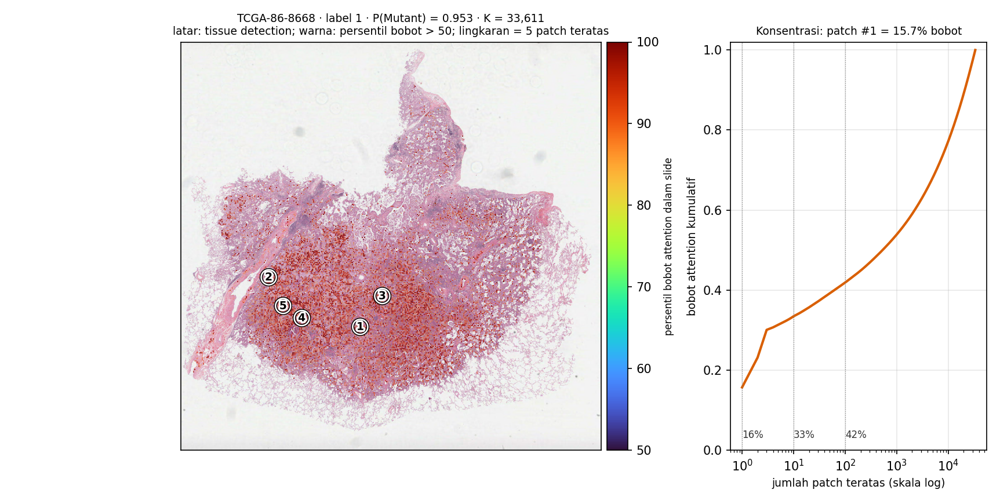

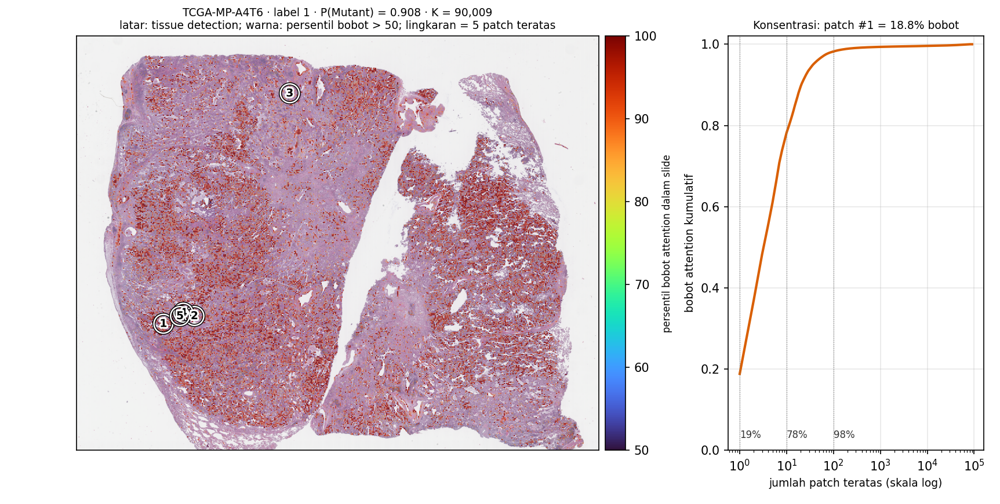

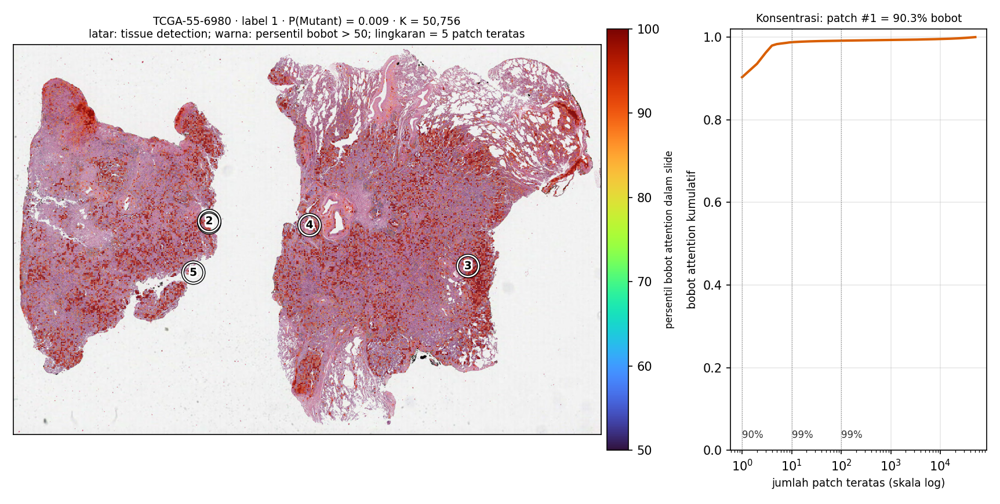

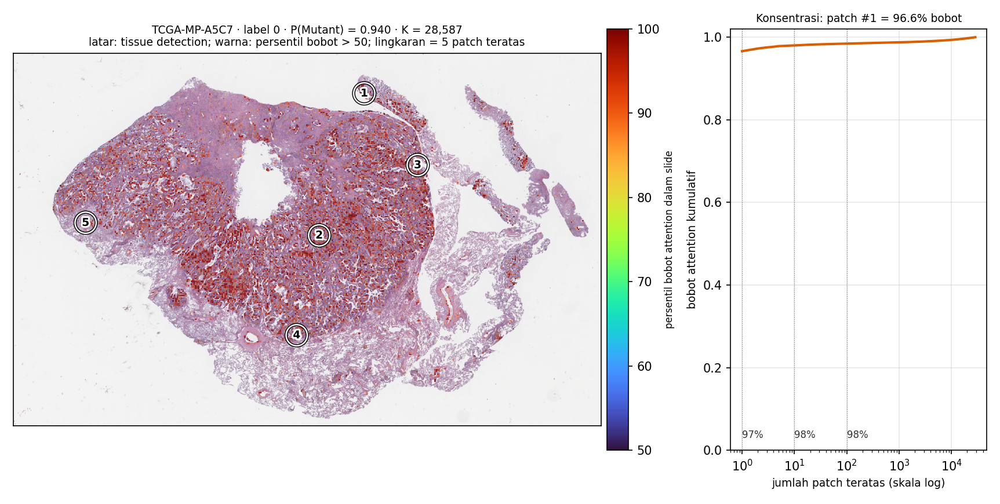

In [ ]:
# ======================================================================
# REVISI 2 · UB2 poin 14 — Heatmap attention: overlay transparan di atas latar H&E + kurva konsentrasi bobot  [SEKUNDER]
# ======================================================================
# Prasyarat: Sel 18 (bag DenseNet201 di X). Latar H&E (pilih satu; otomatis berurutan):
#   1) THUMB_DIR berisi file <slide>_tissue_detection.png dari tahap tissue detection (isi path Drive-nya bila folder itu ada di Drive), atau
#   2) mosaik dari patch hasil Macenko di Drive (ZIP_DIR): tiap patch dikecilkan menjadi TILE × TILE piksel dan disusun menurut koordinat. Tanpa file tambahan, ±1–4 menit per kasus.
# Warna overlay = persentil bobot attention dalam slide (0–100); hanya persentil > 50 yang diberi warna agar latar tetap terlihat. Panel kanan = kurva bobot kumulatif
# patch terurut: menunjukkan seberapa terkonsentrasi attention (mis. satu patch memegang > 90%), sesuatu yang tidak terlihat pada skala persentil.
THUMB_DIR = "/content/drive/MyDrive/TCGA-LUAD-WSI/Tissue_Detection"     # kosongkan ("") untuk memakai mosaik dari patch Macenko
CASES_OV = ["TCGA-86-8668", "TCGA-MP-A4T6", "TCGA-55-6980", "TCGA-MP-A5C7"]      # TP, TP, FN, FP (Gambar 4–7); bisa diganti/ditambah (hanya kasus hold-out)
TILE = 8; N_THREADS = 8; SCALE_TD = 32.0
import cv2
import matplotlib.patheffects as pe
from scipy.stats import rankdata
from concurrent.futures import ThreadPoolExecutor
model = MILNet(1920, best_cfg["hidden"], best_cfg["attn"], best_cfg["dropout"], best_cfg["pooling"]).to(X.dev)
model.load_state_dict(torch.load(f"{DIR_HOLD}/final_model_{SIG}.pt", map_location=X.dev)); model.eval()
hp = pd.read_csv(f"{DIR_HOLD}/holdout_predictions_{SIG}.csv").set_index("case_id"); XY = re.compile(r"_x(\d+)_y(\d+)\.\w+$")

def thumb_from_td(cid):
    if not THUMB_DIR: return None
    p = f"{THUMB_DIR}/{os.path.basename(C['zip_of'][cid]).replace('.zip', '')}_tissue_detection.png"
    if not os.path.exists(p): return None
    im = plt.imread(p); return im[:, : im.shape[1] // 3, :3]

def thumb_from_mosaic(cid, gx, gy):
    cache = f"{DIR_REV}/UB2_mosaik_{cid}_t{TILE}.png"
    if os.path.exists(cache): return cv2.cvtColor(cv2.imread(cache), cv2.COLOR_BGR2RGB) / 255.0
    with gzip.open(f"{DIR_PATCHLIST}/{cid}.json.gz", "rt") as f: d = json.load(f)
    n = len(d["names"]); assert n == len(gx), "daftar patch tidak cocok dengan bag"
    mos = np.full(((gy.max() + 1) * TILE, (gx.max() + 1) * TILE, 3), 255, np.uint8)
    def work(js):
        fd = os.open(f"{ZIP_DIR}/{C['zip_of'][cid]}", os.O_RDONLY)                        # satu fd per thread
        try:
            for j in js:
                pt = np.asarray(fetch_patch(fd, d["names"][j], int(d["offs"][j]), int(d["csz"][j]), int(d["ctype"][j])))
                mos[gy[j] * TILE:(gy[j] + 1) * TILE, gx[j] * TILE:(gx[j] + 1) * TILE] = cv2.resize(pt, (TILE, TILE), interpolation=cv2.INTER_AREA)
        finally: os.close(fd)
    t0 = time.perf_counter()
    with ThreadPoolExecutor(N_THREADS) as ex: list(ex.map(work, np.array_split(np.arange(n), N_THREADS * 4)))
    log(f"  mosaik {cid}: {n:,} patch dibaca dalam {time.perf_counter() - t0:.0f} s")
    cv2.imwrite(cache, cv2.cvtColor(mos, cv2.COLOR_RGB2BGR)); return mos / 255.0

def overlay_rgba(gx, gy, pct_, shape, tile):
    """RGBA: warna turbo menurut persentil; alfa 0 untuk persentil <= 50, naik sampai 0,75 pada persentil 100."""
    cmap = plt.get_cmap("turbo"); out = np.zeros(shape + (4,))
    for x, y, v in zip(gx, gy, pct_):
        if v <= 50: continue
        c = cmap(v / 100.0); out[int(y * tile): int((y + 1) * tile), int(x * tile): int((x + 1) * tile)] = (c[0], c[1], c[2], 0.75 * (v - 50) / 50)
    return out

for cid in CASES_OV:
    if cid not in TEST: log(f"  {cid} bukan kasus hold-out, dilewati"); continue
    with torch.no_grad(): lg, a = model(X.bag(cid)); prob = float(torch.sigmoid(lg))
    a = a.cpu().numpy(); K = len(a); pct_ = rankdata(a) / K * 100; names = X.PATHS[cid]
    xy = np.array([[int(m.group(1)), int(m.group(2))] for m in (XY.search(n) for n in names)]); step = int(np.gcd.reduce(np.r_[xy[:, 0], xy[:, 1]])) or 224
    gx, gy = xy[:, 0] // step, xy[:, 1] // step; src = "tissue detection"
    th = thumb_from_td(cid)
    if th is not None: tile = 224.0 / SCALE_TD; bg = th                                   # thumbnail tissue detection = level 0 / 32 -> 1 patch 224 px = 7 px
    else:
        try: bg = thumb_from_mosaic(cid, gx, gy); tile = TILE; src = "mosaik patch Macenko"
        except Exception as e: log(f"  mosaik {cid} gagal ({type(e).__name__}: {str(e)[:80]}); latar abu-abu"); tile = TILE; bg = np.full(((gy.max() + 1) * TILE, (gx.max() + 1) * TILE, 3), 0.93); src = "tanpa latar"
    H, W = bg.shape[:2]; ov = overlay_rgba(gx, gy, pct_, (H, W), tile)
    order = np.argsort(-a); cum = np.cumsum(a[order])
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11.5, 5.8), gridspec_kw=dict(width_ratios=[3, 1.25]))
    ax.imshow(bg); ax.imshow(ov, interpolation="nearest")
    for r_, j in enumerate(order[:5]):
        cx, cy = (gx[j] + 0.5) * tile, (gy[j] + 0.5) * tile; ax.add_patch(plt.Circle((cx, cy), max(W, H) * 0.018, fill=False, ec="black", lw=2.6)); ax.add_patch(plt.Circle((cx, cy), max(W, H) * 0.018, fill=False, ec="white", lw=1.2))
        ax.text(cx, cy, str(r_ + 1), color="black", fontsize=9, ha="center", va="center", fontweight="bold", path_effects=[pe.withStroke(linewidth=3, foreground="white")])
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{cid} · label {int(hp.loc[cid, 'label'])} · P(Mutant) = {prob:.3f} · K = {K:,}\nlatar: {src}; warna: persentil bobot > 50; lingkaran = 5 patch teratas", fontsize=9)
    sm_ = plt.cm.ScalarMappable(cmap="turbo", norm=plt.Normalize(50, 100)); fig.colorbar(sm_, ax=ax, fraction=0.035, pad=0.01).set_label("persentil bobot attention dalam slide", fontsize=8)
    ax2.plot(np.arange(1, K + 1), cum, color="#d95f02", lw=2); ax2.set_xscale("log"); ax2.set_ylim(0, 1.02); ax2.grid(alpha=.3)
    for k_ in (1, 10, 100): ax2.axvline(k_, color="gray", lw=.6, ls=":"); ax2.text(k_, 0.03, f"{cum[k_ - 1]:.0%}", fontsize=8, ha="left", color="#333")
    ax2.set_xlabel("jumlah patch teratas (skala log)", fontsize=9); ax2.set_ylabel("bobot attention kumulatif", fontsize=9); ax2.set_title(f"Konsentrasi: patch #1 = {a.max():.1%} bobot", fontsize=9)
    plt.tight_layout(); fig.savefig(f"{DIR_REV}/UB2_overlay_{cid}_{SIG}.png", dpi=150); plt.close(fig); log(f"  overlay {cid} selesai (latar: {src}; patch #1 = {a.max():.3f} bobot; top-10 = {cum[9]:.3f})")
try:
    from IPython.display import Image, display
    for cid in CASES_OV:
        p_ = f"{DIR_REV}/UB2_overlay_{cid}_{SIG}.png"
        if os.path.exists(p_): display(Image(p_))
except ImportError: pass

## Sel 33 — UB2-9: prevalensi mutasi EGFR dari cBioPortal
**Tahap:** ringan (tanpa GPU; perlu internet).
- Menghitung langsung dari cBioPortal TCGA-LUAD PanCancer Atlas 2018: jumlah pasien ter-sequence, pasien dengan ≥ 1 mutasi somatik EGFR (semua jenis dan non-silent). Catat tanggal akses di naskah.
- **Keluaran:** `UB2_prevalensi_egfr_cbioportal_*.json`.

In [ ]:
# ======================================================================
# REVISI 2 · UB2 poin 9 — Prevalensi mutasi EGFR TCGA-LUAD PanCancer Atlas 2018 dihitung langsung dari cBioPortal  [RINGAN, perlu internet]
# ======================================================================
import requests
API = "https://www.cbioportal.org/api"; PROFILE = "luad_tcga_pan_can_atlas_2018_mutations"; SLIST = "luad_tcga_pan_can_atlas_2018_sequenced"
HDR = {"Accept": "application/json", "Content-Type": "application/json"}
def _json(r, what):
    if r.status_code != 200: raise RuntimeError(f"{what}: HTTP {r.status_code}; awal respons: {r.text[:300]!r}")
    try: return r.json()
    except ValueError: raise RuntimeError(f"{what}: respons bukan JSON; awal respons: {r.text[:300]!r}")
samples = _json(requests.get(f"{API}/sample-lists/{SLIST}/sample-ids", headers=HDR, timeout=60), "sample-ids")
# jalur 1: endpoint per profil (mendukung sampleListId); jalur 2 (cadangan): endpoint multi-studi dengan daftar sampel eksplisit
r1 = requests.post(f"{API}/molecular-profiles/{PROFILE}/mutations/fetch?projection=SUMMARY", json=dict(sampleListId=SLIST, entrezGeneIds=[1956]), headers=HDR, timeout=180)
mut = None
if r1.status_code == 200:
    try: mut = r1.json()
    except ValueError: mut = None
if not mut:                                                                        # gagal ATAU kosong (HTTP 200 dengan []): coba jalur 2
    log(f"jalur 1 tidak memberi data (HTTP {r1.status_code}, jumlah baris = {0 if mut is None else len(mut)}); mencoba jalur 2")
    ident = [dict(molecularProfileId=PROFILE, sampleId=s_) for s_ in samples]
    mut = _json(requests.post(f"{API}/mutations/fetch?projection=SUMMARY", json=dict(sampleMolecularIdentifiers=ident, entrezGeneIds=[1956]), headers=HDR, timeout=180), "mutations/fetch (jalur 2)")
log(f"baris mutasi EGFR yang diterima: {len(mut)}")
if not mut: raise RuntimeError("Tidak ada baris mutasi dari kedua jalur. Cek PROFILE/SLIST (nama profil bisa berubah di cBioPortal) atau kirim pesan ini ke Claude.")
dm = pd.DataFrame([dict(sample=m["sampleId"], patient=m["patientId"], tipe=str(m.get("mutationType", "")), protein=str(m.get("proteinChange", "")), status=str(m.get("mutationStatus", ""))) for m in mut])
print("status mutasi:", dm.status.value_counts().to_dict(), "| contoh baris:", dm.head(3).to_dict("records"))
somatik = dm[~dm.status.str.upper().eq("GERMLINE")]                                # semua selain germline dianggap somatik (kolom status sering 'NA' pada data TCGA)
nonsil = somatik[~somatik.tipe.str.contains("Silent", case=False, na=False)]
n_samp = len(set(samples)); n_pat = len({s.rsplit("-", 1)[0] for s in samples})
res = dict(sumber="cBioPortal luad_tcga_pan_can_atlas_2018", sample_list=SLIST, n_sampel_sequenced=n_samp, n_pasien_sequenced=n_pat,
           pasien_dengan_mutasi_egfr_semua_jenis=int(somatik.patient.nunique()), pasien_dengan_mutasi_egfr_non_silent=int(nonsil.patient.nunique()))
res["prevalensi_semua_jenis"] = res["pasien_dengan_mutasi_egfr_semua_jenis"] / n_pat; res["prevalensi_non_silent"] = res["pasien_dengan_mutasi_egfr_non_silent"] / n_pat
res["jenis_mutasi"] = nonsil.tipe.value_counts().to_dict(); res["protein_tersering"] = nonsil.protein.value_counts().head(10).to_dict()
save_json(res, "UB2_prevalensi_egfr_cbioportal"); print(json.dumps(res, indent=1, ensure_ascii=False))
print("Gunakan 'prevalensi_semua_jenis' bila definisi label sama dengan skripsi ('minimal satu mutasi somatik EGFR, semua jenis'); sebutkan juga versi non-silent. Catat tanggal akses.")

14:29:44 baris mutasi EGFR yang diterima: 86
status mutasi: {'.': 86} | contoh baris: [{'sample': 'TCGA-05-4382-01', 'patient': 'TCGA-05-4382', 'tipe': 'Missense_Mutation', 'protein': 'E545Q', 'status': '.'}, {'sample': 'TCGA-05-4382-01', 'patient': 'TCGA-05-4382', 'tipe': 'Missense_Mutation', 'protein': 'R222L', 'status': '.'}, {'sample': 'TCGA-05-4402-01', 'patient': 'TCGA-05-4402', 'tipe': 'Missense_Mutation', 'protein': 'I759N', 'status': '.'}]
14:29:44 tersimpan: UB2_prevalensi_egfr_cbioportal_7e86caa80d12.json
{
 "sumber": "cBioPortal luad_tcga_pan_can_atlas_2018",
 "sample_list": "luad_tcga_pan_can_atlas_2018_sequenced",
 "n_sampel_sequenced": 566,
 "n_pasien_sequenced": 566,
 "pasien_dengan_mutasi_egfr_semua_jenis": 70,
 "pasien_dengan_mutasi_egfr_non_silent": 70,
 "prevalensi_semua_jenis": 0.12367491166077739,
 "prevalensi_non_silent": 0.12367491166077739,
 "jenis_mutasi": {
  "Missense_Mutation": 53,
  "In_Frame_Del": 26,
  "In_Frame_Ins": 3,
  "Nonsense_Mutation": 2,
  "Spli

## Sel 34 — UB2-7 (lanjutan): DeLong berpasangan UNI vs DenseNet201 pada prediksi rata-rata 5 seed
**Tahap:** analisis sekunder (tanpa GPU; detik; jalankan setelah Sel 30 di sesi yang sama atau sesudah Sel 14 dan 18 bila cache `rev_cache_*.json` sudah berisi hasil Sel 19 dan 30).
- Uji berpasangan UNI − DenseNet201 pada hold-out: per seed dan pada prediksi rata-rata lima model, dengan CI bootstrap selisih. Seed hanya mengubah inisialisasi, jadi 40 WSI hold-out yang sama dipakai semua seed (bukan 5 sampel independen).
- **Keluaran:** `UB2_uni_vs_densenet_per_seed_delong_*.csv`, `UB2_uni_vs_densenet_ensemble_*.json`.

In [ ]:
# ======================================================================
# REVISI 2 · UB2 poin 7 (lanjutan) — UNI vs DenseNet201 pada prediksi rata-rata 5 seed: DeLong berpasangan dan bootstrap  [SEKUNDER]
# ======================================================================
# Tanpa GPU, hitungan detik. Membaca prediksi hold-out per seed dari cache (Sel 19 dan Sel 30). Seed hanya mengubah inisialisasi/urutan bag; 40 WSI hold-out yang sama
# dipakai semua seed, jadi 5 seed BUKAN 5 sampel independen dari populasi. Karena itu yang diuji di sini adalah selisih AUROC pada prediksi rata-rata lima model per backbone
# (DeLong berpasangan + bootstrap kasus), sekaligus DeLong per seed.
from scipy import stats
SEEDS = [42, 43, 44, 45, 46]; N_BOOT = 1000
def _cached(key): return memo(key, lambda: (_ for _ in ()).throw(RuntimeError(f"{key} belum ada di cache: jalankan Sel 19 (DenseNet) dan Sel 30 (UNI) lebih dulu.")))
def _delong_cov(y, ps):
    k = len(ps); pos = [p[y == 1] for p in ps]; neg = [p[y == 0] for p in ps]; m, n = len(pos[0]), len(neg[0])
    psi = lambda a, b: (a[:, None] > b[None, :]) + 0.5 * (a[:, None] == b[None, :])
    V10 = np.stack([psi(pos[i], neg[i]).mean(1) for i in range(k)]); V01 = np.stack([psi(pos[i], neg[i]).mean(0) for i in range(k)])
    return V10.mean(1), np.cov(V10) / m + np.cov(V01) / n
def _paired(y, pa, pb):
    a, S = _delong_cov(y, [pa, pb]); d = float(a[1] - a[0]); se = float(np.sqrt(S[0, 0] + S[1, 1] - 2 * S[0, 1])); z = d / se if se > 0 else float("nan")
    return float(a[0]), float(a[1]), d, se, float(2 * stats.norm.sf(abs(z)))
y = np.array([X.LABEL[c] for c in TEST])
PD = np.array([_cached(f"c7|final|{s}")["p"] for s in SEEDS]); PU = np.array([_cached(f"c2u|final|{s}")["p"] for s in SEEDS])
rows = []
for i, s in enumerate(SEEDS):
    a0, a1, d, se, p = _paired(y, PD[i], PU[i]); rows.append(dict(seed=s, auc_densenet=a0, auc_uni=a1, selisih=d, se_delong=se, p_delong_dua_sisi=p))
pdn, pun = PD.mean(0), PU.mean(0); a0, a1, d, se, p = _paired(y, pdn, pun)
rows.append(dict(seed="rata-rata 5 model", auc_densenet=a0, auc_uni=a1, selisih=d, se_delong=se, p_delong_dua_sisi=p))
T = pd.DataFrame(rows); save_table(T.round(4), "UB2_uni_vs_densenet_per_seed_delong")
rng = np.random.RandomState(SEED); bs = []
for _ in range(N_BOOT):
    i = rng.randint(0, len(y), len(y))
    if y[i].min() == y[i].max(): continue
    bs.append([roc_auc_score(y[i], pdn[i]), roc_auc_score(y[i], pun[i])])
bs = np.array(bs); ci = lambda v: np.percentile(v, [2.5, 97.5]).tolist()
res = dict(catatan="SEKUNDER. Prediksi rata-rata lima model (seed 42–46) per backbone; 40 WSI hold-out sama untuk semua seed. DeLong berpasangan memakai kovarians kasus yang sama.",
           ensemble=dict(auc_densenet=a0, auc_uni=a1, selisih=d, se_delong=se, p_delong_dua_sisi=p, ci95_boot_densenet=ci(bs[:, 0]), ci95_boot_uni=ci(bs[:, 1]), ci95_boot_selisih=ci(bs[:, 1] - bs[:, 0]), n_boot=int(len(bs))),
           per_seed=T.iloc[:5].to_dict("records"), n_seed_p_lt_005=int((T.iloc[:5].p_delong_dua_sisi < 0.05).sum()))
save_json(res, "UB2_uni_vs_densenet_ensemble")
print("\n=== UB2 · DeLong berpasangan UNI − DenseNet201 pada hold-out (40 WSI; sekunder) ===\n" + T.round(4).to_string(index=False))
e = res["ensemble"]
print(f"\nPrediksi rata-rata 5 model: DenseNet201 {e['auc_densenet']:.3f} (CI95 {e['ci95_boot_densenet'][0]:.3f}–{e['ci95_boot_densenet'][1]:.3f}) | UNI {e['auc_uni']:.3f} (CI95 {e['ci95_boot_uni'][0]:.3f}–{e['ci95_boot_uni'][1]:.3f})")
print(f"Selisih {e['selisih']:+.3f} | DeLong berpasangan p = {e['p_delong_dua_sisi']:.3f} | CI95 bootstrap selisih [{e['ci95_boot_selisih'][0]:+.3f}, {e['ci95_boot_selisih'][1]:+.3f}] | seed dengan p < 0,05: {res['n_seed_p_lt_005']} dari 5")
print("Tafsir: arah selisih konsisten pada 5 seed dan pada CV, tetapi hold-out hanya 10 Mutant; bila CI selisih mencakup 0, tulis sebagai 'arah konsisten, belum terbukti secara statistik'. Konfigurasi ABMIL tidak dituning untuk UNI (bila ada bias, merugikan UNI).")

13:27:42 tersimpan: UB2_uni_vs_densenet_per_seed_delong_7e86caa80d12.csv
13:27:47 tersimpan: UB2_uni_vs_densenet_ensemble_7e86caa80d12.json

=== UB2 · DeLong berpasangan UNI − DenseNet201 pada hold-out (40 WSI; sekunder) ===
             seed  auc_densenet  auc_uni  selisih  se_delong  p_delong_dua_sisi
               42        0.7133   0.7833   0.0700     0.1406             0.6185
               43        0.6900   0.8033   0.1133     0.1262             0.3690
               44        0.6200   0.8367   0.2167     0.0977             0.0266
               45        0.6800   0.8100   0.1300     0.1058             0.2192
               46        0.6667   0.8333   0.1667     0.1122             0.1374
rata-rata 5 model        0.6767   0.8233   0.1467     0.1105             0.1843

Prediksi rata-rata 5 model: DenseNet201 0.677 (CI95 0.455–0.887) | UNI 0.823 (CI95 0.625–0.982)
Selisih +0.147 | DeLong berpasangan p = 0.184 | CI95 bootstrap selisih [-0.082, +0.367] | seed dengan p < 0,05: 1 dari

## Sel 35 — Review 3: pengendalian jumlah patch (K): subset dicocokkan, inferensi K tetap, dan tambahan baseline site
**Tahap:** analisis sekunder (bagian A tanpa GPU, detik; bagian B GPU ±8 menit; **jalankan Sel 14 dan Sel 18 lebih dulu**; Sel 20 harus pernah dijalankan karena sel ini membaca `C5_oof_predictions_*.csv`).
- A1: subset yang dicocokkan menurut jumlah patch (1:1 dan 1:2), AUROC model dan baseline. A2: baseline site tanpa TCGA-38, korelasi Spearman model vs baseline site, dan jumlah kasus benar per TSS. B: model dijalankan ulang pada 2.000 patch acak per WSI (5 ulangan; model tidak dilatih ulang).
- **Keluaran:** `UB2_subset_K_dicocokkan_*.csv`, `UB2_site_tambahan_*.json`, `UB2_benar_per_TSS_*.csv`, `UB2_inferensi_K_tetap_*.csv/json`. Tempel seluruh cetakan ke chat.

In [ ]:
# ======================================================================
# REVISI 2 · Review 3 poin 1, 4 dan 5 — Pengendalian jumlah patch (K) dan tambahan analisis site  [SEKUNDER, eksploratori]
# ======================================================================
# Prasyarat: Sel 14 dan Sel 18 (bag fitur di X). Bagian A hanya CPU (detik). Bagian B memakai GPU (±8 menit): melatih ulang 5 fold CV utama (seperti Sel 20) dan memuat final_model.
# Tujuan:
#  A1. Subset yang dicocokkan menurut K: pasangkan tiap Mutant dengan 1 atau 2 Wild-Type yang log10 K-nya terdekat, lalu hitung AUROC model utama dan baseline pada subset itu.
#  A2. Baseline site: AUROC tanpa TCGA-38 (sejajar Tabel 14) dan korelasi Spearman antara skor model dan skor baseline site pada hold-out.
#  B.  Inferensi dengan K tetap: tiap WSI disampel acak K_FIX patch (N_REP ulangan), lalu model utama dijalankan ulang (hold-out: model final; OOF: model fold). Model TIDAK dilatih ulang pada bag yang disampel.
# Hold-out tidak dipakai untuk memilih apa pun. Semua nama variabel berawalan u_ agar tidak menimpa variabel global (terutama C, X, DEV, TEST).
import zlib
from sklearn.linear_model import LogisticRegression
from scipy.stats import spearmanr, rankdata, mannwhitneyu

K_FIX, N_REP, N_BOOT_U = 2000, 5, 1000
u_oof = pd.read_csv(f"{DIR_REV}/C5_oof_predictions_{SIG}.csv").reset_index(drop=True)          # case_id, fold, label, prob_mutant (160 WSI)
u_hp = pd.read_csv(f"{DIR_HOLD}/holdout_predictions_{SIG}.csv").reset_index(drop=True)          # case_id, label, prob_mutant (40 WSI)
u_man = X.man.set_index("case_id")
for u_d in (u_oof, u_hp):
    u_d["K"] = u_d.case_id.map(u_man.n_used).astype(float); u_d["tss"] = u_d.case_id.str.split("-").str[1]
assert u_oof.K.notna().all() and u_hp.K.notna().all()
def u_auc(y, p): n1 = int(y.sum()); n0 = len(y) - n1; return (rankdata(p)[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
def u_boot(y, p, seed=SEED, n=N_BOOT_U):
    r = np.random.RandomState(seed); b = []                                          # skema identik dengan Sel 29/27 (n = 1.000 iterasi), resampel satu kelas dilewati
    for _ in range(n):
        i = r.randint(0, len(y), len(y))
        if y[i].min() != y[i].max(): b.append(u_auc(y[i], p[i]))
    return np.percentile(b, [2.5, 97.5])
fmt = lambda a: f"{a:.3f}"

# ---- baseline site / K (regresi logistik L2, C = 1, fold sama dengan CV utama), identik dengan Sel 29 ----
u_TSS = sorted(u_oof.tss.unique())
def u_feats(d, kind, mu=None, sd=None):
    parts = []
    if "K" in kind: k = np.log10(d.K.values)[:, None]; parts.append((k - mu) / sd if mu is not None else k)
    if "S" in kind: parts.append(np.array([[1.0 if t == s else 0.0 for s in u_TSS] for t in d.tss]))
    return np.hstack(parts)
def u_fp(tr, te, kind):
    mu = sd = None
    if "K" in kind: lk = np.log10(tr.K.values)[:, None]; mu, sd = lk.mean(0), lk.std(0) + 1e-9
    return LogisticRegression(C=1.0, max_iter=2000).fit(u_feats(tr, kind, mu, sd), tr.label.values).predict_proba(u_feats(te, kind, mu, sd))[:, 1]
def u_oofp(kind):
    p = np.zeros(len(u_oof))
    for f_ in sorted(u_oof.fold.unique()):
        te = (u_oof.fold == f_).values; p[te] = u_fp(u_oof[~te], u_oof[te], kind)
    return p
u_oof["p_site"] = u_oofp("S"); u_hp["p_site"] = u_fp(u_oof, u_hp, "S")
u_oof["p_K"] = u_oofp("K"); u_hp["p_K"] = u_fp(u_oof, u_hp, "K")

# ---- A1. subset dicocokkan menurut K (greedy: tiap Mutant, urut K naik, mengambil Wild-Type terdekat pada log10 K yang belum terpakai) ----
def u_match(d, ratio):
    mut = d[d.label == 1].sort_values("K"); wt = d[d.label == 0]; used = set(); sel = list(mut.index)
    for _, r_ in mut.iterrows():
        c_ = wt[~wt.index.isin(used)].assign(dd=lambda x: (np.log10(x.K) - np.log10(r_.K)).abs()).nsmallest(ratio, "dd"); used |= set(c_.index); sel += list(c_.index)
    return d.loc[sel].reset_index(drop=True)
rowsA = []
for nm, d in (("OOF 160 WSI", u_oof), ("hold-out 40 WSI", u_hp)):
    for ratio in (1, 2):
        s_ = u_match(d, ratio); y_ = s_.label.values; ci_ = u_boot(y_, s_.prob_mutant.values)
        rowsA.append(dict(data=nm, rasio_mut_wt=f"1:{ratio}", n=len(s_), n_mutant=int(y_.sum()), median_K_mutant=float(s_[s_.label == 1].K.median()), median_K_wt=float(s_[s_.label == 0].K.median()),
                          p_mwu_K=float(mannwhitneyu(s_[s_.label == 1].K, s_[s_.label == 0].K).pvalue), auroc_model=u_auc(y_, s_.prob_mutant.values), ci_lo=ci_[0], ci_hi=ci_[1],
                          auroc_site=u_auc(y_, s_.p_site.values), auroc_K_kecil=u_auc(y_, -s_.K.values)))
TA = pd.DataFrame(rowsA); save_table(TA.round(4), "UB2_subset_K_dicocokkan")
print("\n=== A1. Subset dicocokkan menurut K ===\n" + TA.round(3).to_string(index=False))
print("Catatan: pada rasio 1:2 median K Wild-Type masih lebih besar (lihat p_mwu_K); bacalah rasio 1:1 sebagai kontrol K yang lebih bersih. CI = bootstrap kasus pada subset (tidak memperhitungkan pencocokan).")

# ---- A2. baseline site tanpa TCGA-38 dan korelasi dengan skor model ----
m38 = (u_hp.tss != "38").values; y38 = u_hp.label.values[m38]
res_site = dict(n_tanpa38=int(m38.sum()), n_mutant_tanpa38=int(y38.sum()),
                auroc_model_tanpa38=u_auc(y38, u_hp.prob_mutant.values[m38]), ci_model=u_boot(y38, u_hp.prob_mutant.values[m38]).tolist(),
                auroc_site_tanpa38=u_auc(y38, u_hp.p_site.values[m38]), ci_site=u_boot(y38, u_hp.p_site.values[m38]).tolist(),
                auroc_site_semua=u_auc(u_hp.label.values, u_hp.p_site.values), auroc_model_semua=u_auc(u_hp.label.values, u_hp.prob_mutant.values))
res_site["p_mwu_site_tanpa38"] = float(mannwhitneyu(u_hp.p_site.values[m38][y38 == 1], u_hp.p_site.values[m38][y38 == 0]).pvalue)
rs_h = spearmanr(u_hp.prob_mutant, u_hp.p_site); rs_o = spearmanr(u_oof.prob_mutant, u_oof.p_site)
res_site.update(spearman_model_site_holdout=dict(rho=float(rs_h.statistic), p=float(rs_h.pvalue)), spearman_model_site_oof=dict(rho=float(rs_o.statistic), p=float(rs_o.pvalue)))
u_hp["model_benar"] = ((u_hp.prob_mutant >= .5) == (u_hp.label == 1)); u_hp["site_benar"] = ((u_hp.p_site >= .5) == (u_hp.label == 1))
TT = u_hp.groupby("tss").agg(n=("label", "size"), mutant=("label", "sum"), model_benar=("model_benar", "sum"), site_benar=("site_benar", "sum")).reset_index()
save_table(TT, "UB2_benar_per_TSS"); save_json(res_site, "UB2_site_tambahan")
print("\n=== A2. Baseline site pada hold-out ===")
print(f"Tanpa TCGA-38 (n = {res_site['n_tanpa38']}, {res_site['n_mutant_tanpa38']} Mutant): model {fmt(res_site['auroc_model_tanpa38'])} (CI {fmt(res_site['ci_model'][0])}–{fmt(res_site['ci_model'][1])}) | "
      f"baseline site {fmt(res_site['auroc_site_tanpa38'])} (CI {fmt(res_site['ci_site'][0])}–{fmt(res_site['ci_site'][1])}; Mann–Whitney p = {res_site['p_mwu_site_tanpa38']:.3f}) | seluruh hold-out: model {fmt(res_site['auroc_model_semua'])}, site {fmt(res_site['auroc_site_semua'])}")
print(f"Spearman skor model vs skor baseline site: hold-out rho = {rs_h.statistic:.3f} (p = {rs_h.pvalue:.3f}); OOF rho = {rs_o.statistic:.3f} (p = {rs_o.pvalue:.3f})")
print("Kasus benar pada ambang 0,5 per TSS (model vs baseline site):\n" + TT.to_string(index=False))

# ---- B. Inferensi dengan K tetap (GPU) ----
def u_subidx(cid, k_full, rep):
    r = np.random.RandomState((zlib.crc32(cid.encode()) + 7919 * rep + SEED) % (2**31 - 1)); return np.sort(r.choice(k_full, min(K_FIX, k_full), replace=False))
def u_predict_fixed(model, ids, rep):
    model.eval(); out = []
    with torch.no_grad():
        for cid in ids:
            b = X.bag(cid); lg, _ = model(b[torch.as_tensor(u_subidx(cid, len(b), rep), device=b.device)]); out.append(float(torch.sigmoid(lg)))
    return np.array(out)
def u_fold(i, f):
    def _fit():
        model, auc, ep = X.train_model(best_cfg, f["train"], f["val"]); yv, pv = X.predict(model, f["val"])
        return dict(ids=f["val"], p_full=pv.tolist(), p_rep=[u_predict_fixed(model, f["val"], r).tolist() for r in range(N_REP)], auc=float(auc))
    return memo(f"c35|oof|K{K_FIX}|fold{i}", _fit)
def u_final():
    def _fit():
        model = MILNet(1920, best_cfg["hidden"], best_cfg["attn"], best_cfg["dropout"], best_cfg["pooling"]).to(X.dev)
        model.load_state_dict(torch.load(f"{DIR_HOLD}/final_model_{SIG}.pt", map_location=X.dev)); model.eval()
        ids = list(u_hp.case_id); return dict(ids=ids, p_rep=[u_predict_fixed(model, ids, r).tolist() for r in range(N_REP)])
    return memo(f"c35|hold|K{K_FIX}", _fit)

if len(X.BAGS) < 200:
    fail("X.BAGS kosong atau tidak lengkap (Sel 27 dan 30 mengosongkannya). Jalankan Sel 18 lebih dulu, lalu sel ini.")
rh = u_final(); yh_ = u_hp.label.values; ph = np.array(rh["p_rep"])                      # (N_REP, 40), urutan = u_hp
fo = [u_fold(i, f) for i, f in enumerate(X.splits["folds"], 1)]
ids_o = sum([r["ids"] for r in fo], [])
ido = {c: j for j, c in enumerate(ids_o)}; ord_o = [ido[c] for c in u_oof.case_id]
p_rep_o = np.array([np.concatenate([np.array(r["p_rep"][k]) for r in fo]) for k in range(N_REP)])[:, ord_o]      # (N_REP, 160), urutan = u_oof
p_full_o = np.concatenate([np.array(r["p_full"]) for r in fo])[ord_o]
yo_ = u_oof.label.values
log(f"Sanity OOF tanpa sampling: AUROC {u_auc(yo_, p_full_o):.4f} (Sel 20: {u_auc(yo_, u_oof.prob_mutant.values):.4f})")
rowsB = []
for nm, y_, P, p0 in (("OOF 160 WSI", yo_, p_rep_o, u_oof.prob_mutant.values), ("hold-out 40 WSI", yh_, ph, u_hp.prob_mutant.values)):
    a_ = [u_auc(y_, P[k]) for k in range(N_REP)]; pm = P.mean(0); ci_ = u_boot(y_, pm)
    rowsB.append(dict(data=nm, K_tetap=K_FIX, auroc_semua_patch=u_auc(y_, p0), auroc_K_tetap_rerata=float(np.mean(a_)), sd_antar_ulangan=float(np.std(a_, ddof=1)), min=float(np.min(a_)), maks=float(np.max(a_)),
                      auroc_prediksi_rata2=u_auc(y_, pm), ci_lo=ci_[0], ci_hi=ci_[1], spearman_prob_vs_K=float(spearmanr(pm, (u_oof if nm.startswith("OOF") else u_hp).K).statistic)))
TB = pd.DataFrame(rowsB); save_table(TB.round(4), "UB2_inferensi_K_tetap"); save_json(dict(K_FIX=K_FIX, N_REP=N_REP, tabel=rowsB), "UB2_inferensi_K_tetap")
print(f"\n=== B. Inferensi dengan K tetap = {K_FIX} patch acak per WSI, {N_REP} ulangan ===\n" + TB.round(3).to_string(index=False))
print("\nTafsir: bila AUROC K tetap tetap di atas 0,5 dan tidak jauh turun dari AUROC semua patch, model tidak bersandar langsung pada ukuran bag. Penurunan sebagian wajar karena model dilatih pada bag penuh "
      "dan attention dinormalisasi atas lebih sedikit patch. Hold-out hanya 10 Mutant: CI lebar. Tulis apa adanya; hold-out utama (0,713, semua patch) tidak berubah.")

02:45:53 tersimpan: UB2_subset_K_dicocokkan_7e86caa80d12.csv

=== A1. Subset dicocokkan menurut K ===
           data rasio_mut_wt   n  n_mutant  median_K_mutant  median_K_wt  p_mwu_K  auroc_model  ci_lo  ci_hi  auroc_site  auroc_K_kecil
    OOF 160 WSI          1:1  80        40          32992.0      35838.0    0.343        0.794  0.685  0.886       0.558          0.562
    OOF 160 WSI          1:2 120        40          32992.0      49059.5    0.006        0.783  0.696  0.868       0.570          0.653
hold-out 40 WSI          1:1  20        10          44291.0      45351.5    0.970        0.790  0.562  0.969       0.635          0.510
hold-out 40 WSI          1:2  30        10          44291.0      50869.0    0.441        0.730  0.512  0.920       0.678          0.590
Catatan: pada rasio 1:2 median K Wild-Type masih lebih besar (lihat p_mwu_K); bacalah rasio 1:1 sebagai kontrol K yang lebih bersih. CI = bootstrap kasus pada subset (tidak memperhitungkan pencocokan).
02:45:54 tersimp